## Reviewer's comment
### Dataset after >50% feature removal
        ↓
Nested 5-fold CV
        │
        ├── Training fold
        │      ↓
        │   Imputation
        │      ↓
        │   Scaling
        │      ↓
        │   SMOTE
        │      ↓
        │   Model/tuning
        │
        └── Test fold remains untouched

In [63]:
#import necessaries libraries
import pandas as pd #For handling tabular data
import numpy as np #For numerical computations
import matplotlib.pyplot as plt #For basic plots
import seaborn as sns #For statistical visualizations
import missingno as msno
from scipy.stats import pointbiserialr
from scipy import stats  #For statistical tests
from sklearn.impute import SimpleImputer


In [64]:
#read the dataset
df1 = pd.read_csv("cleaned_dataset.csv")
df1
df1.head

#creating a new copy of the data 
df_before_imputation = df1.copy()
df_before_imputation

#how the dataset looks like
print(df_before_imputation.shape)
print(df_before_imputation.isnull().sum())


(634, 29)
District          0
Sex               0
Age               0
ART_Duration      0
Regimen           0
WBC              57
HGB              61
HCT              57
PLT              57
MCH              57
MCHC             57
MVC              57
NE#              57
LY#              57
RBC              57
RDW              57
CREA             45
BILT            184
BILD            442
ALB             211
V-LOAD           92
CD4             113
ALP             297
AST              85
ALT              37
GGT             577
NA+             468
K+              468
HBsAg_Status      0
dtype: int64


# This is with ALP with missingness 

In [65]:
# Calculate missingness percentage
missing_pct = df_before_imputation.isnull().mean() * 100

# Identify features with >50% missingness
features_to_remove = missing_pct[missing_pct > 50].index.tolist()

print("Features with >50% missingness:")
print(features_to_remove)

# Remove those features
df_ml = df_before_imputation.drop(columns=features_to_remove)

print("\nDataset after removing features with >50% missingness:")
print(df_ml.shape)

# Save the dataset
df_ml.to_csv("dataset_after_feature_removal.csv", index=False)

print("\nDataset saved successfully as: dataset_after_feature_removal.csv")



Features with >50% missingness:
['BILD', 'GGT', 'NA+', 'K+']

Dataset after removing features with >50% missingness:
(634, 25)

Dataset saved successfully as: dataset_after_feature_removal.csv


In [70]:


# Load the dataset after removing features with >50% missingness
df = pd.read_csv("dataset_after_feature_removal.csv")

# Make a working copy for the new analysis
df_analysis = df.copy()

# Check the dataset
print("Dataset shape:", df_analysis.shape)

print("\nColumns:")
print(df_analysis.columns.tolist())

print("\nMissing values:")
print(df_analysis.isnull().sum())



Dataset shape: (634, 25)

Columns:
['District', 'Sex', 'Age', 'ART_Duration', 'Regimen', 'WBC', 'HGB', 'HCT', 'PLT', 'MCH', 'MCHC', 'MVC', 'NE#', 'LY#', 'RBC', 'RDW', 'CREA', 'BILT', 'ALB', 'V-LOAD', 'CD4', 'ALP', 'AST', 'ALT', 'HBsAg_Status']

Missing values:
District          0
Sex               0
Age               0
ART_Duration      0
Regimen           0
WBC              57
HGB              61
HCT              57
PLT              57
MCH              57
MCHC             57
MVC              57
NE#              57
LY#              57
RBC              57
RDW              57
CREA             45
BILT            184
ALB             211
V-LOAD           92
CD4             113
ALP             297
AST              85
ALT              37
HBsAg_Status      0
dtype: int64


In [71]:
#Outcome status

print("\nHBsAg_Status distribution:")
print(df_analysis['HBsAg_Status'].value_counts())

print("\nHBsAg_Status data type:")
print(df_analysis['HBsAg_Status'].dtype)


HBsAg_Status distribution:
HBsAg_Status
0    464
1    170
Name: count, dtype: int64

HBsAg_Status data type:
int64


In [72]:
# Separate predictors (X) and outcome (y)

X = df_analysis.drop(columns=['HBsAg_Status'])
y = df_analysis['HBsAg_Status']

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nOutcome distribution:")
print(y.value_counts())

X shape: (634, 24)
y shape: (634,)

Outcome distribution:
HBsAg_Status
0    464
1    170
Name: count, dtype: int64


# SHAP summary Main analysis

In [73]:
df = pd.read_csv("dataset_after_feature_removal.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Outcome distribution:")
print(df["HBsAg_Status"].value_counts())

Dataset shape: (634, 25)
Columns: ['District', 'Sex', 'Age', 'ART_Duration', 'Regimen', 'WBC', 'HGB', 'HCT', 'PLT', 'MCH', 'MCHC', 'MVC', 'NE#', 'LY#', 'RBC', 'RDW', 'CREA', 'BILT', 'ALB', 'V-LOAD', 'CD4', 'ALP', 'AST', 'ALT', 'HBsAg_Status']
Outcome distribution:
HBsAg_Status
0    464
1    170
Name: count, dtype: int64


In [74]:

# ============================================================
# SHAP INTERPRETABILITY USING OUTER-FOLD HELD-OUT PREDICTIONS
# Models:
#   1. LightGBM - No_SMOTE
#   2. XGBoost  - SMOTE
#
# Outputs:
#   - SHAP bar plots
#   - SHAP beeswarm plots
#   - Individual SHAP values CSV
#   - Mean absolute SHAP importance CSV
# ============================================================

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

SEED = 42
TARGET = "HBsAg_Status"
TOP_N = 15

# Check both spellings in case the filename contains a comma.
possible_files = [
    Path("dataset_after_feature_removal.csv"),
    Path("dataset_after_feature_removal,csv"),
]

DATA_PATH = next((p for p in possible_files if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Check the exact filename and folder "
        "containing dataset_after_feature_removal."
    )

OUTPUT_DIR = Path("SHAP_selected_models_nested_CV")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATA_PATH.resolve())

# ------------------------------------------------------------
# 2. LOAD AND CHECK DATA
# ------------------------------------------------------------

df = pd.read_csv(DATA_PATH)

if TARGET not in df.columns:
    raise ValueError(
        f"Target '{TARGET}' not found. Available columns: "
        f"{df.columns.tolist()}"
    )

df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).copy()
df[TARGET] = df[TARGET].astype(int)

if not set(df[TARGET].unique()).issubset({0, 1}):
    raise ValueError("HBsAg_Status must contain only 0 and 1.")

# Keep original row identifiers for traceability.
original_row_ids = df.index.to_numpy()

X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

# Convert numeric-looking columns to numeric, while preserving
# known categorical variables.
categorical_names = ["Sex", "District", "Regimen"]
for col in X.columns:
    if col not in categorical_names:
        converted = pd.to_numeric(X[col], errors="coerce")
        if converted.notna().sum() > 0:
            X[col] = converted

categorical_cols = [
    col for col in X.columns
    if col in categorical_names
    or not pd.api.types.is_numeric_dtype(X[col])
]
numeric_cols = [
    col for col in X.columns if col not in categorical_cols
]

print("Dataset shape:", df.shape)
print("Predictor count:", X.shape[1])
print("Outcome distribution:")
print(y.value_counts().sort_index())

# ------------------------------------------------------------
# 3. PREPROCESSING
# All imputation and encoding are fitted within each training fold.
# ------------------------------------------------------------

try:
    onehot = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibility with older scikit-learn versions.
    onehot = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

numeric_transformer = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=True
)

# ------------------------------------------------------------
# 4. MODELS AND INNER GRID SEARCH
#
# IMPORTANT:
# Replace these grids with the EXACT grids from your original
# nested-CV analysis if they differ. Otherwise, the selected
# hyperparameters may not match the reported manuscript results.
# ------------------------------------------------------------

model_configs = {
    "LightGBM_No_SMOTE": {
        "model": LGBMClassifier(
            random_state=SEED,
            verbosity=-1,
            n_jobs=1
        ),
        "use_smote": False,
        "param_grid": {
            "classifier__n_estimators": [100, 200],
            "classifier__learning_rate": [0.03, 0.1],
            "classifier__num_leaves": [15, 31],
            "classifier__max_depth": [-1, 10],
        }
    },

    "XGBoost_SMOTE": {
        "model": XGBClassifier(
            random_state=SEED,
            eval_metric="logloss",
            tree_method="hist",
            n_jobs=1
        ),
        "use_smote": True,
        "param_grid": {
            "classifier__n_estimators": [100, 200],
            "classifier__learning_rate": [0.03, 0.1],
            "classifier__max_depth": [3, 5],
            "classifier__subsample": [0.8, 1.0],
        }
    }
}

# ------------------------------------------------------------
# 5. SHAP VALUE FORMAT HELPER
# ------------------------------------------------------------

def get_positive_class_shap(explainer, X_transformed):
    """Return SHAP values for the positive class (HBsAg_Status=1)."""

    explanation = explainer(X_transformed)
    values = explanation.values

    # Some SHAP versions/models return a list by class.
    if isinstance(values, list):
        values = values[1] if len(values) > 1 else values[0]

    values = np.asarray(values)

    # Some versions return (samples, features, classes).
    if values.ndim == 3:
        values = values[:, :, 1]

    if values.ndim != 2:
        raise ValueError(
            f"Unexpected SHAP array shape: {values.shape}"
        )

    return values


# ------------------------------------------------------------
# 6. OUTER 5-FOLD CV AND HELD-OUT SHAP VALUES
# ------------------------------------------------------------

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

all_shap_records = []
all_importance_records = []
fold_auc_records = []

for model_name, config in model_configs.items():

    print(f"\nRunning: {model_name}")

    model_shap_records = []
    model_feature_records = []

    for fold, (train_idx, test_idx) in enumerate(
        outer_cv.split(X, y), start=1
    ):
        print(f"  Outer fold {fold}/5")

        X_train = X.iloc[train_idx].copy()
        X_test = X.iloc[test_idx].copy()
        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        # A fresh preprocessing pipeline is fitted within each fold.
        steps = [("preprocessor", preprocessor)]

        # SMOTE is applied only to the training data, never to X_test.
        if config["use_smote"]:
            steps.append((
                "smote",
                SMOTE(random_state=SEED)
            ))

        steps.append(("classifier", config["model"]))

        pipeline = Pipeline(steps=steps)

        inner_cv = StratifiedKFold(
            n_splits=3,
            shuffle=True,
            random_state=SEED
        )

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=config["param_grid"],
            scoring="roc_auc",
            cv=inner_cv,
            n_jobs=-1,
            refit=True,
            verbose=0
        )

        search.fit(X_train, y_train)
        best_pipeline = search.best_estimator_

        # Evaluate the held-out fold.
        probabilities = best_pipeline.predict_proba(X_test)[:, 1]
        fold_auc = roc_auc_score(y_test, probabilities)

        fold_auc_records.append({
            "Model": model_name,
            "Outer_Fold": fold,
            "ROC_AUC": fold_auc,
            "Best_Parameters": str(search.best_params_)
        })

        # Transform the untouched outer test fold.
        fitted_preprocessor = best_pipeline.named_steps["preprocessor"]
        fitted_model = best_pipeline.named_steps["classifier"]

        X_test_transformed = fitted_preprocessor.transform(X_test)
        X_test_transformed = np.asarray(X_test_transformed)

        feature_names = fitted_preprocessor.get_feature_names_out()

        X_test_transformed_df = pd.DataFrame(
            X_test_transformed,
            columns=feature_names,
            index=X_test.index
        )

        # TreeExplainer explains the fitted model on held-out
        # observations. SMOTE is not applied to these observations.
        explainer = shap.TreeExplainer(fitted_model)

        shap_values = get_positive_class_shap(
            explainer,
            X_test_transformed_df
        )

        if shap_values.shape != X_test_transformed_df.shape:
            raise ValueError(
                f"Mismatch: SHAP shape {shap_values.shape}, "
                f"feature shape {X_test_transformed_df.shape}"
            )

        # Store individual held-out SHAP values.
        for row_pos, original_idx in enumerate(test_idx):
            for feature_pos, feature_name in enumerate(feature_names):
                shap_value = float(shap_values[row_pos, feature_pos])

                model_shap_records.append({
                    "Model": model_name,
                    "Outer_Fold": fold,
                    "Row_Index": int(original_row_ids[original_idx]),
                    "Feature": feature_name,
                    "Feature_Value": float(
                        X_test_transformed_df.iloc[
                            row_pos, feature_pos
                        ]
                    ),
                    "SHAP_Value": shap_value,
                    "Abs_SHAP": abs(shap_value)
                })

        # Save fold-specific mean absolute SHAP importance.
        fold_importance = np.mean(np.abs(shap_values), axis=0)

        for feature_name, importance in zip(
            feature_names, fold_importance
        ):
            all_importance_records.append({
                "Model": model_name,
                "Outer_Fold": fold,
                "Feature": feature_name,
                "Mean_Absolute_SHAP": float(importance)
            })

        print(
            f"    Held-out ROC-AUC: {fold_auc:.3f} | "
            f"Best parameters: {search.best_params_}"
        )

    # Save individual SHAP values for this model.
    model_shap_df = pd.DataFrame(model_shap_records)
    model_shap_df.to_csv(
        OUTPUT_DIR / f"{model_name}_OOF_SHAP_values.csv",
        index=False
    )
    all_shap_records.extend(model_shap_records)

    # --------------------------------------------------------
    # 7. AGGREGATE OOF VALUES AND DRAW THE TWO PLOTS
    # --------------------------------------------------------

    # Each participant contributes SHAP values from the fold
    # in which that participant was held out.
    shap_matrix_df = model_shap_df.pivot(
        index="Row_Index",
        columns="Feature",
        values="SHAP_Value"
    )

    feature_value_df = model_shap_df.pivot(
        index="Row_Index",
        columns="Feature",
        values="Feature_Value"
    )

    # Use a consistent feature order across both matrices.
    feature_order = shap_matrix_df.columns.tolist()
    shap_matrix_df = shap_matrix_df[feature_order]
    feature_value_df = feature_value_df[feature_order]

    # Beeswarm plot: distribution and direction of SHAP effects.
    plt.figure(figsize=(10, 8))
    shap.summary_plot(
        shap_matrix_df.to_numpy(),
        feature_value_df.to_numpy(),
        feature_names=feature_order,
        max_display=TOP_N,
        show=False
    )
    plt.title(f"{model_name.replace('_', ' ')}: SHAP Beeswarm")
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / f"{model_name}_SHAP_beeswarm.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close()

    # Bar plot: global mean absolute SHAP importance.
    plt.figure(figsize=(10, 8))
    shap.summary_plot(
        shap_matrix_df.to_numpy(),
        feature_value_df.to_numpy(),
        feature_names=feature_order,
        plot_type="bar",
        max_display=TOP_N,
        show=False
    )
    plt.title(f"{model_name.replace('_', ' ')}: SHAP Importance")
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / f"{model_name}_SHAP_bar.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close()

    print(f"  Saved plots and SHAP values for {model_name}.")


# ------------------------------------------------------------
# 8. EXPORT COMBINED SHAP VALUES AND IMPORTANCE TABLES
# ------------------------------------------------------------

all_shap_df = pd.DataFrame(all_shap_records)
all_shap_df.to_csv(
    OUTPUT_DIR / "Combined_OOF_SHAP_values.csv",
    index=False
)

fold_importance_df = pd.DataFrame(all_importance_records)
fold_importance_df.to_csv(
    OUTPUT_DIR / "SHAP_importance_by_outer_fold.csv",
    index=False
)

# Overall importance averaged across participants' held-out SHAP
# values, separately for each model.
overall_importance = (
    all_shap_df
    .groupby(["Model", "Feature"], as_index=False)
    .agg(
        Mean_Absolute_SHAP=("Abs_SHAP", "mean"),
        Mean_SHAP=("SHAP_Value", "mean"),
        SD_SHAP=("SHAP_Value", "std"),
        N=("SHAP_Value", "count")
    )
    .sort_values(
        ["Model", "Mean_Absolute_SHAP"],
        ascending=[True, False]
    )
)

overall_importance.to_csv(
    OUTPUT_DIR / "SHAP_global_feature_importance.csv",
    index=False
)

pd.DataFrame(fold_auc_records).to_csv(
    OUTPUT_DIR / "SHAP_model_outer_fold_AUC.csv",
    index=False
)

print("\nFinished.")
print("Output folder:", OUTPUT_DIR.resolve())
print("\nGenerated files:")
for file in sorted(OUTPUT_DIR.glob("*")):
    print(" -", file.name)

Dataset: C:\Users\jnabateesa\Videos\Masterproject\dataset_after_feature_removal.csv
Dataset shape: (634, 25)
Predictor count: 24
Outcome distribution:
HBsAg_Status
0    464
1    170
Name: count, dtype: int64

Running: LightGBM_No_SMOTE
  Outer fold 1/5
    Held-out ROC-AUC: 0.943 | Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': -1, 'classifier__n_estimators': 200, 'classifier__num_leaves': 15}
  Outer fold 2/5
    Held-out ROC-AUC: 0.929 | Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': -1, 'classifier__n_estimators': 200, 'classifier__num_leaves': 15}
  Outer fold 3/5
    Held-out ROC-AUC: 0.989 | Best parameters: {'classifier__learning_rate': 0.03, 'classifier__max_depth': -1, 'classifier__n_estimators': 100, 'classifier__num_leaves': 15}
  Outer fold 4/5
    Held-out ROC-AUC: 0.967 | Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 10, 'classifier__n_estimators': 200, 'classifier__num_leaves': 31}

In [91]:
print(value_wide.dtypes)

Original_Feature
Age             object
District        object
CD4             object
ALB             object
ART_Duration    object
BILT            object
V-LOAD          object
Regimen         object
PLT             object
ALP             object
Sex             object
RDW             object
MVC             object
CREA            object
RBC             object
dtype: object


In [92]:
value_wide_fixed = value_wide.copy()

for col in value_wide_fixed.columns:

    # Try converting to numeric
    value_wide_fixed[col] = pd.to_numeric(
        value_wide_fixed[col],
        errors="ignore"
    )

    # If still categorical, encode
    if value_wide_fixed[col].dtype == "object":
        value_wide_fixed[col] = (
            value_wide_fixed[col]
            .astype("category")
            .cat.codes
        )

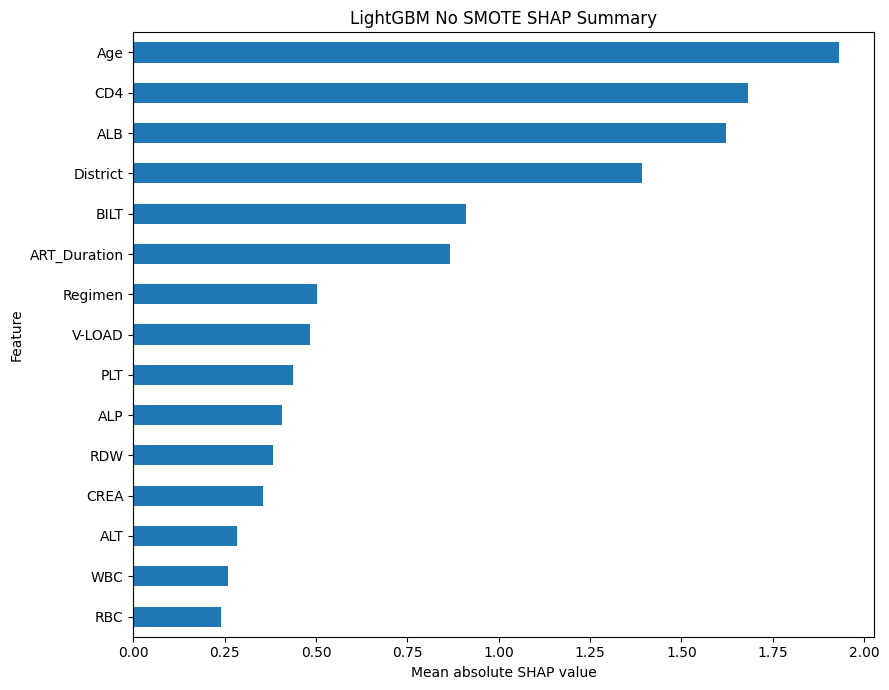

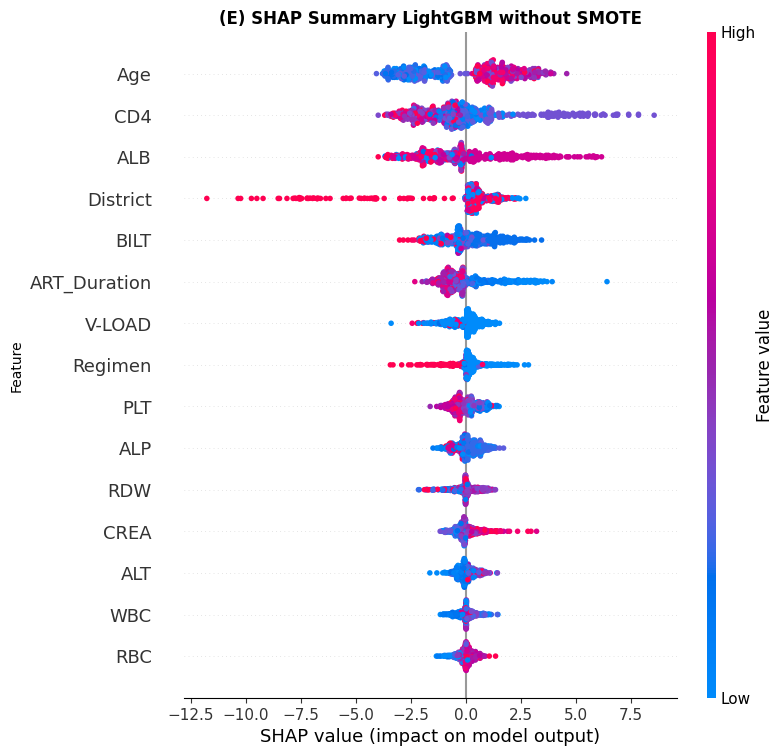


LightGBM_No_SMOTE: Top 15 original features
Original_Feature
Age             1.930094
CD4             1.682600
ALB             1.622125
District        1.390946
BILT            0.909438
ART_Duration    0.867157
Regimen         0.502255
V-LOAD          0.484090
PLT             0.436685
ALP             0.405363
RDW             0.381813
CREA            0.355356
ALT             0.284633
WBC             0.258983
RBC             0.238669
Name: Abs_SHAP, dtype: float64


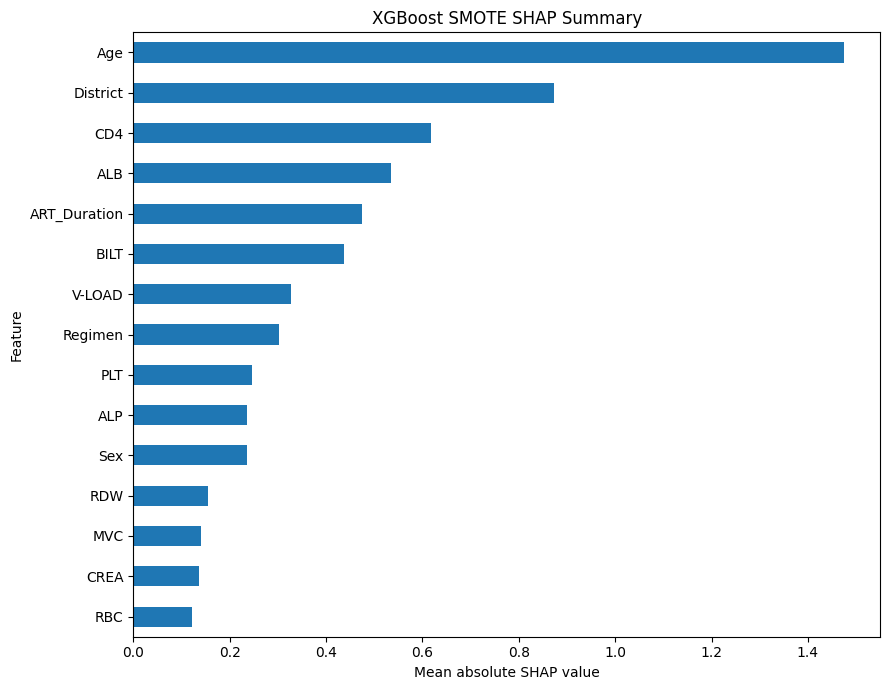

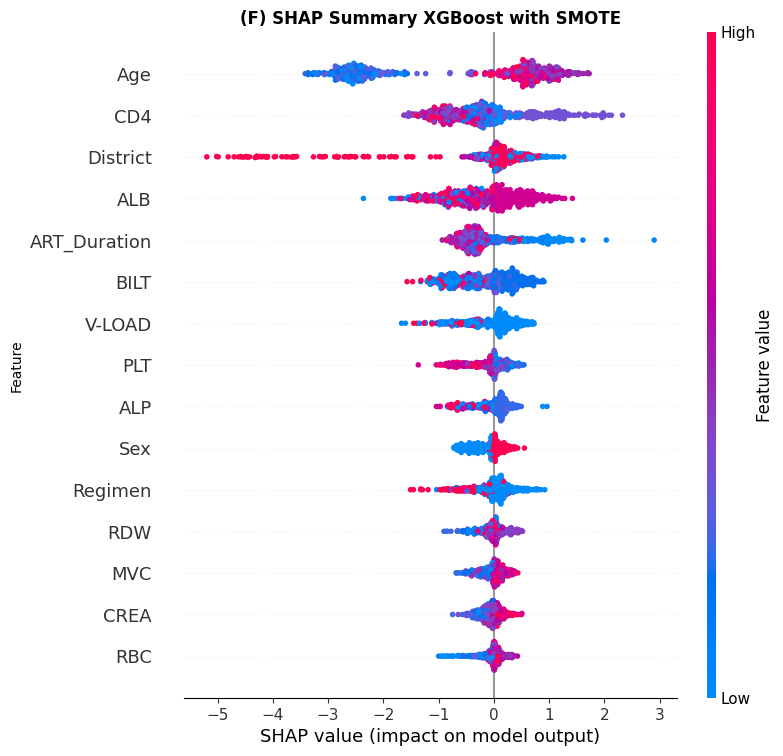


XGBoost_SMOTE: Top 15 original features
Original_Feature
Age             1.475887
District        0.872758
CD4             0.618295
ALB             0.535624
ART_Duration    0.474933
BILT            0.436311
V-LOAD          0.327330
Regimen         0.303166
PLT             0.247054
ALP             0.236159
Sex             0.235009
RDW             0.154687
MVC             0.139738
CREA            0.136854
RBC             0.121942
Name: Abs_SHAP, dtype: float64

Plots and importance CSVs saved in: C:\Users\jnabateesa\Videos\Masterproject\SHAP_selected_models_nested_CV


In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
from pathlib import Path

# ============================================================
# Paths
# ============================================================

OUTPUT_DIR = Path("SHAP_selected_models_nested_CV")

shap_file = OUTPUT_DIR / "Combined_OOF_SHAP_values.csv"

if not shap_file.exists():
    raise FileNotFoundError(
        f"Cannot find {shap_file}. "
        "The previous script must first generate "
        "Combined_OOF_SHAP_values.csv."
    )

df = pd.read_csv(shap_file)

# ============================================================
# Map transformed feature names back to original names
# ============================================================

def original_feature_name(name):

    name = str(name)

    if "__" in name:
        name = name.split("__", 1)[1]

    known_features = [
        "HBsAg_Status",
        "ART_Duration",
        "V-LOAD",
        "Age",
        "Sex",
        "District",
        "Regimen",
        "WBC",
        "HGB",
        "HCT",
        "PLT",
        "MCH",
        "MCHC",
        "MVC",
        "NE#",
        "LY#",
        "RBC",
        "RDW",
        "CREA",
        "BILT",
        "ALB",
        "CD4",
        "ALP",
        "AST",
        "ALT"
    ]

    for feature in sorted(known_features, key=len, reverse=True):
        if name == feature or name.startswith(feature + "_"):
            return feature

    return name


df["Original_Feature"] = df["Feature"].apply(
    original_feature_name
)

# ============================================================
# Aggregate SHAP values across one-hot encoded variables
# ============================================================

grouped = (
    df.groupby(
        ["Model", "Row_Index", "Original_Feature"],
        as_index=False
    )
    .agg(
        SHAP_Value=("SHAP_Value", "sum"),
        Abs_SHAP=("Abs_SHAP", "sum")
    )
)

# ============================================================
# Load original dataset
# ============================================================

possible_files = [
    Path("dataset_after_feature_removal.csv"),
    Path("dataset_after_feature_removal,csv")
]

data_path = next(
    (p for p in possible_files if p.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        "Original dataset not found."
    )

original_df = pd.read_csv(data_path)

target = "HBsAg_Status"

original_df = original_df.copy()
original_df.index.name = "Row_Index"

original_long = (
    original_df
    .drop(columns=[target], errors="ignore")
    .reset_index()
    .melt(
        id_vars="Row_Index",
        var_name="Original_Feature",
        value_name="Feature_Value"
    )
)

grouped = grouped.merge(
    original_long,
    on=["Row_Index", "Original_Feature"],
    how="left"
)

grouped = grouped[
    grouped["Original_Feature"] != target
].copy()

# ============================================================
# Generate plots
# ============================================================

for model in [
    "LightGBM_No_SMOTE",
    "XGBoost_SMOTE"
]:

    model_df = grouped[
        grouped["Model"] == model
    ].copy()

    if model_df.empty:
        print(f"No SHAP records found for {model}")
        continue

    # --------------------------------------------------------
    # Feature importance
    # --------------------------------------------------------

    importance = (
        model_df.groupby("Original_Feature")["Abs_SHAP"]
        .mean()
        .sort_values(ascending=False)
    )

    top15 = importance.head(15).index.tolist()

    importance.head(15).rename(
        "Mean_Absolute_SHAP"
    ).to_csv(
        OUTPUT_DIR /
        f"{model}_Top15_SHAP_importance.csv"
    )

    plot_df = model_df[
        model_df["Original_Feature"].isin(top15)
    ].copy()

    # --------------------------------------------------------
    # Bar plot
    # --------------------------------------------------------

    bar_values = (
        plot_df.groupby("Original_Feature")
        ["Abs_SHAP"]
        .mean()
        .reindex(top15)
        .sort_values()
    )

    fig, ax = plt.subplots(figsize=(9, 7))

    bar_values.plot(
        kind="barh",
        ax=ax
    )

    ax.set_xlabel("Mean absolute SHAP value")
    ax.set_ylabel("Feature")
    ax.set_title(
        f"{model.replace('_', ' ')} SHAP Summary"
    )

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR /
        f"{model}_Top15_SHAP_bar.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # Beeswarm data
    # --------------------------------------------------------

    shap_wide = (
        plot_df.pivot(
            index="Row_Index",
            columns="Original_Feature",
            values="SHAP_Value"
        )
        .reindex(columns=top15)
    )

    value_wide = (
        plot_df.pivot(
            index="Row_Index",
            columns="Original_Feature",
            values="Feature_Value"
        )
        .reindex(columns=top15)
    )

    valid = shap_wide.columns[
        shap_wide.notna().any(axis=0)
    ]

    shap_wide = shap_wide[valid].fillna(0)
    value_wide = value_wide[valid]

    # --------------------------------------------------------
    # Convert values to numeric for color gradient
    # --------------------------------------------------------

    value_wide_fixed = pd.DataFrame(
        index=value_wide.index
    )

    for col in value_wide.columns:

        numeric_col = pd.to_numeric(
            value_wide[col],
            errors="coerce"
        )

        # Numeric variable
        if numeric_col.notna().sum() > 0:

            value_wide_fixed[col] = numeric_col

            median_value = np.nanmedian(
                numeric_col
            )

            value_wide_fixed[col] = (
                value_wide_fixed[col]
                .fillna(median_value)
            )

        # Categorical variable
        else:

            value_wide_fixed[col] = (
                value_wide[col]
                .astype(str)
                .astype("category")
                .cat.codes
            )

    value_wide_fixed = value_wide_fixed.astype(float)

    # --------------------------------------------------------
    # Beeswarm plot
    # --------------------------------------------------------

    plt.figure(figsize=(10, 8))

    shap.summary_plot(
        shap_wide.values,
        value_wide_fixed.values,
        feature_names=shap_wide.columns.tolist(),
        max_display=15,
        show=False,
        color_bar=True
    )

    plt.title(
        "(E) SHAP Summary LightGBM without SMOTE"
        if model == "LightGBM_No_SMOTE"
        else "(F) SHAP Summary XGBoost with SMOTE",
        fontweight="bold"
    )

    plt.ylabel("Feature")

    plt.savefig(
        OUTPUT_DIR /
        f"{model}_Top15_SHAP_beeswarm.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(f"\n{model}: Top 15 original features")
    print(importance.head(15))

print(
    "\nPlots and importance CSVs saved in:",
    OUTPUT_DIR.resolve()
)

# Nested 5 fold cross-validation and hyperparameter tuning
## All preprocessing operations, including missing-value imputation and feature scaling where applicable, were incorporated within the cross-validation pipeline and fitted using training data only

In [69]:
# ============================================================
# COMPLETE NESTED 5-FOLD CROSS-VALIDATION
# Reviewer 5 - Comments 1, 3 and 4
# ============================================================



from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from scipy.stats import t

from sklearn.metrics import (
    matthews_corrcoef,
    roc_auc_score,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier



# SETTINGS

SEED = 42

# Outer 5-fold CV
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# Inner 5-fold CV
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)



#  DATA


X = df_analysis.drop(columns=['HBsAg_Status']).copy()
y = df_analysis['HBsAg_Status'].copy()

print("Dataset shape:", X.shape)
print("Outcome distribution:")
print(y.value_counts())



#  DEFINE VARIABLES

categorical_features = [
    'District',
    'Sex',
    'Regimen'
]

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]



# STANDARDIZE CATEGORICAL TEXT


for col in ['District', 'Regimen']:

    X[col] = (
        X[col]
        .astype('string')
        .str.strip()
        .replace({
            'unknown': 'Unknown',
            'UNKNOWN': 'Unknown',
            'UNK': 'Unknown',
            'N/A': 'Unknown',
            'NA': 'Unknown',
            '': 'Unknown'
        })
    )


X['Sex'] = (
    X['Sex']
    .astype('string')
    .str.strip()
    .str.upper()
)



#  PREPROCESSING PIPELINES


# Numerical preprocessing for models requiring scaling
numeric_scaled = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# Numerical preprocessing for tree-based models
numeric_unscaled = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])


# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        drop=None
    ))
])


# Preprocessor for Logistic Regression and SVM
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', numeric_scaled, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)


# Preprocessor for tree-based models
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ('num', numeric_unscaled, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)



#  DEFINE THE 8 MODELS


models = {

    "Logistic Regression": LogisticRegression(
        max_iter=5000,
        random_state=SEED
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=SEED
    ),

    "Random Forest": RandomForestClassifier(
        random_state=SEED,
        n_jobs=1
    ),

    "SVM": SVC(
        probability=True,
        random_state=SEED
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=SEED
    ),

    "XGBoost": XGBClassifier(
        eval_metric='logloss',
        random_state=SEED,
        n_jobs=1
    ),

    "LightGBM": LGBMClassifier(
        random_state=SEED,
        n_jobs=1,
        verbosity=-1
    ),

    "CatBoost": CatBoostClassifier(
        verbose=0,
        random_seed=SEED,
        thread_count=1
    )
}



#  DEFINE HYPERPARAMETER GRIDS


param_grids = {

    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100]
    },

    "Decision Tree": {
        "classifier__max_depth": [None, 3, 5, 10, 20],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 2, 5],
        "classifier__criterion": ["gini", "entropy"]
    },

    "Random Forest": {
        "classifier__n_estimators": [200, 500],
        "classifier__max_depth": [None, 5, 10, 20],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 2, 5],
        "classifier__max_features": ["sqrt", "log2"]
    },

    "SVM": {
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", 0.001, 0.01, 0.1],
        "classifier__kernel": ["rbf"]
    },

    "Gradient Boosting": {
        "classifier__n_estimators": [100, 200],
        "classifier__learning_rate": [0.01, 0.05, 0.1],
        "classifier__max_depth": [1, 3, 5],
        "classifier__min_samples_split": [2, 5, 10]
    },

    "XGBoost": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [3, 5, 7],
        "classifier__learning_rate": [0.01, 0.05, 0.1],
        "classifier__subsample": [0.8, 1.0],
        "classifier__colsample_bytree": [0.8, 1.0]
    },

    "LightGBM": {
        "classifier__n_estimators": [100, 200],
        "classifier__num_leaves": [15, 31, 63],
        "classifier__learning_rate": [0.01, 0.05, 0.1],
        "classifier__max_depth": [-1, 5, 10],
        "classifier__min_child_samples": [10, 20, 30]
    },

    "CatBoost": {
        "classifier__iterations": [100, 200],
        "classifier__depth": [4, 6, 8],
        "classifier__learning_rate": [0.01, 0.05, 0.1],
        "classifier__l2_leaf_reg": [1, 3, 5]
    }
}



#  IDENTIFY WHICH MODELS REQUIRE SCALING

scaled_models = [
    "Logistic Regression",
    "SVM"
]



# FUNCTION TO CALCULATE OUTER-FOLD METRICS

def calculate_metrics(y_true, y_pred, y_prob):

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    # Metrics
    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    sensitivity = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    specificity = tn / (tn + fp)

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Sensitivity': sensitivity,
        'Specificity': specificity,
        'F1': f1,
        'MCC': mcc,
        'ROC_AUC': auc
    }


#  STORAGE FOR RESULTS

all_results = []
all_predictions = []
all_best_params = []


#  RUN NESTED CV


for model_name, model in models.items():

    print("\n" + "=" * 70)
    print(f"MODEL: {model_name}")
    print("=" * 70)

    # Select appropriate preprocessor
    if model_name in scaled_models:
        preprocessor = preprocessor_scaled
    else:
        preprocessor = preprocessor_unscaled


    # --------------------------------------------------------
    # Run BOTH no-SMOTE and SMOTE versions
    # --------------------------------------------------------

    for use_smote in [False, True]:

        condition = "SMOTE" if use_smote else "No_SMOTE"

        print(f"\n>>> {model_name} - {condition}")


        # ----------------------------------------------------
        # Build pipeline
        # ----------------------------------------------------
            # SMOTE is inside the pipeline, it is applied only to the training portion of each inner CV split
            # To avoided the important data-leakage problem.
        if use_smote:

            pipeline = ImbPipeline(steps=[
                ('preprocessor', preprocessor),
                ('smote', SMOTE(
                    random_state=SEED
                )),
                ('classifier', model)
            ])

        else:

            pipeline = ImbPipeline(steps=[
                ('preprocessor', preprocessor),
                ('classifier', model)
            ])


        # ----------------------------------------------------
        # Inner GridSearchCV
        # ----------------------------------------------------

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids[model_name],
            scoring='matthews_corrcoef',
            cv=inner_cv,
            refit=True,
            n_jobs=-1
        )


        # ----------------------------------------------------
        # Outer 5-fold CV
        # ----------------------------------------------------

        for fold, (train_idx, test_idx) in enumerate(
            outer_cv.split(X, y),
            start=1
        ):

            print(
                f"  Outer fold {fold}/5..."
            )

            X_train = X.iloc[train_idx]
            X_test = X.iloc[test_idx]

            y_train = y.iloc[train_idx]
            y_test = y.iloc[test_idx]


            # ----------------------------------------------
            # Hyperparameter tuning ONLY within outer
            # training data
            # ----------------------------------------------

            grid_search.fit(
                X_train,
                y_train
            )


            # Best hyperparameters
            best_params = grid_search.best_params_

            all_best_params.append({
                'Model': model_name,
                'Condition': condition,
                'Outer_Fold': fold,
                'Best_Inner_MCC': grid_search.best_score_,
                'Best_Parameters': str(best_params)
            })


            # ----------------------------------------------
            # Predict untouched outer validation fold
            # ----------------------------------------------

            y_pred = grid_search.predict(
                X_test
            )

            y_prob = grid_search.predict_proba(
                X_test
            )[:, 1]


            # ----------------------------------------------
            # Calculate outer-fold metrics
            # ----------------------------------------------

            metrics = calculate_metrics(
                y_test,
                y_pred,
                y_prob
            )


            # ----------------------------------------------
            # Store metrics
            # ----------------------------------------------

            result = {
                'Model': model_name,
                'Condition': condition,
                'Outer_Fold': fold,
                **metrics
            }

            all_results.append(result)


            # ----------------------------------------------
            # Store out-of-fold predictions
            # ----------------------------------------------

            for idx, true_value, pred_value, probability in zip(
                test_idx,
                y_test,
                y_pred,
                y_prob
            ):

                all_predictions.append({
                    'Model': model_name,
                    'Condition': condition,
                    'Row_Index': idx,
                    'y_true': true_value,
                    'y_pred': pred_value,
                    'y_probability': probability
                })


        print(
            f"  Completed: {model_name} - {condition}"
        )



#  CONVERT RESULTS TO DATAFRAMES


nested_cv_results = pd.DataFrame(
    all_results
)

nested_cv_predictions = pd.DataFrame(
    all_predictions
)

nested_cv_best_params = pd.DataFrame(
    all_best_params
)



#  DISPLAY OUTER-FOLD RESULTS


print("\n\nOUTER-FOLD RESULTS")
print("=" * 70)

print(
    nested_cv_results.to_string(index=False)
)


#  SUMMARIZE OUTER-FOLD PERFORMANCE


# ============================================================
# CALCULATE MEAN AND 95% CI FROM THE 5 OUTER FOLDS
# ============================================================

metrics_to_summarize = [
    'Accuracy',
    'Precision',
    'Sensitivity',
    'Specificity',
    'F1',
    'MCC',
    'ROC_AUC'
]


def mean_ci(values, confidence=0.95):

    values = np.asarray(values, dtype=float)

    n = len(values)

    if n != 5:
        raise ValueError(
            f"Expected 5 outer-fold values, but found {n}."
        )



    mean = np.mean(values)

    sd = np.std(
        values,
        ddof=1
    )

    se = sd / np.sqrt(n)

    # t critical value
    t_critical = t.ppf(
        (1 + confidence) / 2,
        df=n - 1
    )

    margin = t_critical * se

    lower = mean - margin
    upper = mean + margin

    return mean, lower, upper


summary_rows = []


for (model, condition), group in nested_cv_results.groupby(
    ['Model', 'Condition']
):

    row = {
        'Model': model,
        'Condition': condition
    }

    for metric in metrics_to_summarize:

        mean, lower, upper = mean_ci(
            group[metric].values
        )

        row[f'{metric}_Mean'] = mean
        row[f'{metric}_CI_Lower'] = lower
        row[f'{metric}_CI_Upper'] = upper

    summary_rows.append(row)


nested_cv_ci_summary = pd.DataFrame(
    summary_rows
)


# ============================================================
# CREATE MANUSCRIPT-READY FORMAT
# ============================================================

def format_ci(mean, lower, upper):

    # Keep values within 0–1
    lower = max(0, lower)
    upper = min(1, upper)

    return f"{mean:.3f} ({lower:.3f}-{upper:.3f})"


manuscript_rows = []


for _, row in nested_cv_ci_summary.iterrows():

    manuscript_rows.append({
        'Model': row['Model'],
        'Condition': row['Condition'],

        'Accuracy (95% CI)': format_ci(
            row['Accuracy_Mean'],
            row['Accuracy_CI_Lower'],
            row['Accuracy_CI_Upper']
        ),

        'Precision (95% CI)': format_ci(
            row['Precision_Mean'],
            row['Precision_CI_Lower'],
            row['Precision_CI_Upper']
        ),

        'Sensitivity (95% CI)': format_ci(
            row['Sensitivity_Mean'],
            row['Sensitivity_CI_Lower'],
            row['Sensitivity_CI_Upper']
        ),

        'Specificity (95% CI)': format_ci(
            row['Specificity_Mean'],
            row['Specificity_CI_Lower'],
            row['Specificity_CI_Upper']
        ),

        'F1 Score (95% CI)': format_ci(
            row['F1_Mean'],
            row['F1_CI_Lower'],
            row['F1_CI_Upper']
        ),

        'MCC (95% CI)': format_ci(
            row['MCC_Mean'],
            row['MCC_CI_Lower'],
            row['MCC_CI_Upper']
        ),

        'ROC AUC (95% CI)': format_ci(
            row['ROC_AUC_Mean'],
            row['ROC_AUC_CI_Lower'],
            row['ROC_AUC_CI_Upper']
        )
    })


nested_cv_manuscript_table = pd.DataFrame(
    manuscript_rows
)


print("\n\nMANUSCRIPT-READY NESTED CV RESULTS")
print("=" * 100)

print(
    nested_cv_manuscript_table.to_string(index=False)
)

# ============================================================
# 15. SAVE RESULTS
# ============================================================

nested_cv_results.to_csv(
    "nested_cv_outer_fold_results.csv",
    index=False
)

nested_cv_predictions.to_csv(
    "nested_cv_out_of_fold_predictions.csv",
    index=False
)

nested_cv_best_params.to_csv(
    "nested_cv_best_parameters.csv",
    index=False
)

nested_cv_manuscript_table.to_csv(
    "nested_cv_manuscript_performance.csv",
    index=False
)

print(
    "\nSaved: nested_cv_manuscript_performance.csv"
)



print("\n\nFiles saved successfully:")
print("1. nested_cv_outer_fold_results.csv")
print("2. nested_cv_out_of_fold_predictions.csv")
print("3. nested_cv_best_parameters.csv")
print("4. nested_cv_manuscript_performance.csv")

Dataset shape: (634, 24)
Outcome distribution:
HBsAg_Status
0    464
1    170
Name: count, dtype: int64

MODEL: Logistic Regression

>>> Logistic Regression - No_SMOTE
  Outer fold 1/5...
  Outer fold 2/5...
  Outer fold 3/5...
  Outer fold 4/5...
  Outer fold 5/5...
  Completed: Logistic Regression - No_SMOTE

>>> Logistic Regression - SMOTE
  Outer fold 1/5...
  Outer fold 2/5...
  Outer fold 3/5...
  Outer fold 4/5...
  Outer fold 5/5...
  Completed: Logistic Regression - SMOTE

MODEL: Decision Tree

>>> Decision Tree - No_SMOTE
  Outer fold 1/5...
  Outer fold 2/5...
  Outer fold 3/5...
  Outer fold 4/5...
  Outer fold 5/5...
  Completed: Decision Tree - No_SMOTE

>>> Decision Tree - SMOTE
  Outer fold 1/5...
  Outer fold 2/5...
  Outer fold 3/5...
  Outer fold 4/5...
  Outer fold 5/5...
  Completed: Decision Tree - SMOTE

MODEL: Random Forest

>>> Random Forest - No_SMOTE
  Outer fold 1/5...
  Outer fold 2/5...
  Outer fold 3/5...
  Outer fold 4/5...
  Outer fold 5/5...
  Complete

# Confusion Matrix With SMOTE and Without SMOTE

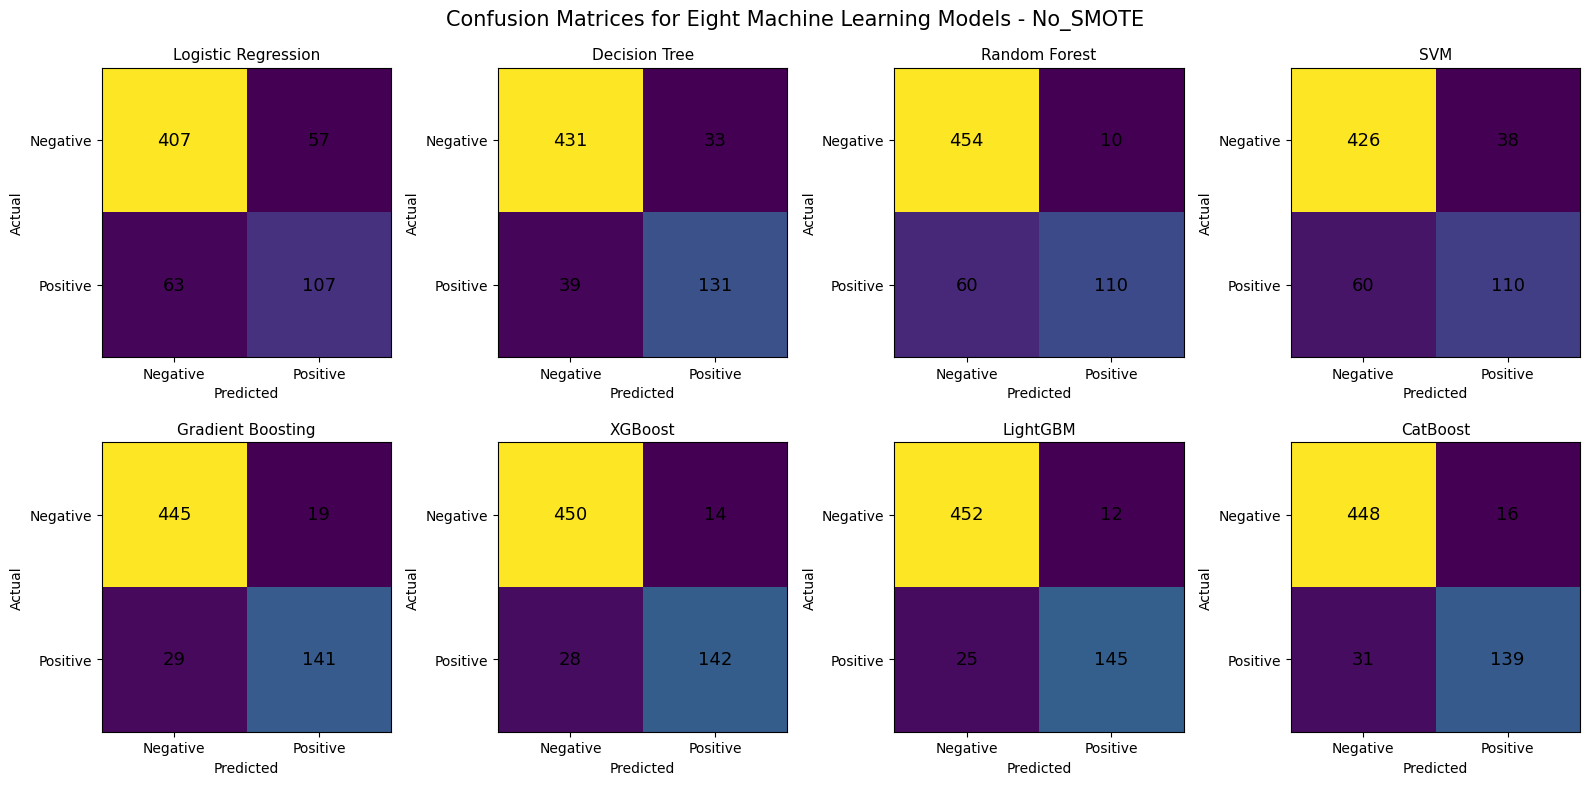

Saved: confusion_matrices_all_8_models_No_SMOTE.png


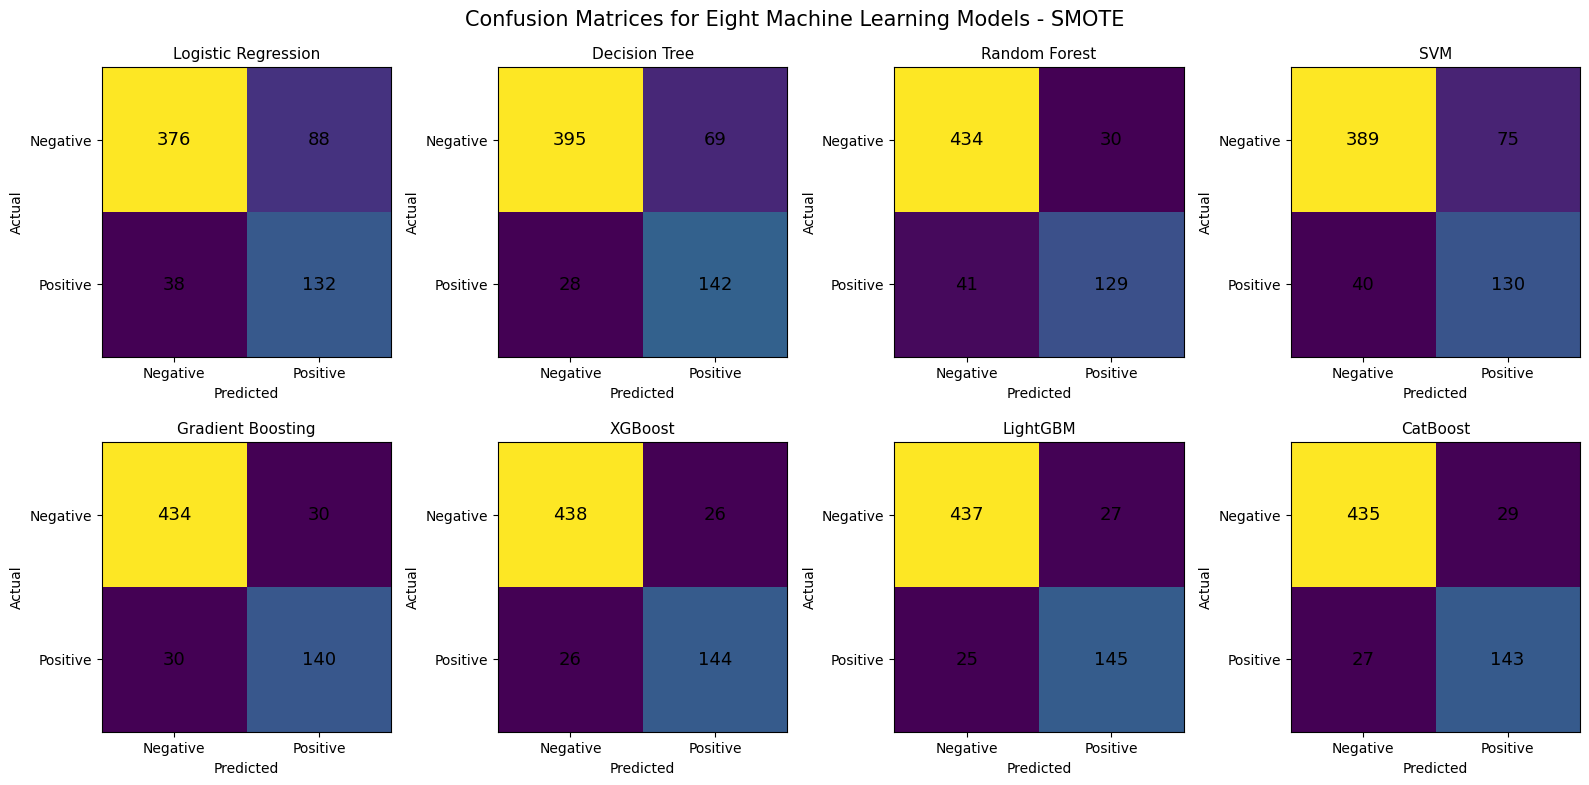

Saved: confusion_matrices_all_8_models_SMOTE.png


In [82]:
# ============================================================
# ONE FIGURE WITH ALL 8 MODELS
# NO-SMOTE AND SMOTE
# ============================================================

import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt


# ============================================================
# 1. LOAD THE COPIED OUT-OF-FOLD PREDICTIONS
# ============================================================

copy_file = "nested_cv_out_of_fold_predictions_CONFUSION_MATRIX_COPY.csv"

df_pred = pd.read_csv(copy_file)


# ============================================================
# 2. MODEL ORDER
# ============================================================

model_order = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "SVM",
    "Gradient Boosting",
    "XGBoost",
    "LightGBM",
    "CatBoost"
]


# ============================================================
# 3. FUNCTION TO CREATE ONE 8-MODEL FIGURE
# ============================================================

def plot_all_confusion_matrices(df, condition):

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(16, 8)
    )

    axes = axes.flatten()

    for i, model in enumerate(model_order):

        ax = axes[i]

        group = df[
            (df["Model"] == model) &
            (df["Condition"] == condition)
        ]

        y_true = group["y_true"].astype(int)
        y_pred = group["y_pred"].astype(int)

        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        )

        # Plot matrix
        ax.imshow(cm)

        ax.set_title(model, fontsize=11)

        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])

        ax.set_xticklabels(["Negative", "Positive"])
        ax.set_yticklabels(["Negative", "Positive"])

        # Add numbers
        for row in range(2):
            for col in range(2):

                ax.text(
                    col,
                    row,
                    str(cm[row, col]),
                    ha="center",
                    va="center",
                    fontsize=13
                )

    # Overall title
    fig.suptitle(
        f"Confusion Matrices for Eight Machine Learning Models - {condition}",
        fontsize=15
    )

    plt.tight_layout()

    # Save figure
    filename = (
        f"confusion_matrices_all_8_models_{condition}.png"
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"Saved: {filename}")


# ============================================================
# 4. CREATE NO-SMOTE FIGURE
# ============================================================

plot_all_confusion_matrices(
    df_pred,
    "No_SMOTE"
)


# ============================================================
# 5. CREATE SMOTE FIGURE
# ============================================================

plot_all_confusion_matrices(
    df_pred,
    "SMOTE"
)

# ROC Curves for all 8 models with SMOTE and Without SMOTE

LOADED OOF PREDICTIONS
Shape: (10144, 6)

Columns:
['Model', 'Condition', 'Row_Index', 'y_true', 'y_pred', 'y_probability']

First 5 rows:
                 Model Condition  Row_Index  y_true  y_pred  y_probability
0  Logistic Regression  No_SMOTE          0       0       0       0.319236
1  Logistic Regression  No_SMOTE          1       0       0       0.347299
2  Logistic Regression  No_SMOTE          2       0       1       0.736288
3  Logistic Regression  No_SMOTE         10       0       0       0.124884
4  Logistic Regression  No_SMOTE         19       0       0       0.008574

Models found:
['Logistic Regression' 'Decision Tree' 'Random Forest' 'SVM'
 'Gradient Boosting' 'XGBoost' 'LightGBM' 'CatBoost']

Conditions found:
['No_SMOTE' 'SMOTE']

Condition counts:
Condition
No_SMOTE    5072
SMOTE       5072
Name: count, dtype: int64

ROC ANALYSIS — No_SMOTE
Models: ['CatBoost', 'Decision Tree', 'Gradient Boosting', 'LightGBM', 'Logistic Regression', 'Random Forest', 'SVM', 'XGBoost'

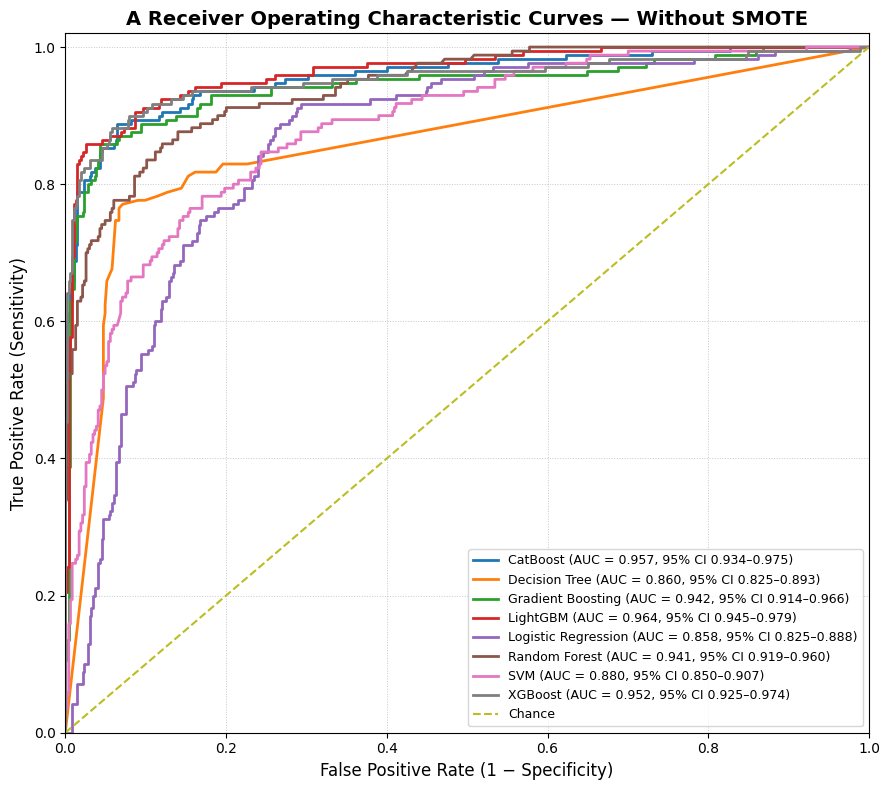


Figure saved to:
ROC_Curves_No_SMOTE.png

ROC ANALYSIS — SMOTE
Models: ['CatBoost', 'Decision Tree', 'Gradient Boosting', 'LightGBM', 'Logistic Regression', 'Random Forest', 'SVM', 'XGBoost']
CatBoost                  AUC = 0.9554 (95% CI: 0.9346–0.9727)
Decision Tree             AUC = 0.8626 (95% CI: 0.8285–0.8946)
Gradient Boosting         AUC = 0.9422 (95% CI: 0.9123–0.9655)
LightGBM                  AUC = 0.9550 (95% CI: 0.9318–0.9740)
Logistic Regression       AUC = 0.8629 (95% CI: 0.8317–0.8930)
Random Forest             AUC = 0.9417 (95% CI: 0.9206–0.9600)
SVM                       AUC = 0.8822 (95% CI: 0.8537–0.9092)
XGBoost                   AUC = 0.9595 (95% CI: 0.9373–0.9770)


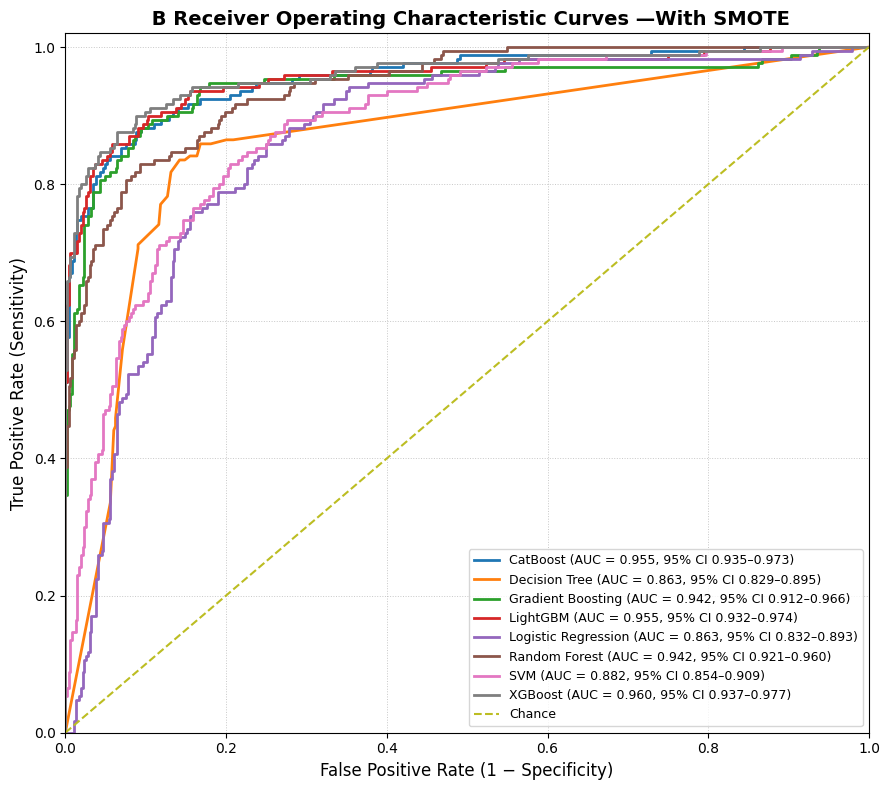


Figure saved to:
ROC_Curves_SMOTE.png

FINAL ROC/AUC RESULTS
Condition               Model   N      AUC  AUC_CI_Lower  AUC_CI_Upper
 No_SMOTE            LightGBM 634 0.963641      0.944660      0.979333
 No_SMOTE            CatBoost 634 0.956871      0.933810      0.974696
 No_SMOTE             XGBoost 634 0.952104      0.925387      0.974141
 No_SMOTE   Gradient Boosting 634 0.942394      0.913598      0.966277
 No_SMOTE       Random Forest 634 0.940879      0.919085      0.960058
 No_SMOTE                 SVM 634 0.879754      0.850119      0.907371
 No_SMOTE       Decision Tree 634 0.860351      0.825387      0.892857
 No_SMOTE Logistic Regression 634 0.857974      0.825058      0.888493
    SMOTE             XGBoost 634 0.959508      0.937285      0.976968
    SMOTE            CatBoost 634 0.955401      0.934645      0.972725
    SMOTE            LightGBM 634 0.954995      0.931820      0.974029
    SMOTE   Gradient Boosting 634 0.942229      0.912302      0.965529
    SMOTE      

In [115]:
# =============================================================================
# ROC CURVES FOR ALL 8 MODELS
# Nested 5-Fold CV — OOF Predictions
# No SMOTE vs SMOTE
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.utils import resample

# =============================================================================
# SETTINGS
# =============================================================================

SEED = 42
N_BOOTSTRAP = 2000

# Input file from your nested CV analysis
INPUT_FILE = "nested_cv_out_of_fold_predictions_COPY.csv"

# Output files
NO_SMOTE_FIG = "ROC_Curves_No_SMOTE.png"
SMOTE_FIG = "ROC_Curves_SMOTE.png"
AUC_RESULTS = "ROC_AUC_Results.csv"

# =============================================================================
# LOAD OOF PREDICTIONS
# =============================================================================

df = pd.read_csv(INPUT_FILE)

print("=" * 80)
print("LOADED OOF PREDICTIONS")
print("=" * 80)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())


# =============================================================================
# IDENTIFY COLUMNS
# =============================================================================

# Expected columns are something similar to:
# Model
# Condition
# Outer_Fold
# Row_Index
# y_true
# y_pred
# y_prob
#
# Adjust these names below if your actual CSV uses different names.


TARGET_COLUMN = "y_true"
PROBABILITY_COLUMN = "y_probability"
MODEL_COLUMN = "Model"
CONDITION_COLUMN = "Condition"


# =============================================================================
# CHECK REQUIRED COLUMNS
# =============================================================================

required_columns = [
    MODEL_COLUMN,
    CONDITION_COLUMN,
    TARGET_COLUMN,
    PROBABILITY_COLUMN
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"\nMissing required columns: {missing_columns}\n"
        f"Available columns are:\n{df.columns.tolist()}"
    )


# =============================================================================
# DISPLAY MODELS AND CONDITIONS
# =============================================================================

print("\nModels found:")
print(df[MODEL_COLUMN].unique())

print("\nConditions found:")
print(df[CONDITION_COLUMN].unique())


# =============================================================================
# STANDARDIZE CONDITION NAMES
# =============================================================================

# This handles common naming variations.

df[CONDITION_COLUMN] = (
    df[CONDITION_COLUMN]
    .astype(str)
    .str.strip()
)

print("\nCondition counts:")
print(df[CONDITION_COLUMN].value_counts())


# =============================================================================
# BOOTSTRAP 95% CI FOR AUC
# =============================================================================

def bootstrap_auc_ci(
    y_true,
    y_prob,
    n_bootstrap=2000,
    seed=42
):
    """
    Calculate bootstrap 95% CI for ROC AUC.
    """

    rng = np.random.RandomState(seed)

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    auc_original = roc_auc_score(y_true, y_prob)

    bootstrap_aucs = []

    n = len(y_true)

    for i in range(n_bootstrap):

        indices = rng.randint(
            0,
            n,
            n
        )

        y_true_boot = y_true[indices]
        y_prob_boot = y_prob[indices]

        # Bootstrap sample must contain both classes
        if len(np.unique(y_true_boot)) < 2:
            continue

        auc_boot = roc_auc_score(
            y_true_boot,
            y_prob_boot
        )

        bootstrap_aucs.append(auc_boot)

    bootstrap_aucs = np.array(bootstrap_aucs)

    lower = np.percentile(
        bootstrap_aucs,
        2.5
    )

    upper = np.percentile(
        bootstrap_aucs,
        97.5
    )

    return auc_original, lower, upper


# =============================================================================
# FUNCTION TO CREATE ROC PLOT
# =============================================================================

def create_roc_plot(
    data,
    condition,
    output_file,
    title
):

    # -------------------------------------------------------------------------
    # Filter condition
    # -------------------------------------------------------------------------

    subset = data[
        data[CONDITION_COLUMN].str.lower()
        == condition.lower()
    ].copy()

    if subset.empty:
        raise ValueError(
            f"No data found for condition: {condition}\n"
            f"Available conditions: "
            f"{data[CONDITION_COLUMN].unique()}"
        )

    # -------------------------------------------------------------------------
    # Models
    # -------------------------------------------------------------------------

    models = sorted(
        subset[MODEL_COLUMN].unique()
    )

    print("\n" + "=" * 80)
    print(f"ROC ANALYSIS — {condition}")
    print("=" * 80)

    print("Models:", models)

    # -------------------------------------------------------------------------
    # Create figure
    # -------------------------------------------------------------------------

    plt.figure(
        figsize=(9, 8)
    )

    auc_results = []

    # -------------------------------------------------------------------------
    # Plot each model
    # -------------------------------------------------------------------------

    for model in models:

        model_data = subset[
            subset[MODEL_COLUMN] == model
        ].copy()

        y_true = model_data[TARGET_COLUMN].values
        y_prob = model_data[PROBABILITY_COLUMN].values

        # ROC
        fpr, tpr, thresholds = roc_curve(
            y_true,
            y_prob
        )

        # AUC
        auc_value = roc_auc_score(
            y_true,
            y_prob
        )

        # Bootstrap CI
        auc_original, ci_lower, ci_upper = bootstrap_auc_ci(
            y_true,
            y_prob,
            n_bootstrap=N_BOOTSTRAP,
            seed=SEED
        )

        # Plot
        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=(
                f"{model} "
                f"(AUC = {auc_value:.3f}, "
                f"95% CI {ci_lower:.3f}–{ci_upper:.3f})"
            )
        )

        # Store results
        auc_results.append({
            "Condition": condition,
            "Model": model,
            "N": len(y_true),
            "AUC": auc_value,
            "AUC_CI_Lower": ci_lower,
            "AUC_CI_Upper": ci_upper
        })

        print(
            f"{model:<25} "
            f"AUC = {auc_value:.4f} "
            f"(95% CI: {ci_lower:.4f}–{ci_upper:.4f})"
        )

    # -------------------------------------------------------------------------
    # Chance line
    # -------------------------------------------------------------------------

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1.5,
        label="Chance"
    )

    # -------------------------------------------------------------------------
    # Labels
    # -------------------------------------------------------------------------

    plt.xlabel(
        "False Positive Rate (1 − Specificity)",
        fontsize=12
    )

    plt.ylabel(
        "True Positive Rate (Sensitivity)",
        fontsize=12
    )

    plt.title(
        title,
        fontsize=14,
        fontweight="bold"
    )

    # -------------------------------------------------------------------------
    # Axis limits
    # -------------------------------------------------------------------------

    plt.xlim(
        0,
        1
    )

    plt.ylim(
        0,
        1.02
    )

    # -------------------------------------------------------------------------
    # Grid
    # -------------------------------------------------------------------------

    plt.grid(
        True,
        linestyle=":",
        linewidth=0.7,
        alpha=0.7
    )

    # -------------------------------------------------------------------------
    # Legend
    # -------------------------------------------------------------------------

    plt.legend(
        loc="lower right",
        fontsize=9,
        frameon=True
    )

    # -------------------------------------------------------------------------
    # Tight layout
    # -------------------------------------------------------------------------

    plt.tight_layout()

    # -------------------------------------------------------------------------
    # Save high-resolution figure
    # -------------------------------------------------------------------------

    plt.savefig(
        output_file,
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

    print(
        f"\nFigure saved to:\n{output_file}"
    )

    return pd.DataFrame(auc_results)


# =============================================================================
# RUN NO-SMOTE ROC ANALYSIS
# =============================================================================

results_no_smote = create_roc_plot(
    data=df,
    condition="No_SMOTE",
    output_file=NO_SMOTE_FIG,
    title="A Receiver Operating Characteristic Curves — Without SMOTE"
)


# =============================================================================
# RUN SMOTE ROC ANALYSIS
# =============================================================================

results_smote = create_roc_plot(
    data=df,
    condition="SMOTE",
    output_file=SMOTE_FIG,
    title=" B Receiver Operating Characteristic Curves — With SMOTE"
)


# =============================================================================
# COMBINE AUC RESULTS
# =============================================================================

auc_results = pd.concat(
    [
        results_no_smote,
        results_smote
    ],
    ignore_index=True
)


# =============================================================================
# SORT RESULTS
# =============================================================================

auc_results = auc_results.sort_values(
    by=["Condition", "AUC"],
    ascending=[True, False]
)


# =============================================================================
# SAVE AUC RESULTS
# =============================================================================

auc_results.to_csv(
    AUC_RESULTS,
    index=False
)


# =============================================================================
# DISPLAY FINAL RESULTS
# =============================================================================

print("\n" + "=" * 80)
print("FINAL ROC/AUC RESULTS")
print("=" * 80)

print(
    auc_results.to_string(
        index=False
    )
)

print("\n" + "=" * 80)
print("FILES CREATED")
print("=" * 80)

print(f"1. {NO_SMOTE_FIG}")
print(f"2. {SMOTE_FIG}")
print(f"3. {AUC_RESULTS}")

# SHAP 

# CI 95% Confidence Interval


In [86]:
# ============================================================
# BOOTSTRAP 95% CI FOR ALL NESTED-CV PERFORMANCE METRICS
# USING POOLED OUT-OF-FOLD PREDICTIONS
# ============================================================

import pandas as pd
import numpy as np
import shutil

from sklearn.metrics import (
    matthews_corrcoef,
    roc_auc_score,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)


# ============================================================
# 0. MAKE A BACKUP COPY OF THE ORIGINAL OOF PREDICTIONS
# ============================================================

original_oof_file = "nested_cv_out_of_fold_predictions.csv"

backup_oof_file = "nested_cv_out_of_fold_predictions_COPY.csv"

shutil.copy2(
    original_oof_file,
    backup_oof_file
)

print("=" * 70)
print("OOF PREDICTIONS BACKUP")
print("=" * 70)

print("Original:")
print(original_oof_file)

print("\nBackup copy:")
print(backup_oof_file)

print("\nBackup created successfully.")
print("The original OOF predictions file has NOT been modified.")


# ============================================================
# 1. LOAD EXISTING OUT-OF-FOLD PREDICTIONS
# ============================================================

oof = pd.read_csv(
    original_oof_file
)

print("\n" + "=" * 70)
print("OUT-OF-FOLD PREDICTIONS")
print("=" * 70)

print("Shape:", oof.shape)

print("\nColumns:")
print(oof.columns.tolist())

print("\nFirst 5 rows:")
print(oof.head())


# ============================================================
# 2. BOOTSTRAP FUNCTION
# ============================================================

def bootstrap_metrics(
    y_true,
    y_pred,
    y_prob,
    n_boot=2000,
    seed=42
):

    rng = np.random.default_rng(seed)

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_prob = np.asarray(y_prob)

    # --------------------------------------------------------
    # Separate outcome classes
    # --------------------------------------------------------

    negative_idx = np.where(y_true == 0)[0]
    positive_idx = np.where(y_true == 1)[0]

    results = {
        "MCC": [],
        "ROC_AUC": [],
        "Accuracy": [],
        "Precision": [],
        "Sensitivity": [],
        "Specificity": [],
        "F1": []
    }

    # --------------------------------------------------------
    # Bootstrap
    # --------------------------------------------------------

    for _ in range(n_boot):

        boot_negative = rng.choice(
            negative_idx,
            size=len(negative_idx),
            replace=True
        )

        boot_positive = rng.choice(
            positive_idx,
            size=len(positive_idx),
            replace=True
        )

        boot_idx = np.concatenate([
            boot_negative,
            boot_positive
        ])

        yt = y_true[boot_idx]
        yp = y_pred[boot_idx]
        ypr = y_prob[boot_idx]

        # ----------------------------------------------------
        # MCC
        # ----------------------------------------------------

        mcc = matthews_corrcoef(
            yt,
            yp
        )

        # ----------------------------------------------------
        # ROC AUC
        # ----------------------------------------------------

        auc = roc_auc_score(
            yt,
            ypr
        )

        # ----------------------------------------------------
        # Accuracy
        # ----------------------------------------------------

        accuracy = accuracy_score(
            yt,
            yp
        )

        # ----------------------------------------------------
        # Precision
        # ----------------------------------------------------

        precision = precision_score(
            yt,
            yp,
            zero_division=0
        )

        # ----------------------------------------------------
        # Sensitivity
        # ----------------------------------------------------

        sensitivity = recall_score(
            yt,
            yp,
            zero_division=0
        )

        # ----------------------------------------------------
        # Specificity
        # ----------------------------------------------------

        tn, fp, fn, tp = confusion_matrix(
            yt,
            yp,
            labels=[0, 1]
        ).ravel()

        specificity = tn / (tn + fp)

        # ----------------------------------------------------
        # F1
        # ----------------------------------------------------

        f1 = f1_score(
            yt,
            yp,
            zero_division=0
        )

        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------

        results["MCC"].append(mcc)
        results["ROC_AUC"].append(auc)
        results["Accuracy"].append(accuracy)
        results["Precision"].append(precision)
        results["Sensitivity"].append(sensitivity)
        results["Specificity"].append(specificity)
        results["F1"].append(f1)

    # ========================================================
    # 95% PERCENTILE CONFIDENCE INTERVALS
    # ========================================================

    ci_results = {}

    for metric, values in results.items():

        values = np.asarray(values)

        ci_results[metric] = {
            "Lower_95CI": np.percentile(
                values,
                2.5
            ),
            "Upper_95CI": np.percentile(
                values,
                97.5
            )
        }

    return ci_results


# ============================================================
# 3. RUN BOOTSTRAP FOR EVERY MODEL AND CONDITION
# ============================================================

all_results = []

for (model, condition), group in oof.groupby(
    ["Model", "Condition"]
):

    print(
        f"Processing: {model} | {condition}"
    )

    ci = bootstrap_metrics(
        y_true=group["y_true"],
        y_pred=group["y_pred"],
        y_prob=group["y_probability"],
        n_boot=2000,
        seed=42
    )

    row = {
        "Model": model,
        "Condition": condition
    }

    for metric in [
        "MCC",
        "ROC_AUC",
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1"
    ]:

        row[f"{metric}_Lower_95CI"] = (
            ci[metric]["Lower_95CI"]
        )

        row[f"{metric}_Upper_95CI"] = (
            ci[metric]["Upper_95CI"]
        )

    all_results.append(row)


# ============================================================
# 4. CREATE CI RESULTS DATAFRAME
# ============================================================

ci_results = pd.DataFrame(
    all_results
)

print("\n" + "=" * 70)
print("BOOTSTRAP CI RESULTS")
print("=" * 70)

print(
    ci_results.to_string(index=False)
)


# ============================================================
# 5. FORMAT CI AS LOWER–UPPER
# ============================================================

for metric in [
    "MCC",
    "ROC_AUC",
    "Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1"
]:

    ci_results[metric] = (
        ci_results[
            f"{metric}_Lower_95CI"
        ].round(3).astype(str)
        + "-"
        + 
        ci_results[
            f"{metric}_Upper_95CI"
        ].round(3).astype(str)
    )


# ============================================================
# 6. FINAL MANUSCRIPT TABLE
# ============================================================

final_ci_table = ci_results[
    [
        "Model",
        "Condition",
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1",
        "MCC",
        "ROC_AUC"
    ]
]


print("\n" + "=" * 70)
print("FINAL BOOTSTRAP 95% CI TABLE")
print("=" * 70)

print(
    final_ci_table.to_string(index=False)
)


# ============================================================
# 7. SAVE RESULTS
# ============================================================

final_ci_table.to_csv(
    "nested_cv_bootstrap_95CI_all_metrics2.csv",
    index=False
)

print("\nSaved:")
print(
    "nested_cv_bootstrap_95CI_all_metrics.csv"
)

OOF PREDICTIONS BACKUP
Original:
nested_cv_out_of_fold_predictions.csv

Backup copy:
nested_cv_out_of_fold_predictions_COPY.csv

Backup created successfully.
The original OOF predictions file has NOT been modified.

OUT-OF-FOLD PREDICTIONS
Shape: (10144, 6)

Columns:
['Model', 'Condition', 'Row_Index', 'y_true', 'y_pred', 'y_probability']

First 5 rows:
                 Model Condition  Row_Index  y_true  y_pred  y_probability
0  Logistic Regression  No_SMOTE          0       0       0       0.319236
1  Logistic Regression  No_SMOTE          1       0       0       0.347299
2  Logistic Regression  No_SMOTE          2       0       1       0.736288
3  Logistic Regression  No_SMOTE         10       0       0       0.124884
4  Logistic Regression  No_SMOTE         19       0       0       0.008574
Processing: CatBoost | No_SMOTE
Processing: CatBoost | SMOTE
Processing: Decision Tree | No_SMOTE
Processing: Decision Tree | SMOTE
Processing: Gradient Boosting | No_SMOTE
Processing: Gradient 

# New with point estimates


In [87]:
# ============================================================
# 3. RUN BOOTSTRAP FOR EVERY MODEL AND CONDITION
#    INCLUDING POINT ESTIMATES
# ============================================================

all_results = []

for (model, condition), group in oof.groupby(
    ["Model", "Condition"]
):

    print(
        f"Processing: {model} | {condition}"
    )

    # --------------------------------------------------------
    # Original pooled OOF predictions
    # --------------------------------------------------------

    y_true = group["y_true"].to_numpy()
    y_pred = group["y_pred"].to_numpy()
    y_prob = group["y_probability"].to_numpy()

    # --------------------------------------------------------
    # POINT ESTIMATES FROM POOLED OOF PREDICTIONS
    # --------------------------------------------------------

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    sensitivity = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp)

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # --------------------------------------------------------
    # BOOTSTRAP 95% CI
    # --------------------------------------------------------

    ci = bootstrap_metrics(
        y_true=y_true,
        y_pred=y_pred,
        y_prob=y_prob,
        n_boot=2000,
        seed=42
    )

    # --------------------------------------------------------
    # STORE POINT ESTIMATES + CI
    # --------------------------------------------------------

    row = {
        "Model": model,
        "Condition": condition,

        "Accuracy_Point": accuracy,
        "Precision_Point": precision,
        "Sensitivity_Point": sensitivity,
        "Specificity_Point": specificity,
        "F1_Point": f1,
        "MCC_Point": mcc,
        "ROC_AUC_Point": auc
    }

    # --------------------------------------------------------
    # ADD LOWER AND UPPER CI
    # --------------------------------------------------------

    for metric in [
        "MCC",
        "ROC_AUC",
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1"
    ]:

        row[f"{metric}_Lower_95CI"] = (
            ci[metric]["Lower_95CI"]
        )

        row[f"{metric}_Upper_95CI"] = (
            ci[metric]["Upper_95CI"]
        )

    all_results.append(row)


# ============================================================
# 4. CREATE RESULTS DATAFRAME
# ============================================================

ci_results = pd.DataFrame(
    all_results
)

print("\n" + "=" * 70)
print("BOOTSTRAP RESULTS WITH POINT ESTIMATES")
print("=" * 70)

print(
    ci_results.to_string(index=False)
)


# ============================================================
# 5. FORMAT POINT ESTIMATE + 95% CI
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1",
    "MCC",
    "ROC_AUC"
]

for metric in metrics:

    ci_results[metric] = (
        ci_results[f"{metric}_Point"].round(3).astype(str)
        + " ("
        + ci_results[f"{metric}_Lower_95CI"].round(3).astype(str)
        + "-"
        + ci_results[f"{metric}_Upper_95CI"].round(3).astype(str)
        + ")"
    )


# ============================================================
# 6. FINAL MANUSCRIPT TABLE
# ============================================================

final_ci_table = ci_results[
    [
        "Model",
        "Condition",
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1",
        "MCC",
        "ROC_AUC"
    ]
]


print("\n" + "=" * 70)
print("FINAL BOOTSTRAP MANUSCRIPT TABLE")
print("=" * 70)

print(
    final_ci_table.to_string(index=False)
)


# ============================================================
# 7. SAVE RESULTS
# ============================================================

final_ci_table.to_csv(
    "nested_cv_bootstrap_95CI_all_metrics_with_point_estimates.csv",
    index=False
)

print("\nSaved:")
print(
    "nested_cv_bootstrap_95CI_all_metrics_with_point_estimates.csv"
)

Processing: CatBoost | No_SMOTE
Processing: CatBoost | SMOTE
Processing: Decision Tree | No_SMOTE
Processing: Decision Tree | SMOTE
Processing: Gradient Boosting | No_SMOTE
Processing: Gradient Boosting | SMOTE
Processing: LightGBM | No_SMOTE
Processing: LightGBM | SMOTE
Processing: Logistic Regression | No_SMOTE
Processing: Logistic Regression | SMOTE
Processing: Random Forest | No_SMOTE
Processing: Random Forest | SMOTE
Processing: SVM | No_SMOTE
Processing: SVM | SMOTE
Processing: XGBoost | No_SMOTE
Processing: XGBoost | SMOTE

BOOTSTRAP RESULTS WITH POINT ESTIMATES
              Model Condition  Accuracy_Point  Precision_Point  Sensitivity_Point  Specificity_Point  F1_Point  MCC_Point  ROC_AUC_Point  MCC_Lower_95CI  MCC_Upper_95CI  ROC_AUC_Lower_95CI  ROC_AUC_Upper_95CI  Accuracy_Lower_95CI  Accuracy_Upper_95CI  Precision_Lower_95CI  Precision_Upper_95CI  Sensitivity_Lower_95CI  Sensitivity_Upper_95CI  Specificity_Lower_95CI  Specificity_Upper_95CI  F1_Lower_95CI  F1_Upper_95CI
   

# Remove the predictor ALP

# New ALP removed analysis.Needeed analysis

In [ ]:
# ============================================================
# REVISED MAIN ANALYSIS
# NESTED 5-FOLD CV
#
# Reviewer 5:
# - Remove predictors with >50% missingness
# - Remove ALP from the main analysis
# - Imputation INSIDE CV pipeline
# - Scaling INSIDE CV pipeline
# - SMOTE INSIDE CV pipeline
# - Hyperparameter tuning INSIDE inner CV
# - Outer-fold performance = headline result
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings("ignore")

from scipy.stats import t

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.svm import SVC

from xgboost import XGBClassifier

from lightgbm import LGBMClassifier

from catboost import CatBoostClassifier

from imblearn.over_sampling import SMOTE


# 2. SETTINGS


SEED = 42

OUTER_FOLDS = 5
INNER_FOLDS = 5

N_JOBS = -1

TARGET = "HBsAg_Status"


# ============================================================
# 3. LOAD ORIGINAL DATASET
# ============================================================

df = pd.read_csv(
    "cleaned_dataset.csv"
).copy()


print("=" * 80)
print("ORIGINAL DATASET")
print("=" * 80)

print(
    "Original dataset shape:",
    df.shape
)


# ============================================================
# 4. CHECK OUTCOME
# ============================================================

if TARGET not in df.columns:

    raise ValueError(
        f"{TARGET} was not found in the dataset."
    )


print("\nOutcome distribution:")

print(
    df[TARGET].value_counts()
)


print("\nOutcome proportions:")

print(
    df[TARGET].value_counts(
        normalize=True
    )
)


# ============================================================
# 5. CALCULATE MISSINGNESS
# ============================================================

missing_pct = (
    df.isnull()
    .mean()
    .mul(100)
    .sort_values(
        ascending=False
    )
)


print("\n" + "=" * 80)
print("MISSINGNESS BY FEATURE")
print("=" * 80)

print(
    missing_pct.to_string()
)


# ============================================================
# 6. IDENTIFY FEATURES WITH >50% MISSINGNESS
# ============================================================

features_over_50 = (
    missing_pct[
        missing_pct > 50
    ]
    .index
    .tolist()
)


print("\n" + "=" * 80)
print("FEATURES WITH >50% MISSINGNESS")
print("=" * 80)


if len(features_over_50) > 0:

    for feature in features_over_50:

        print(
            f"{feature}: "
            f"{missing_pct[feature]:.1f}%"
        )

else:

    print(
        "No features have >50% missingness."
    )


# ============================================================
# 7. REMOVE FEATURES WITH >50% MISSINGNESS
# ============================================================

df = df.drop(
    columns=features_over_50
).copy()


print("\nDataset shape after removing >50% missingness:")

print(
    df.shape
)


# ============================================================
# 8. REMOVE ALP
# ============================================================

if "ALP" in df.columns:

    print(
        "\nALP found in dataset."
    )

    print(
        "Removing ALP from the revised MAIN analysis."
    )

    df = df.drop(
        columns=["ALP"]
    ).copy()

else:

    print(
        "\nALP was already absent from the dataset."
    )


# ============================================================
# 9. SAVE REVISED DATASET
# ============================================================

revised_dataset_file = (
    "cleaned_dataset_ALP_removed_high_missingness.csv"
)

df.to_csv(
    revised_dataset_file,
    index=False
)


# ============================================================
# 10. FINAL DATASET CHECK
# ============================================================

print("\n" + "=" * 80)
print("FINAL REVISED MAIN DATASET")
print("=" * 80)

print(
    "Final dataset shape:",
    df.shape
)


print("\nRemaining columns:")

print(
    df.columns.tolist()
)


# Check whether ALP remains

print("\nALP present:")

print(
    "ALP" in df.columns
)


# Check whether any >50% missing features remain

remaining_missing = (
    df.isnull()
    .mean()
    .mul(100)
)


remaining_over_50 = (
    remaining_missing[
        remaining_missing > 50
    ]
)


print(
    "\nRemaining features with >50% missingness:"
)


if len(remaining_over_50) == 0:

    print("NONE")

else:

    print(
        remaining_over_50.to_string()
    )


# ============================================================
# 11. SEPARATE X AND y
# ============================================================

X = df.drop(
    columns=[TARGET]
).copy()


y = df[TARGET].copy()


print("\n" + "=" * 80)
print("PREDICTOR INFORMATION")
print("=" * 80)


print(
    "\nNumber of predictors:",
    X.shape[1]
)


# ============================================================
# 12. IDENTIFY CATEGORICAL VARIABLES
# ============================================================

categorical_features = (
    X.select_dtypes(
        include=[
            "object",
            "category",
            "bool"
        ]
    )
    .columns
    .tolist()
)


# ============================================================
# 13. IDENTIFY NUMERICAL VARIABLES
# ============================================================

numerical_features = (
    X.select_dtypes(
        include=[
            np.number
        ]
    )
    .columns
    .tolist()
)


print(
    "\nCategorical variables:"
)

print(
    categorical_features
)


print(
    "\nNumerical variables:"
)

print(
    numerical_features
)


# ============================================================
# 14. CLEAN NUMERICAL VARIABLES
# ============================================================
#
# Protects against values such as:
# "13..2"
#
# Invalid values become NaN and are subsequently
# handled by the median imputer INSIDE the CV pipeline.
# ============================================================

for col in numerical_features:

    X[col] = pd.to_numeric(
        X[col],
        errors="coerce"
    )


# ============================================================
# 15. CLEAN CATEGORICAL VARIABLES
# ============================================================

for col in categorical_features:

    X[col] = X[col].astype(
        "object"
    )


# ============================================================
# 16. OUTER AND INNER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)


inner_cv = StratifiedKFold(
    n_splits=INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)


# ============================================================
# 17. PREPROCESSOR WITHOUT SCALING
# ============================================================
#
# Numerical:
#   Median imputation
#
# Categorical:
#   Most-frequent imputation
#   One-hot encoding
#
# All fitted only within training folds.
# ============================================================

numeric_preprocessor = Pipeline(
    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="median"
            )
        )

    ]
)


categorical_preprocessor = Pipeline(
    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="most_frequent"
            )
        ),

        (
            "encoder",

            OneHotEncoder(
                handle_unknown="ignore"
            )
        )

    ]
)


preprocessor = ColumnTransformer(
    transformers=[

        (
            "num",

            numeric_preprocessor,

            numerical_features
        ),

        (
            "cat",

            categorical_preprocessor,

            categorical_features
        )

    ],

    remainder="drop"
)


# ============================================================
# 18. PREPROCESSOR WITH STANDARDIZATION
# ============================================================
#
# Used only for:
#   Logistic Regression
#   SVM
#
# Scaling remains INSIDE the CV pipeline.
# ============================================================

numeric_preprocessor_scaled = Pipeline(
    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",

            StandardScaler()
        )

    ]
)


preprocessor_scaled = ColumnTransformer(
    transformers=[

        (
            "num",

            numeric_preprocessor_scaled,

            numerical_features
        ),

        (
            "cat",

            categorical_preprocessor,

            categorical_features
        )

    ],

    remainder="drop"
)


# ============================================================
# 19. MODEL DEFINITIONS
# ============================================================

models = {


    # --------------------------------------------------------
    # LOGISTIC REGRESSION
    # --------------------------------------------------------

    "Logistic Regression": {

        "model":

            LogisticRegression(
                max_iter=5000,
                random_state=SEED
            ),

        "preprocessor":
            preprocessor_scaled,

        "params": {

            "classifier__C": [
                0.01,
                0.1,
                1,
                10,
                100
            ],

            "classifier__solver": [
                "liblinear",
                "lbfgs"
            ]

        }

    },


    # --------------------------------------------------------
    # DECISION TREE
    # --------------------------------------------------------

    "Decision Tree": {

        "model":

            DecisionTreeClassifier(
                random_state=SEED
            ),

        "preprocessor":
            preprocessor,

        "params": {

            "classifier__max_depth": [
                None,
                3,
                5,
                10,
                20
            ],

            "classifier__min_samples_split": [
                2,
                5,
                10
            ],

            "classifier__min_samples_leaf": [
                1,
                2,
                5
            ]

        }

    },


    # --------------------------------------------------------
    # RANDOM FOREST
    # --------------------------------------------------------

    "Random Forest": {

        "model":

            RandomForestClassifier(
                random_state=SEED,
                n_jobs=N_JOBS
            ),

        "preprocessor":
            preprocessor,

        "params": {

            "classifier__n_estimators": [
                200,
                500
            ],

            "classifier__max_depth": [
                None,
                5,
                10,
                20
            ],

            "classifier__min_samples_leaf": [
                1,
                2,
                5
            ],

            "classifier__max_features": [
                "sqrt",
                "log2"
            ]

        }

    },


    # --------------------------------------------------------
    # SVM
    # --------------------------------------------------------

    "SVM": {

        "model":

            SVC(
                probability=True,
                random_state=SEED
            ),

        "preprocessor":
            preprocessor_scaled,

        "params": {

            "classifier__C": [
                0.1,
                1,
                10,
                100
            ],

            "classifier__kernel": [
                "linear",
                "rbf"
            ],

            "classifier__gamma": [
                "scale",
                "auto"
            ]

        }

    },


    # --------------------------------------------------------
    # GRADIENT BOOSTING
    # --------------------------------------------------------

    "Gradient Boosting": {

        "model":

            GradientBoostingClassifier(
                random_state=SEED
            ),

        "preprocessor":
            preprocessor,

        "params": {

            "classifier__n_estimators": [
                100,
                200
            ],

            "classifier__learning_rate": [
                0.01,
                0.05,
                0.1
            ],

            "classifier__max_depth": [
                2,
                3,
                5
            ],

            "classifier__subsample": [
                0.8,
                1.0
            ]

        }

    },


    # --------------------------------------------------------
    # XGBOOST
    # --------------------------------------------------------

    "XGBoost": {

        "model":

            XGBClassifier(
                random_state=SEED,
                eval_metric="logloss",
                n_jobs=N_JOBS
            ),

        "preprocessor":
            preprocessor,

        "params": {

            "classifier__n_estimators": [
                100,
                200
            ],

            "classifier__max_depth": [
                3,
                5,
                7
            ],

            "classifier__learning_rate": [
                0.01,
                0.05,
                0.1
            ],

            "classifier__subsample": [
                0.8,
                1.0
            ]

        }

    },


    # --------------------------------------------------------
    # LIGHTGBM
    # --------------------------------------------------------

    "LightGBM": {

        "model":

            LGBMClassifier(
                random_state=SEED,
                verbosity=-1,
                n_jobs=N_JOBS
            ),

        "preprocessor":
            preprocessor,

        "params": {

            "classifier__n_estimators": [
                100,
                200
            ],

            "classifier__learning_rate": [
                0.01,
                0.05,
                0.1
            ],

            "classifier__num_leaves": [
                15,
                31,
                63
            ],

            "classifier__max_depth": [
                -1,
                5,
                10
            ]

        }

    },


    # --------------------------------------------------------
    # CATBOOST
    # --------------------------------------------------------

    "CatBoost": {

        "model":

            CatBoostClassifier(
                random_seed=SEED,
                verbose=False,
                thread_count=N_JOBS
            ),

        "preprocessor":
            preprocessor,

        "params": {

            "classifier__iterations": [
                100,
                200
            ],

            "classifier__depth": [
                4,
                6,
                8
            ],

            "classifier__learning_rate": [
                0.01,
                0.05,
                0.1
            ]

        }

    }

}


# ============================================================
# 20. PERFORMANCE FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    y_pred,
    y_prob
):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()


    specificity = (

        tn / (tn + fp)

        if (tn + fp) > 0

        else np.nan

    )


    return {

        "Accuracy":

            accuracy_score(
                y_true,
                y_pred
            ),


        "Precision":

            precision_score(
                y_true,
                y_pred,
                zero_division=0
            ),


        "Sensitivity":

            recall_score(
                y_true,
                y_pred,
                zero_division=0
            ),


        "Specificity":

            specificity,


        "F1":

            f1_score(
                y_true,
                y_pred,
                zero_division=0
            ),


        "MCC":

            matthews_corrcoef(
                y_true,
                y_pred
            ),


        "ROC_AUC":

            roc_auc_score(
                y_true,
                y_prob
            )

    }


# ============================================================
# 21. CONFIDENCE INTERVAL FUNCTION
# ============================================================

def mean_ci(values):

    values = np.asarray(
        values,
        dtype=float
    )


    mean = np.mean(
        values
    )


    sd = np.std(
        values,
        ddof=1
    )


    se = (
        sd /
        np.sqrt(
            len(values)
        )
    )


    critical = t.ppf(
        0.975,
        df=len(values) - 1
    )


    lower = (
        mean -
        critical * se
    )


    upper = (
        mean +
        critical * se
    )


    return (
        mean,
        lower,
        upper
    )


# ============================================================
# 22. STORAGE
# ============================================================

outer_results = []

oof_predictions = []

best_parameters = []


# ============================================================
# 23. NESTED CROSS-VALIDATION
# ============================================================

for model_name, config in models.items():

    for condition in [
        "No_SMOTE",
        "SMOTE"
    ]:


        print("\n" + "=" * 80)

        print(
            f"{model_name} | {condition}"
        )

        print("=" * 80)


        fold_metrics = []


        # ----------------------------------------------------
        # OUTER CV
        # ----------------------------------------------------

        for fold, (
            train_idx,
            test_idx

        ) in enumerate(

            outer_cv.split(
                X,
                y
            ),

            start=1

        ):


            print(
                f"\nOuter fold "
                f"{fold}/{OUTER_FOLDS}"
            )


            X_train = X.iloc[
                train_idx
            ].copy()


            X_test = X.iloc[
                test_idx
            ].copy()


            y_train = y.iloc[
                train_idx
            ]


            y_test = y.iloc[
                test_idx
            ]


            # ------------------------------------------------
            # BUILD PIPELINE
            # ------------------------------------------------

            if condition == "SMOTE":


                pipeline = ImbPipeline(
                    steps=[

                        (
                            "preprocessor",

                            config[
                                "preprocessor"
                            ]
                        ),

                        (
                            "smote",

                            SMOTE(
                                random_state=SEED
                            )
                        ),

                        (
                            "classifier",

                            config[
                                "model"
                            ]
                        )

                    ]
                )


            else:


                pipeline = ImbPipeline(
                    steps=[

                        (
                            "preprocessor",

                            config[
                                "preprocessor"
                            ]
                        ),

                        (
                            "classifier",

                            config[
                                "model"
                            ]
                        )

                    ]
                )


            # ------------------------------------------------
            # INNER CV HYPERPARAMETER TUNING
            # ------------------------------------------------

            grid = GridSearchCV(

                estimator=pipeline,

                param_grid=config[
                    "params"
                ],

                scoring="matthews_corrcoef",

                cv=inner_cv,

                n_jobs=N_JOBS,

                refit=True

            )


            # ------------------------------------------------
            # FIT ONLY ON OUTER TRAINING DATA
            # ------------------------------------------------

            grid.fit(
                X_train,
                y_train
            )


            best_model = (
                grid.best_estimator_
            )


            print(
                "Best inner MCC:",
                round(
                    grid.best_score_,
                    4
                )
            )


            print(
                "Best parameters:",
                grid.best_params_
            )


            # ------------------------------------------------
            # PREDICT OUTER TEST FOLD
            # ------------------------------------------------

            y_pred = (
                best_model.predict(
                    X_test
                )
            )


            y_prob = (
                best_model
                .predict_proba(
                    X_test
                )[:, 1]
            )


            # ------------------------------------------------
            # CALCULATE OUTER TEST METRICS
            # ------------------------------------------------

            metrics = calculate_metrics(

                y_test,

                y_pred,

                y_prob

            )


            metrics.update({

                "Model":
                    model_name,

                "Condition":
                    condition,

                "Outer_Fold":
                    fold

            })


            fold_metrics.append(
                metrics
            )


            # ------------------------------------------------
            # SAVE OUT-OF-FOLD PREDICTIONS
            # ------------------------------------------------

            for i, idx in enumerate(
                test_idx
            ):


                oof_predictions.append({

                    "Model":
                        model_name,

                    "Condition":
                        condition,

                    "Outer_Fold":
                        fold,

                    "Row_Index":
                        idx,

                    "y_true":
                        y_test.iloc[i],

                    "y_pred":
                        y_pred[i],

                    "y_probability":
                        y_prob[i]

                })


            # ------------------------------------------------
            # SAVE BEST PARAMETERS
            # ------------------------------------------------

            best_parameters.append({

                "Model":
                    model_name,

                "Condition":
                    condition,

                "Outer_Fold":
                    fold,

                "Best_Inner_MCC":
                    grid.best_score_,

                "Best_Parameters":
                    str(
                        grid.best_params_
                    )

            })


        # ====================================================
        # SUMMARIZE OUTER FOLDS
        # ====================================================

        fold_df = pd.DataFrame(
            fold_metrics
        )


        for metric in [

            "Accuracy",
            "Precision",
            "Sensitivity",
            "Specificity",
            "F1",
            "MCC",
            "ROC_AUC"

        ]:


            mean, lower, upper = (
                mean_ci(
                    fold_df[
                        metric
                    ]
                )
            )


            outer_results.append({

                "Model":
                    model_name,

                "Condition":
                    condition,

                "Metric":
                    metric,

                "Mean":
                    mean,

                "Lower_95CI":
                    lower,

                "Upper_95CI":
                    upper

            })


# ============================================================
# 24. RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(
    outer_results
)


# ============================================================
# 25. MANUSCRIPT PERFORMANCE TABLE
# ============================================================

manuscript_rows = []


for (
    model,
    condition

), group in results_df.groupby(

    [
        "Model",
        "Condition"
    ]

):


    row = {

        "Model":
            model,

        "Condition":
            condition

    }


    for metric in [

        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1",
        "MCC",
        "ROC_AUC"

    ]:


        metric_row = group[
            group["Metric"] == metric
        ].iloc[0]


        row[metric] = (

            f"{metric_row['Mean']:.3f}"

            f" ("

            f"{metric_row['Lower_95CI']:.3f}"

            f"-"

            f"{metric_row['Upper_95CI']:.3f}"

            f")"

        )


    manuscript_rows.append(
        row
    )


manuscript_table = pd.DataFrame(
    manuscript_rows
)


# ============================================================
# 26. DISPLAY MANUSCRIPT RESULTS
# ============================================================

print("\n\n")

print("=" * 110)

print(
    "REVISED MAIN ANALYSIS — "
    "ALP REMOVED + >50% MISSINGNESS FEATURES REMOVED"
)

print("=" * 110)


print(
    manuscript_table.to_string(
        index=False
    )
)


# ============================================================
# 27. RANK MODELS BY MCC
# ============================================================

mcc_results = results_df[
    results_df["Metric"] == "MCC"
].copy()


mcc_results = mcc_results.sort_values(
    "Mean",
    ascending=False
)


print("\n" + "=" * 80)

print(
    "MODEL RANKING BY MCC"
)

print("=" * 80)


print(

    mcc_results[
        [
            "Model",
            "Condition",
            "Mean",
            "Lower_95CI",
            "Upper_95CI"
        ]
    ].to_string(
        index=False
    )

)


# ============================================================
# 28. IDENTIFY BEST MODEL
# ============================================================

best_model_row = (
    mcc_results.iloc[0]
)


print("\n" + "=" * 80)

print(
    "BEST MODEL AFTER REMOVING ALP "
    "AND >50% MISSINGNESS FEATURES"
)

print("=" * 80)


print(
    "Model:",
    best_model_row["Model"]
)


print(
    "Condition:",
    best_model_row["Condition"]
)


print(
    "MCC:",
    f"{best_model_row['Mean']:.3f}"
    f" ("
    f"{best_model_row['Lower_95CI']:.3f}"
    f"-"
    f"{best_model_row['Upper_95CI']:.3f}"
    f")"
)


# ============================================================
# 29. SAVE OUTER-FOLD RESULTS
# ============================================================

results_df.to_csv(

    "revised_main_ALP_removed_outer_fold_results.csv",

    index=False

)


# ============================================================
# 30. SAVE MANUSCRIPT TABLE
# ============================================================

manuscript_table.to_csv(

    "revised_main_ALP_removed_manuscript_performance.csv",

    index=False

)


# ============================================================
# 31. SAVE MCC RANKING
# ============================================================

mcc_results.to_csv(

    "revised_main_ALP_removed_MCC_ranking.csv",

    index=False

)


# ============================================================
# 32. SAVE OOF PREDICTIONS
# ============================================================

pd.DataFrame(
    oof_predictions
).to_csv(

    "revised_main_ALP_removed_OOF_predictions.csv",

    index=False

)


# ============================================================
# 33. SAVE BEST PARAMETERS
# ============================================================

pd.DataFrame(
    best_parameters
).to_csv(

    "revised_main_ALP_removed_best_parameters.csv",

    index=False

)


# ============================================================
# 34. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)

print(
    "FILES SAVED"
)

print("=" * 80)


print(
    "1. cleaned_dataset_ALP_removed_high_missingness.csv"
)

print(
    "2. revised_main_ALP_removed_outer_fold_results.csv"
)

print(
    "3. revised_main_ALP_removed_manuscript_performance.csv"
)

print(
    "4. revised_main_ALP_removed_MCC_ranking.csv"
)

print(
    "5. revised_main_ALP_removed_OOF_predictions.csv"
)

print(
    "6. revised_main_ALP_removed_best_parameters.csv"
)


print("\n" + "=" * 80)

print(
    "ANALYSIS COMPLETE"
)

print("=" * 80)

print(
    "ALP was excluded from the revised MAIN analysis."
)

print(
    "All predictors with >50% missingness were excluded."
)

print(
    "Preprocessing was performed within CV folds."
)

print(
    "SMOTE was performed only within training folds."
)

print(
    "Hyperparameter tuning was performed within inner CV."
)

print(
    "Headline performance is based on the five outer folds."
)

ORIGINAL DATASET
Original dataset shape: (634, 29)

Outcome distribution:
HBsAg_Status
0    464
1    170
Name: count, dtype: int64

Outcome proportions:
HBsAg_Status
0    0.731861
1    0.268139
Name: proportion, dtype: float64

MISSINGNESS BY FEATURE
GGT             91.009464
K+              73.817035
NA+             73.817035
BILD            69.716088
ALP             46.845426
ALB             33.280757
BILT            29.022082
CD4             17.823344
V-LOAD          14.511041
AST             13.406940
HGB              9.621451
LY#              8.990536
RDW              8.990536
RBC              8.990536
NE#              8.990536
MCHC             8.990536
MCH              8.990536
PLT              8.990536
HCT              8.990536
WBC              8.990536
MVC              8.990536
CREA             7.097792
ALT              5.835962
District         0.000000
Sex              0.000000
Regimen          0.000000
ART_Duration     0.000000
Age              0.000000
HBsAg_Status     0.00

#  Confusion Matrix without ALP 

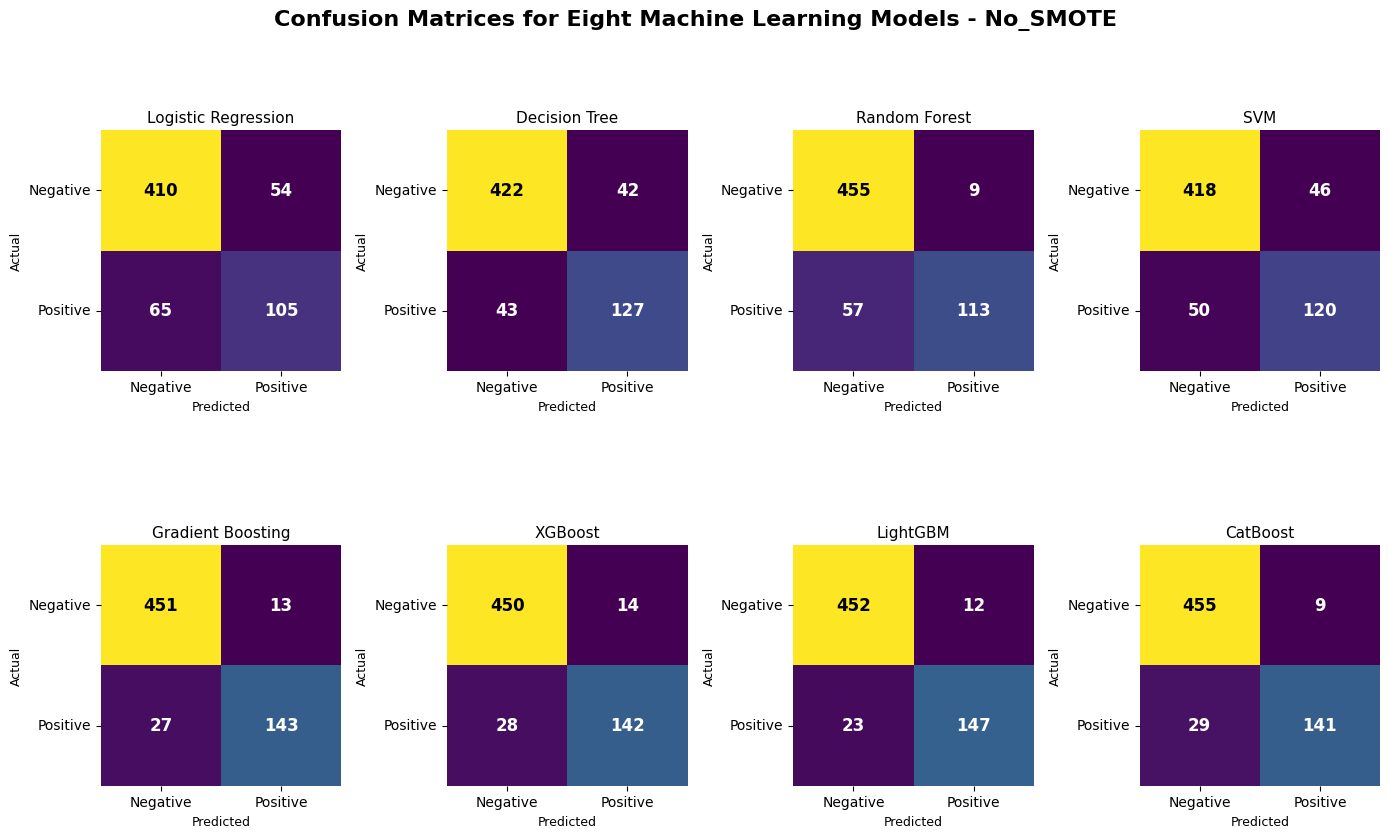

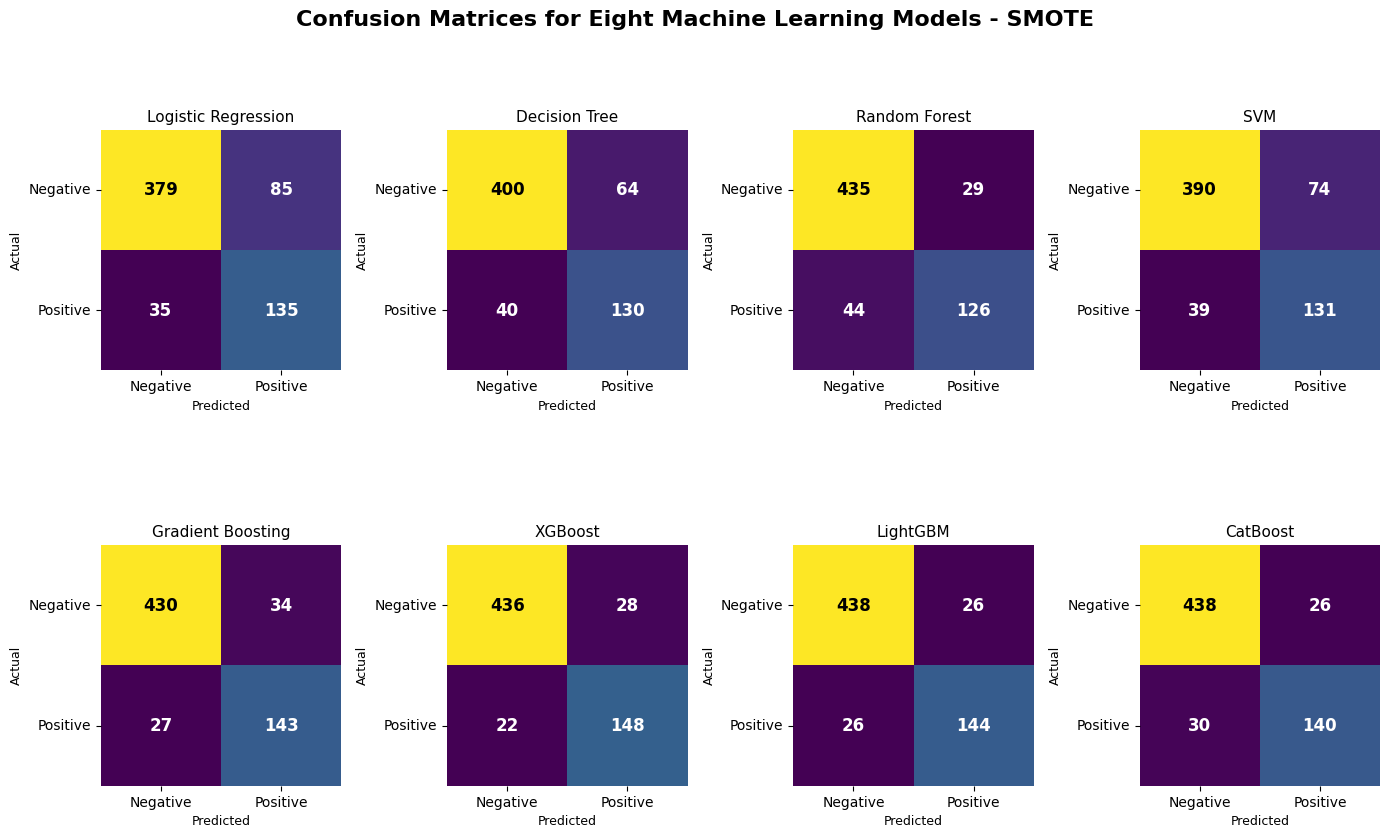

In [99]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

df = pd.read_csv(
    "revised_main_ALP_removed_OOF_predictions.csv"
)

models = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "SVM",
    "Gradient Boosting",
    "XGBoost",
    "LightGBM",
    "CatBoost"
]


def plot_confusion_grids(condition):

    subset = df[df["Condition"] == condition]

    fig, axes = plt.subplots(
        2, 4,
        figsize=(14, 9)
    )

    axes = axes.flatten()

    for i, model in enumerate(models):

        model_df = subset[
            subset["Model"] == model
        ]

        cm = confusion_matrix(
            model_df["y_true"],
            model_df["y_pred"]
        )

        ax = axes[i]

        sns.heatmap(
            cm,
            annot=False,
            fmt="d",
            cmap="viridis",
            cbar=False,
            ax=ax,
            square=True
        )

        # Add values manually
        threshold = cm.max() / 2

        for row in range(cm.shape[0]):
            for col in range(cm.shape[1]):

                value = cm[row, col]

                color = (
                    "white"
                    if value < threshold
                    else "black"
                )

                ax.text(
                    col + 0.5,
                    row + 0.5,
                    f"{value}",
                    ha="center",
                    va="center",
                    fontsize=12,
                    fontweight="bold",
                    color=color
                )

        ax.set_title(
            model,
            fontsize=11
        )

        ax.set_xlabel(
            "Predicted",
            fontsize=9
        )

        ax.set_ylabel(
            "Actual",
            fontsize=9
        )

        ax.set_xticklabels(
            ["Negative", "Positive"],
            rotation=0
        )

        ax.set_yticklabels(
            ["Negative", "Positive"],
            rotation=0
        )

    fig.suptitle(
        f"Confusion Matrices for Eight Machine Learning Models - {condition}",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()

    plt.savefig(
        f"Confusion_Matrices_{condition}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# No SMOTE figure
plot_confusion_grids("No_SMOTE")

# SMOTE figure
plot_confusion_grids("SMOTE")

# ROC Curve witout ALP 

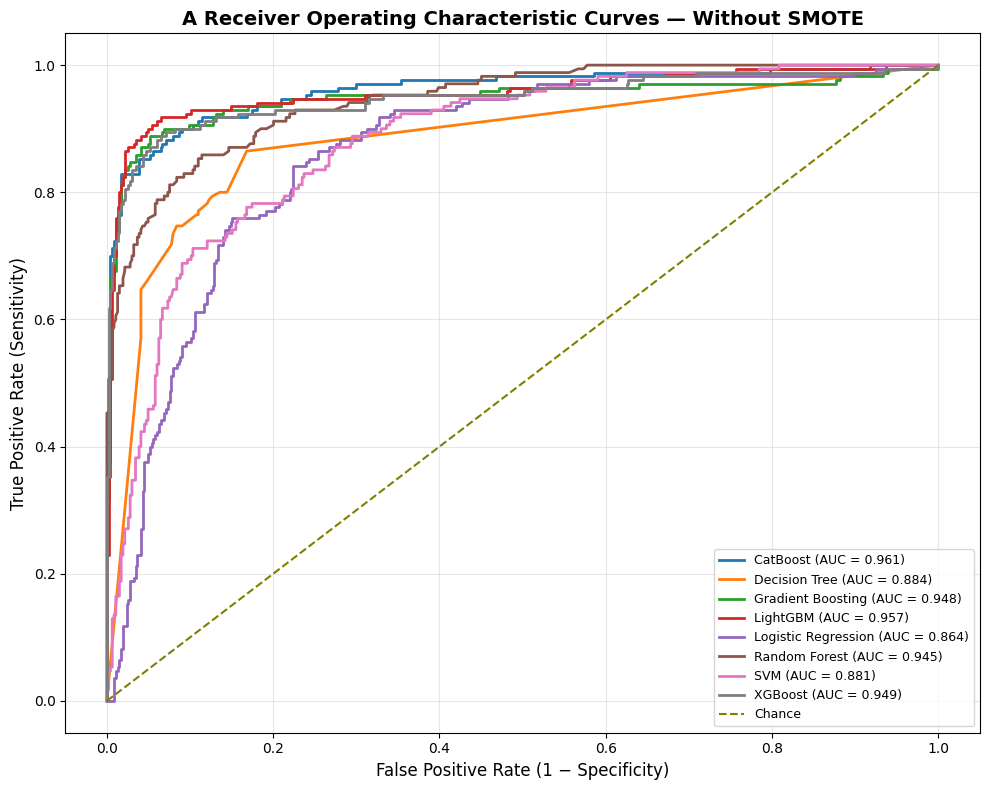

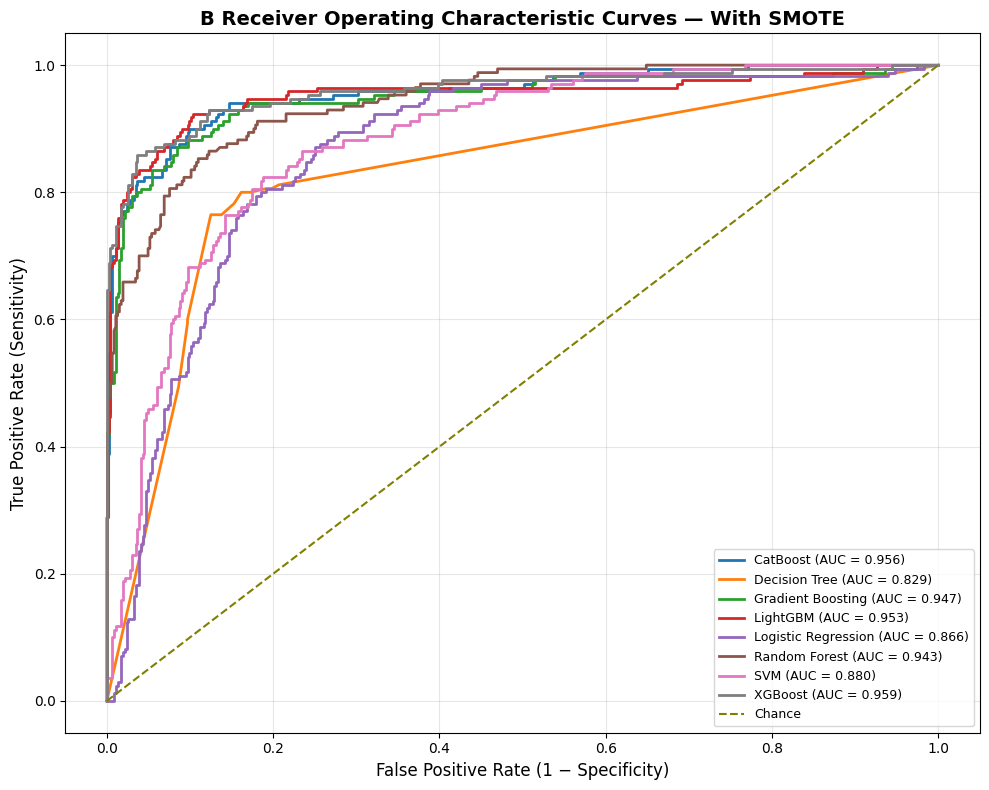


Files saved:
1. ROC_Without_SMOTE.png
2. ROC_With_SMOTE.png


In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

# ============================================================
# LOAD OOF PREDICTIONS
# ============================================================

df = pd.read_csv(
    "revised_main_ALP_removed_OOF_predictions.csv"
)

# ============================================================
# FUNCTION TO PLOT ROC CURVES
# ============================================================

def plot_roc_by_condition(condition_name,
                          panel_letter,
                          output_file):

    subset = df[
        df["Condition"] == condition_name
    ].copy()

    plt.figure(figsize=(10, 8))

    for model in sorted(
        subset["Model"].unique()
    ):

        model_df = subset[
            subset["Model"] == model
        ]

        y_true = model_df["y_true"]
        y_prob = model_df["y_probability"]

        auc = roc_auc_score(
            y_true,
            y_prob
        )

        fpr, tpr, _ = roc_curve(
            y_true,
            y_prob
        )

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{model} (AUC = {auc:.3f})"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="olive",
        label="Chance"
    )

    plt.xlabel(
        "False Positive Rate (1 − Specificity)",
        fontsize=12
    )

    plt.ylabel(
        "True Positive Rate (Sensitivity)",
        fontsize=12
    )

    plt.title(
        f"{panel_letter} Receiver Operating Characteristic Curves — "
        f"{'Without SMOTE' if condition_name == 'No_SMOTE' else 'With SMOTE'}",
        fontsize=14,
        fontweight="bold"
    )

    plt.legend(
        loc="lower right",
        fontsize=9
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

# ============================================================
# PANEL A
# WITHOUT SMOTE
# ============================================================

plot_roc_by_condition(
    condition_name="No_SMOTE",
    panel_letter="A",
    output_file="ROC_Without_SMOTE.png"
)

# ============================================================
# PANEL B
# WITH SMOTE
# ============================================================

plot_roc_by_condition(
    condition_name="SMOTE",
    panel_letter="B",
    output_file="ROC_With_SMOTE.png"
)

print("\nFiles saved:")
print("1. ROC_Without_SMOTE.png")
print("2. ROC_With_SMOTE.png")

# Performance metric  with OOF dataset

# Correct one 

In [15]:

import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import t
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix
)
from openpyxl.styles import Font, PatternFill, Alignment

# ============================================================
# 1. LOAD AND VALIDATE SAVED OOF PREDICTIONS
# ============================================================

input_file = (
    Path.cwd() / "revised_main_ALP_removed_OOF_predictions.csv"
)

if not input_file.exists():
    raise FileNotFoundError(
        f"File not found: {input_file.resolve()}"
    )

predictions = pd.read_csv(input_file)

required = [
    "Model", "Condition", "Outer_Fold",
    "Row_Index", "y_true", "y_pred", "y_probability"
]

missing = [c for c in required if c not in predictions.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

for col in ["Outer_Fold", "y_true", "y_pred", "y_probability"]:
    predictions[col] = pd.to_numeric(
        predictions[col], errors="coerce"
    )

predictions = predictions.dropna(subset=required).copy()

if not predictions["y_true"].isin([0, 1]).all():
    raise ValueError("y_true must contain only 0 and 1.")

if not predictions["y_pred"].isin([0, 1]).all():
    raise ValueError("y_pred must contain only 0 and 1.")

if not predictions["y_probability"].between(0, 1).all():
    raise ValueError("y_probability must be between 0 and 1.")

# Ensure one OOF prediction per participant/model/condition
if predictions.duplicated(
    ["Model", "Condition", "Row_Index"]
).any():
    raise ValueError(
        "Duplicate participant predictions found within a model-condition."
    )

# Ensure each participant has a consistent true outcome
outcome_counts = predictions.groupby("Row_Index")["y_true"].nunique()
if (outcome_counts > 1).any():
    raise ValueError(
        "Some Row_Index values have inconsistent true outcomes."
    )

# Verify exactly five outer folds for each combination
fold_counts = predictions.groupby(
    ["Model", "Condition"]
)["Outer_Fold"].nunique()

if not (fold_counts == 5).all():
    raise ValueError(
        "Every model-condition combination must have five outer folds."
    )

print("Validation passed.")
print("Rows:", len(predictions))
print("Models:", predictions["Model"].nunique())
print("Conditions:", predictions["Condition"].nunique())

# ============================================================
# 2. CALCULATE ALL SEVEN METRICS PER OUTER FOLD
# ============================================================

fold_rows = []

for (model, condition, fold), data in predictions.groupby(
    ["Model", "Condition", "Outer_Fold"]
):

    y_true = data["y_true"].astype(int).to_numpy()
    y_pred = data["y_pred"].astype(int).to_numpy()
    y_prob = data["y_probability"].to_numpy()

    if len(np.unique(y_true)) != 2:
        raise ValueError(
            f"Only one outcome class in {model}/{condition}/fold {fold}."
        )

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    fold_metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Sensitivity": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

    for metric, score in fold_metrics.items():
        fold_rows.append({
            "Model": model,
            "Condition": condition,
            "Outer_Fold": int(fold),
            "Metric": metric,
            "Fold_Estimate": score,
            "Fold_N": len(data)
        })

fold_scores = pd.DataFrame(fold_rows)

# ============================================================
# 3. MEAN AND T-BASED 95% CONFIDENCE INTERVALS
# ============================================================

summary_rows = []

for (model, condition, metric), group in fold_scores.groupby(
    ["Model", "Condition", "Metric"]
):

    scores = group["Fold_Estimate"].dropna().to_numpy()
    n = len(scores)

    if n != 5:
        raise ValueError(
            f"Expected five valid fold scores for "
            f"{model}/{condition}/{metric}; found {n}."
        )

    mean_score = np.mean(scores)
    standard_error = np.std(scores, ddof=1) / np.sqrt(n)
    critical_t = t.ppf(0.975, df=n - 1)

    lower = mean_score - critical_t * standard_error
    upper = mean_score + critical_t * standard_error

    # Apply theoretical limits
    if metric == "MCC":
        lower = max(-1.0, lower)
        upper = min(1.0, upper)
    else:
        lower = max(0.0, lower)
        upper = min(1.0, upper)

    summary_rows.append({
        "Model": model,
        "Condition": condition,
        "N": predictions.loc[
            (predictions["Model"] == model)
            & (predictions["Condition"] == condition),
            "Row_Index"
        ].nunique(),
        "Metric": metric,
        "Estimate": mean_score,
        "CI_Lower": lower,
        "CI_Upper": upper,
        "N_Outer_Folds": n,
        "CI_Method": "Outer-fold t-based 95% CI",
        "Estimate_95CI": (
            f"{mean_score:.3f} ({lower:.3f}–{upper:.3f})"
        )
    })

performance = pd.DataFrame(summary_rows)

# ============================================================
# 4. CREATE MANUSCRIPT-READY TABLE
# ============================================================

metric_order = [
    "Accuracy", "Precision", "Sensitivity", "Specificity",
    "F1", "MCC", "ROC-AUC"
]

manuscript_table = performance.pivot_table(
    index=["Model", "Condition", "N"],
    columns="Metric",
    values="Estimate_95CI",
    aggfunc="first"
).reset_index()

manuscript_table.columns.name = None

manuscript_table = manuscript_table[
    ["Model", "Condition", "N"]
    + [m for m in metric_order if m in manuscript_table.columns]
].rename(columns={
    "Accuracy": "Accuracy (95% CI)",
    "Precision": "Precision (95% CI)",
    "Sensitivity": "Sensitivity (95% CI)",
    "Specificity": "Specificity (95% CI)",
    "F1": "F1-score (95% CI)",
    "MCC": "MCC (95% CI)",
    "ROC-AUC": "ROC-AUC (95% CI)"
})

print("\nManuscript performance table:")
display(manuscript_table)

# ============================================================
# 5. EXPORT EXCEL WORKBOOK
# ============================================================

output_file = (
    Path.cwd() / "revised_main_ALP_removed_t_based_CI.xlsx"
)

detailed_table = performance.copy()

for col in ["Estimate", "CI_Lower", "CI_Upper"]:
    detailed_table[col] = detailed_table[col].round(4)

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    manuscript_table.to_excel(
        writer, sheet_name="Manuscript_Table", index=False
    )

    detailed_table.to_excel(
        writer, sheet_name="Detailed_Metrics", index=False
    )

    fold_scores.to_excel(
        writer, sheet_name="Outer_Fold_Scores", index=False
    )

    for sheet_name in [
        "Manuscript_Table",
        "Detailed_Metrics",
        "Outer_Fold_Scores"
    ]:
        ws = writer.sheets[sheet_name]
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions

        for cell in ws[1]:
            cell.font = Font(bold=True, color="FFFFFF")
            cell.fill = PatternFill(
                fill_type="solid", fgColor="1F4E78"
            )
            cell.alignment = Alignment(
                horizontal="center",
                vertical="center",
                wrap_text=True
            )

        ws.row_dimensions[1].height = 32

        for cells in ws.columns:
            letter = cells[0].column_letter
            max_len = max(
                len(str(cell.value or "")) for cell in cells
            )
            ws.column_dimensions[letter].width = min(
                max(max_len + 2, 12), 36
            )

print("\nWorkbook saved successfully:")
print(output_file.resolve())

print("\nSummary checks:")
print("Model-condition combinations:", len(manuscript_table))
print("Metric summaries:", len(performance))
print("Outer-fold metric observations:", len(fold_scores))

Validation passed.
Rows: 10144
Models: 8
Conditions: 2

Manuscript performance table:


,Model,Condition,N,Accuracy (95% CI),Precision (95% CI),Sensitivity (95% CI),Specificity (95% CI),F1-score (95% CI),MCC (95% CI),ROC-AUC (95% CI)
0,CatBoost,No_SMOTE,634,0.940 (0.912–0.968),0.942 (0.870–1.000),0.829 (0.775–0.884),0.981 (0.955–1.000),0.881 (0.827–0.936),0.845 (0.772–0.919),0.965 (0.935–0.996)
1,CatBoost,SMOTE,634,0.912 (0.890–0.934),0.847 (0.783–0.910),0.824 (0.755–0.892),0.944 (0.915–0.973),0.833 (0.791–0.876),0.775 (0.719–0.831),0.958 (0.925–0.991)
2,Decision Tree,No_SMOTE,634,0.866 (0.799–0.933),0.761 (0.606–0.916),0.747 (0.583–0.912),0.909 (0.842–0.977),0.749 (0.622–0.875),0.662 (0.486–0.838),0.876 (0.803–0.949)
3,Decision Tree,SMOTE,634,0.836 (0.801–0.871),0.681 (0.583–0.780),0.765 (0.679–0.850),0.862 (0.791–0.933),0.715 (0.680–0.751),0.608 (0.552–0.664),0.830 (0.771–0.889)
4,Gradient Boosting,No_SMOTE,634,0.937 (0.910–0.964),0.917 (0.866–0.968),0.841 (0.770–0.912),0.972 (0.954–0.990),0.877 (0.823–0.931),0.836 (0.766–0.907),0.954 (0.912–0.996)
5,Gradient Boosting,SMOTE,634,0.904 (0.882–0.926),0.811 (0.746–0.875),0.841 (0.809–0.874),0.927 (0.896–0.957),0.825 (0.789–0.860),0.760 (0.709–0.810),0.955 (0.920–0.989)
6,LightGBM,No_SMOTE,634,0.945 (0.914–0.976),0.927 (0.847–1.000),0.865 (0.816–0.914),0.974 (0.945–1.000),0.894 (0.837–0.951),0.858 (0.779–0.937),0.965 (0.932–0.997)
7,LightGBM,SMOTE,634,0.918 (0.881–0.955),0.851 (0.762–0.940),0.847 (0.764–0.930),0.944 (0.906–0.982),0.847 (0.778–0.916),0.793 (0.700–0.885),0.958 (0.921–0.994)
8,Logistic Regression,No_SMOTE,634,0.812 (0.780–0.845),0.661 (0.603–0.720),0.618 (0.469–0.766),0.884 (0.846–0.921),0.634 (0.541–0.727),0.513 (0.410–0.616),0.870 (0.865–0.876)
9,Logistic Regression,SMOTE,634,0.811 (0.771–0.851),0.616 (0.550–0.682),0.794 (0.708–0.880),0.817 (0.770–0.864),0.692 (0.630–0.755),0.570 (0.481–0.658),0.869 (0.861–0.876)



Workbook saved successfully:
C:\Users\jnabateesa\Videos\Masterproject\revised_main_ALP_removed_t_based_CI.xlsx

Summary checks:
Model-condition combinations: 16
Metric summaries: 112
Outer-fold metric observations: 560


# SHAP Summary Plots  Without ALP.Best models are LGBM without SMOTE & XGBM with SMOTE

LOADING REVISED MAIN-ANALYSIS DATASET

Initial dataset shape: (634, 24)

ALP check: PASSED

Final dataset shape: (634, 24)
Number of observations: 634
Number of predictors: 23

Outcome distribution:
HBsAg_Status
0    464
1    170
Name: count, dtype: int64

Outcome percentages:
HBsAg_Status
0    73.19
1    26.81
Name: proportion, dtype: float64


PREDICTOR INFORMATION

Numeric predictors (20):
['Age', 'ART_Duration', 'WBC', 'HGB', 'HCT', 'PLT', 'MCH', 'MCHC', 'MVC', 'NE#', 'LY#', 'RBC', 'RDW', 'CREA', 'BILT', 'ALB', 'V-LOAD', 'CD4', 'AST', 'ALT']

Categorical predictors (3):
['District', 'Sex', 'Regimen']

TOTAL ORIGINAL PREDICTORS: 23


RUNNING BEST NO-SMOTE MODEL
MODEL: LIGHTGBM


SHAP ANALYSIS: LightGBM + No_SMOTE


---------------------------------------------------------------------------
LightGBM | No_SMOTE | OUTER FOLD 1/5
---------------------------------------------------------------------------
Training observations: 507
Test observations: 127
Processed feature count: 72

SMOT

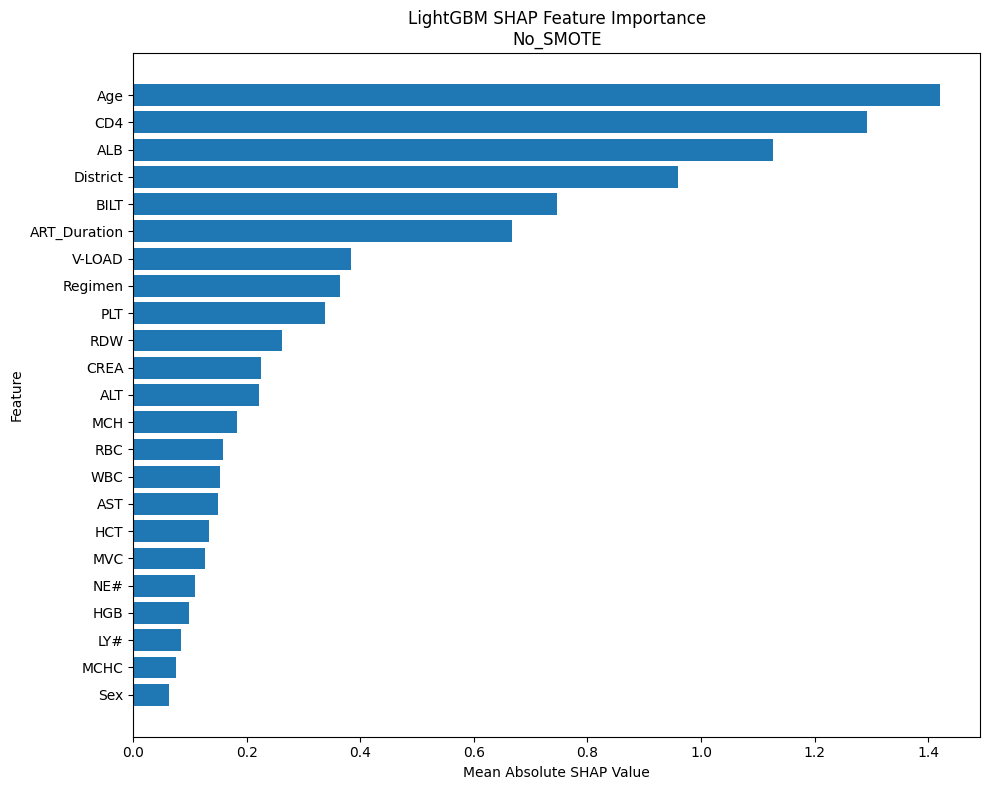

Saved: SHAP_Best_Models_ALP_Removed\SHAP_bar_LightGBM_No_SMOTE.png


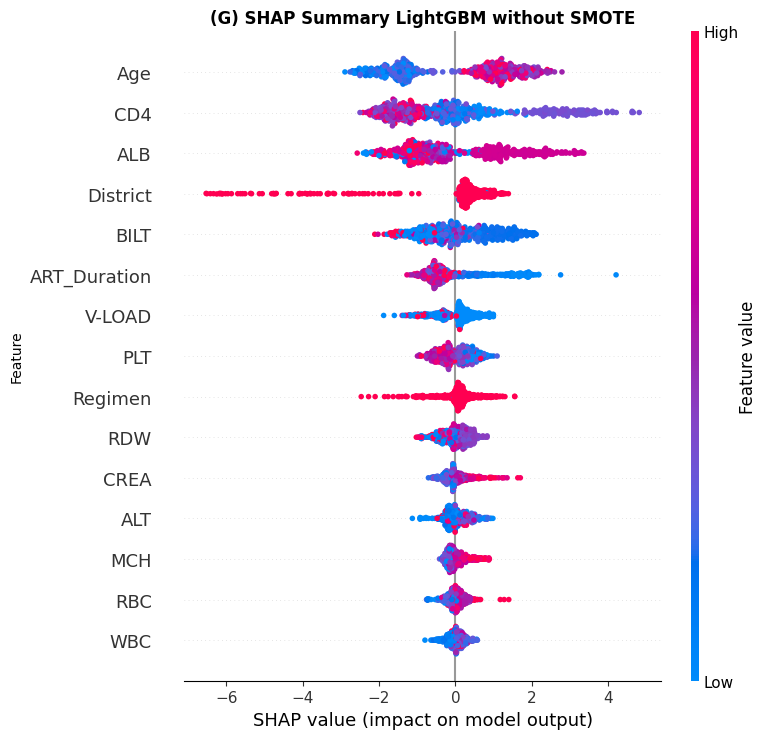

Saved: SHAP_Best_Models_ALP_Removed\SHAP_beeswarm_TOP15_LightGBM_No_SMOTE.png


RUNNING BEST SMOTE MODEL
MODEL: XGBoost


SHAP ANALYSIS: XGBoost + SMOTE


---------------------------------------------------------------------------
XGBoost | SMOTE | OUTER FOLD 1/5
---------------------------------------------------------------------------
Training observations: 507
Test observations: 127
Processed feature count: 72

SMOTE: APPLYING TO TRAINING DATA ONLY
Before SMOTE: 507 observations
After SMOTE: 742 observations
Outer test set: UNTOUCHED

XGBoost fitted successfully.

Calculating SHAP values...
SHAP matrix shape: (127, 72)


---------------------------------------------------------------------------
XGBoost | SMOTE | OUTER FOLD 2/5
---------------------------------------------------------------------------
Training observations: 507
Test observations: 127
Processed feature count: 72

SMOTE: APPLYING TO TRAINING DATA ONLY
Before SMOTE: 507 observations
After SMOTE: 742 observations
Oute

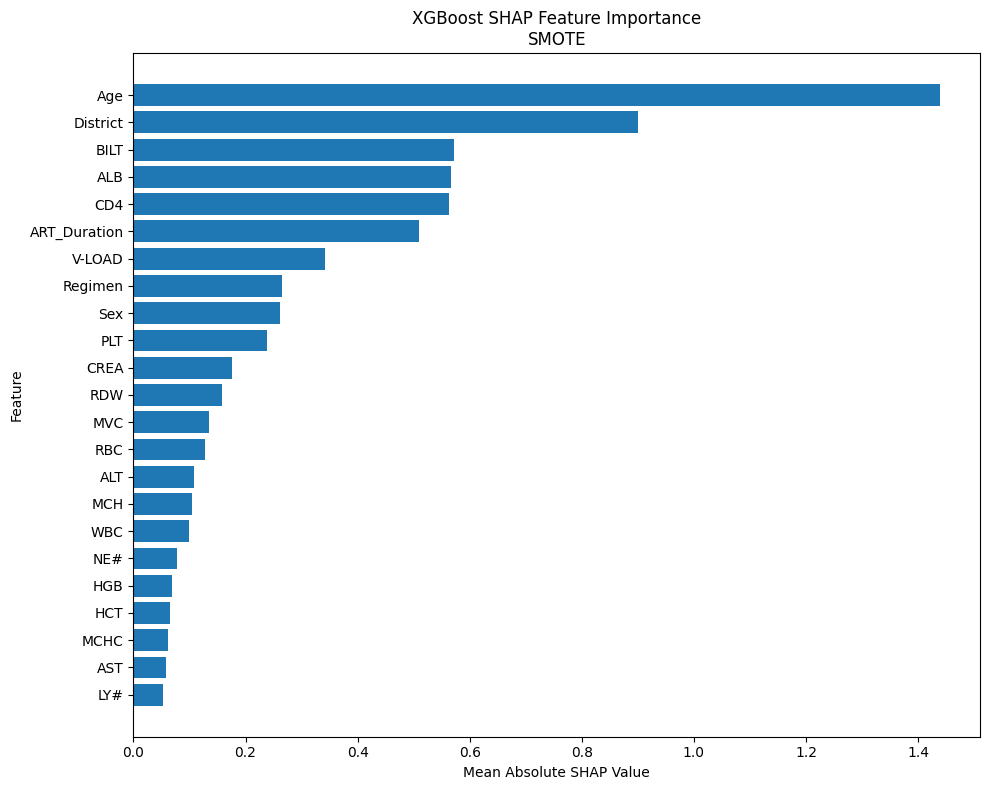

Saved: SHAP_Best_Models_ALP_Removed\SHAP_bar_XGBoost_SMOTE.png


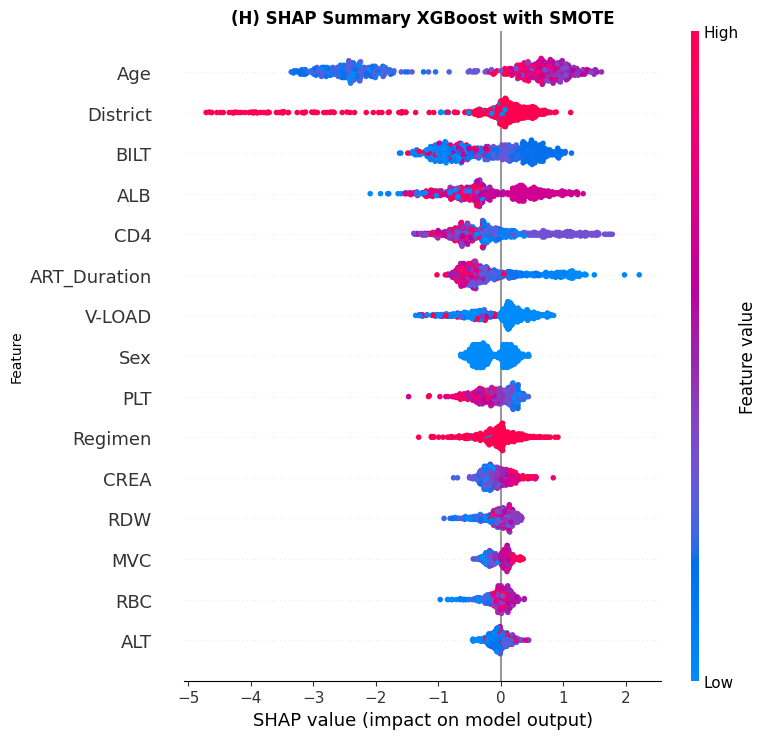

Saved: SHAP_Best_Models_ALP_Removed\SHAP_beeswarm_TOP15_XGBoost_SMOTE.png


COMPARING SHAP:
LIGHTGBM NO-SMOTE VS XGBOOST SMOTE

SHAP comparison:
 Rank_LightGBM_No_SMOTE      Feature  Mean_Absolute_SHAP_LightGBM_No_SMOTE  Rank_XGBoost_SMOTE  Mean_Absolute_SHAP_XGBoost_SMOTE  Rank_Change
                      1          Age                              1.420492                   1                          1.438458            0
                      2          CD4                              1.292631                   5                          0.563726           -3
                      3          ALB                              1.126940                   4                          0.567393           -1
                      4     District                              0.959834                   2                          0.901010            2
                      5         BILT                              0.746175                   3                          0.572698            2
   

In [89]:
# ================================================================
# SHAP ANALYSIS FOR REVISED MAIN MODEL
# ================================================================
#
# REVISED DATASET:
#   - Features with >50% missingness removed
#   - ALP removed
#
# BEST MODELS FROM NESTED CV:
#   1. LightGBM - No SMOTE
#   2. XGBoost   - SMOTE
#
# SHAP VALIDATION:
#   - 5-fold Stratified CV
#   - Preprocessing fitted within each outer training fold
#   - SMOTE applied ONLY to outer training folds
#   - SHAP calculated on untouched outer test folds
#
# CATEGORICAL VARIABLES:
#   - One-hot encoded within each fold
#   - SHAP values aggregated back to:
#       District
#       Regimen
#       Sex
#
# OUTPUTS:
#   - SHAP importance CSV
#   - SHAP values CSV
#   - SHAP bar plot
#   - Top-15 SHAP beeswarm plot
#   - LightGBM vs XGBoost comparison
#
# ================================================================


# ================================================================
# 1. IMPORTS
# ================================================================

import os
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier


# ================================================================
# 2. SETTINGS
# ================================================================

SEED = 42
N_SPLITS = 5

DATA_FILE = "cleaned_dataset_ALP_removed_high_missingness.csv"

TARGET = "HBsAg_Status"

OUTPUT_DIR = "SHAP_Best_Models_ALP_Removed"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ================================================================
# 3. MODEL PARAMETERS
# ================================================================
#
# IMPORTANT:
# Replace the parameters below with the BEST PARAMETERS obtained
# from your nested-CV GridSearchCV results.
#
# Do NOT use arbitrary parameters in the final manuscript if
# exact best parameters are available from your nested CV.
#
# ================================================================


# ------------------------------------------------
# LIGHTGBM
# BEST MODEL: NO SMOTE
# ------------------------------------------------

LGBM_PARAMS = {
    "n_estimators": 200,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "random_state": SEED,
    "verbosity": -1
}


# ------------------------------------------------
# XGBOOST
# BEST MODEL: SMOTE
# ------------------------------------------------

XGB_PARAMS = {
    "n_estimators": 200,
    "learning_rate": 0.05,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": SEED,
    "eval_metric": "logloss",
    "n_jobs": -1
}


# ================================================================
# 4. LOAD DATA
# ================================================================

print("=" * 80)
print("LOADING REVISED MAIN-ANALYSIS DATASET")
print("=" * 80)

df = pd.read_csv(DATA_FILE)

print(
    f"\nInitial dataset shape: {df.shape}"
)


# ================================================================
# 5. CHECK TARGET
# ================================================================

if TARGET not in df.columns:

    raise ValueError(
        f"Target '{TARGET}' was not found in the dataset."
    )


# ================================================================
# 6. CHECK THAT ALP HAS BEEN REMOVED
# ================================================================

if "ALP" in df.columns:

    raise ValueError(
        "ALP is still present in the dataset. "
        "Please use the revised dataset with ALP removed."
    )

print("\nALP check: PASSED")


# ================================================================
# 7. REMOVE MISSING OUTCOME
# ================================================================

df = (
    df
    .dropna(subset=[TARGET])
    .reset_index(drop=True)
)


# ================================================================
# 8. DEFINE X AND Y
# ================================================================

X = (
    df
    .drop(columns=[TARGET])
    .copy()
)

y = (
    df[TARGET]
    .astype(int)
    .copy()
)


print(
    f"\nFinal dataset shape: {df.shape}"
)

print(
    f"Number of observations: {X.shape[0]}"
)

print(
    f"Number of predictors: {X.shape[1]}"
)

print("\nOutcome distribution:")

print(
    y.value_counts()
)

print("\nOutcome percentages:")

print(
    (y.value_counts(normalize=True) * 100).round(2)
)


# ================================================================
# 9. IDENTIFY CATEGORICAL AND NUMERIC VARIABLES
# ================================================================

categorical_features = (
    X
    .select_dtypes(
        include=[
            "object",
            "category",
            "bool"
        ]
    )
    .columns
    .tolist()
)


numeric_features = (
    X
    .select_dtypes(
        include=[
            np.number
        ]
    )
    .columns
    .tolist()
)


# ================================================================
# 10. CONVERT NUMERIC VARIABLES
# ================================================================

for col in numeric_features:

    X[col] = pd.to_numeric(
        X[col],
        errors="coerce"
    )


# ================================================================
# 11. PRINT PREDICTOR INFORMATION
# ================================================================

print("\n")
print("=" * 80)
print("PREDICTOR INFORMATION")
print("=" * 80)

print(
    f"\nNumeric predictors ({len(numeric_features)}):"
)

print(
    numeric_features
)

print(
    f"\nCategorical predictors ({len(categorical_features)}):"
)

print(
    categorical_features
)

print(
    f"\nTOTAL ORIGINAL PREDICTORS: {X.shape[1]}"
)


# ================================================================
# 12. CREATE PREPROCESSOR
# ================================================================

def make_preprocessor(
    numeric_cols,
    categorical_cols
):

    # ------------------------------------------------
    # Numeric pipeline
    # ------------------------------------------------

    numeric_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            )
        ]
    )


    # ------------------------------------------------
    # Categorical pipeline
    # ------------------------------------------------

    categorical_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                )
            )
        ]
    )


    # ------------------------------------------------
    # Column transformer
    # ------------------------------------------------

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                numeric_pipeline,
                numeric_cols
            ),
            (
                "cat",
                categorical_pipeline,
                categorical_cols
            )
        ],
        remainder="drop"
    )


    return preprocessor


# ================================================================
# 13. GET PROCESSED FEATURE NAMES
# ================================================================

def get_processed_feature_names(
    preprocessor,
    numeric_cols,
    categorical_cols
):

    feature_names = []


    # ------------------------------------------------
    # Numeric names
    # ------------------------------------------------

    feature_names.extend(
        numeric_cols
    )


    # ------------------------------------------------
    # Categorical names
    # ------------------------------------------------

    if len(categorical_cols) > 0:

        cat_pipeline = (
            preprocessor
            .named_transformers_["cat"]
        )

        encoder = (
            cat_pipeline
            .named_steps["onehot"]
        )

        cat_names = (
            encoder
            .get_feature_names_out(
                categorical_cols
            )
        )

        feature_names.extend(
            cat_names.tolist()
        )


    return np.array(
        feature_names,
        dtype=object
    )


# ================================================================
# 14. MAP ENCODED FEATURES TO ORIGINAL VARIABLES
# ================================================================

def map_to_original_feature(
    feature_name,
    categorical_cols
):

    name = feature_name.replace(
        "num__",
        ""
    )

    name = name.replace(
        "cat__",
        ""
    )


    # ------------------------------------------------
    # Map one-hot variables
    # ------------------------------------------------

    for cat in categorical_cols:

        if name.startswith(
            cat + "_"
        ):

            return cat


    # ------------------------------------------------
    # Numeric variable
    # ------------------------------------------------

    return name


# ================================================================
# 15. GENERAL SHAP FUNCTION
# ================================================================

def run_shap_analysis(
    model_name,
    condition_name,
    use_smote=False
):

    print("\n")
    print("=" * 80)
    print(
        f"SHAP ANALYSIS: {model_name} + {condition_name}"
    )
    print("=" * 80)


    # ============================================================
    # OUTER CROSS-VALIDATION
    # ============================================================

    cv = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=SEED
    )


    fold_shap_values = []

    fold_feature_names = []

    fold_processed_X = []


    # ============================================================
    # OUTER FOLDS
    # ============================================================

    for fold, (
        train_idx,
        test_idx
    ) in enumerate(
        cv.split(X, y),
        start=1
    ):

        print("\n")
        print("-" * 75)
        print(
            f"{model_name} | {condition_name} | "
            f"OUTER FOLD {fold}/{N_SPLITS}"
        )
        print("-" * 75)


        # --------------------------------------------------------
        # Split data
        # --------------------------------------------------------

        X_train = (
            X.iloc[train_idx]
            .copy()
        )

        X_test = (
            X.iloc[test_idx]
            .copy()
        )

        y_train = (
            y.iloc[train_idx]
            .copy()
        )

        y_test = (
            y.iloc[test_idx]
            .copy()
        )


        print(
            f"Training observations: {len(X_train)}"
        )

        print(
            f"Test observations: {len(X_test)}"
        )


        # ========================================================
        # PREPROCESSING
        # ========================================================
        #
        # IMPORTANT:
        # Fit preprocessing ONLY on outer training data.
        # ========================================================

        preprocessor = make_preprocessor(
            numeric_features,
            categorical_features
        )


        X_train_processed = (
            preprocessor
            .fit_transform(X_train)
        )


        X_test_processed = (
            preprocessor
            .transform(X_test)
        )


        # --------------------------------------------------------
        # Feature names
        # --------------------------------------------------------

        feature_names = (
            get_processed_feature_names(
                preprocessor,
                numeric_features,
                categorical_features
            )
        )


        print(
            f"Processed feature count: "
            f"{len(feature_names)}"
        )


        # ========================================================
        # SMOTE
        # ========================================================

        if use_smote:

            print(
                "\nSMOTE: APPLYING TO TRAINING DATA ONLY"
            )

            print(
                f"Before SMOTE: "
                f"{len(y_train)} observations"
            )


            smote = SMOTE(
                random_state=SEED
            )


            X_train_model, y_train_model = (
                smote.fit_resample(
                    X_train_processed,
                    y_train
                )
            )


            print(
                f"After SMOTE: "
                f"{len(y_train_model)} observations"
            )

            print(
                "Outer test set: UNTOUCHED"
            )


        else:

            print(
                "\nSMOTE: NOT USED"
            )


            X_train_model = (
                X_train_processed
            )

            y_train_model = (
                y_train
            )


        # ========================================================
        # CREATE MODEL
        # ========================================================

        if model_name == "LightGBM":

            model = LGBMClassifier(
                **LGBM_PARAMS
            )


        elif model_name == "XGBoost":

            model = XGBClassifier(
                **XGB_PARAMS
            )


        else:

            raise ValueError(
                f"Unknown model: {model_name}"
            )


        # ========================================================
        # FIT MODEL
        # ========================================================

        model.fit(
            X_train_model,
            y_train_model
        )


        print(
            f"\n{model_name} fitted successfully."
        )


        # ========================================================
        # SHAP EXPLAINER
        # ========================================================
        #
        # SHAP is calculated on the ORIGINAL OUTER TEST SET.
        #
        # This means:
        #
        # No-SMOTE:
        #   model trained on original training data
        #   SHAP calculated on real test patients
        #
        # SMOTE:
        #   model trained on SMOTE training data
        #   SHAP calculated on real test patients
        #
        # ========================================================

        print(
            "\nCalculating SHAP values..."
        )


        explainer = shap.TreeExplainer(
            model
        )


        shap_values = (
            explainer.shap_values(
                X_test_processed
            )
        )


        # ========================================================
        # BINARY CLASSIFICATION HANDLING
        # ========================================================

        if isinstance(
            shap_values,
            list
        ):

            # For binary classification,
            # use SHAP values for positive class.

            shap_fold = (
                shap_values[1]
            )

        else:

            shap_fold = shap_values


        shap_fold = np.asarray(
            shap_fold
        )


        # --------------------------------------------------------
        # Handle newer SHAP output shape
        # --------------------------------------------------------

        if shap_fold.ndim == 3:

            # Expected shape:
            # observations x features x classes

            shap_fold = (
                shap_fold[:, :, 1]
            )


        print(
            f"SHAP matrix shape: "
            f"{shap_fold.shape}"
        )


        # ========================================================
        # STORE FOLD RESULTS
        # ========================================================

        fold_shap_values.append(
            shap_fold
        )

        fold_feature_names.append(
            feature_names
        )

        fold_processed_X.append(
            X_test_processed
        )


    # ============================================================
    # ALIGN FEATURES ACROSS FOLDS
    # ============================================================

    print("\n")
    print("=" * 80)
    print("ALIGNING ENCODED FEATURES ACROSS OUTER FOLDS")
    print("=" * 80)


    common_feature_names = sorted(
        set(
            feature
            for names in fold_feature_names
            for feature in names
        )
    )


    print(
        f"\nUnique encoded features: "
        f"{len(common_feature_names)}"
    )


    aligned_shap = []

    aligned_X = []


    for (
        shap_fold,
        X_fold,
        names
    ) in zip(
        fold_shap_values,
        fold_processed_X,
        fold_feature_names
    ):


        shap_df = pd.DataFrame(
            shap_fold,
            columns=names
        )


        X_df = pd.DataFrame(
            X_fold,
            columns=names
        )


        # --------------------------------------------------------
        # Add absent dummy variables as zero
        # --------------------------------------------------------

        shap_df = (
            shap_df
            .reindex(
                columns=common_feature_names,
                fill_value=0
            )
        )


        X_df = (
            X_df
            .reindex(
                columns=common_feature_names,
                fill_value=0
            )
        )


        aligned_shap.append(
            shap_df
        )

        aligned_X.append(
            X_df
        )


    # ============================================================
    # COMBINE OUTER TEST FOLDS
    # ============================================================

    shap_all = pd.concat(
        aligned_shap,
        axis=0,
        ignore_index=True
    )


    X_all_processed = pd.concat(
        aligned_X,
        axis=0,
        ignore_index=True
    )


    print(
        f"\nCombined SHAP matrix: "
        f"{shap_all.shape}"
    )


    # ============================================================
    # GROUP ONE-HOT VARIABLES
    # ============================================================

    print("\n")
    print("=" * 80)
    print("AGGREGATING ONE-HOT FEATURES TO ORIGINAL PREDICTORS")
    print("=" * 80)


    feature_map = {}


    for encoded_feature in common_feature_names:

        original_feature = (
            map_to_original_feature(
                encoded_feature,
                categorical_features
            )
        )


        if (
            original_feature
            not in feature_map
        ):

            feature_map[
                original_feature
            ] = []


        feature_map[
            original_feature
        ].append(
            encoded_feature
        )


    print(
        "\nOriginal predictors represented:"
    )


    for (
        original,
        encoded
    ) in feature_map.items():

        print(
            f"  {original}: "
            f"{len(encoded)} encoded column(s)"
        )


    # ============================================================
    # CALCULATE GROUPED SHAP IMPORTANCE
    # ============================================================

    importance_results = []

    grouped_shap_values = {}

    grouped_feature_values = {}


    for (
        original_feature,
        encoded_features
    ) in feature_map.items():


        indices = [
            common_feature_names.index(
                f
            )
            for f in encoded_features
        ]


        shap_subset = (
            shap_all
            .iloc[:, indices]
            .values
        )


        X_subset = (
            X_all_processed
            .iloc[:, indices]
            .values
        )


        # --------------------------------------------------------
        # Mean absolute SHAP
        # --------------------------------------------------------
        #
        # Sum absolute SHAP contributions across dummy variables
        # for each patient, then average.
        #
        # --------------------------------------------------------

        grouped_abs = np.sum(
            np.abs(
                shap_subset
            ),
            axis=1
        )


        mean_abs_shap = np.mean(
            grouped_abs
        )


        # --------------------------------------------------------
        # Signed SHAP
        # --------------------------------------------------------

        grouped_signed = np.sum(
            shap_subset,
            axis=1
        )


        # --------------------------------------------------------
        # Store
        # --------------------------------------------------------

        grouped_shap_values[
            original_feature
        ] = grouped_signed


        grouped_feature_values[
            original_feature
        ] = np.sum(
            X_subset,
            axis=1
        )


        importance_results.append(
            {
                "Feature":
                    original_feature,

                "Mean_Absolute_SHAP":
                    mean_abs_shap
            }
        )


    # ============================================================
    # IMPORTANCE TABLE
    # ============================================================

    importance_df = pd.DataFrame(
        importance_results
    )


    importance_df = (
        importance_df
        .sort_values(
            "Mean_Absolute_SHAP",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )


    importance_df[
        "Rank"
    ] = (
        np.arange(
            len(importance_df)
        )
        + 1
    )


    importance_df = (
        importance_df[
            [
                "Rank",
                "Feature",
                "Mean_Absolute_SHAP"
            ]
        ]
    )


    # ============================================================
    # PRINT SHAP RANKING
    # ============================================================

    print("\n")
    print("=" * 80)
    print(
        f"SHAP RANKING: "
        f"{model_name} - {condition_name}"
    )
    print("=" * 80)


    print(
        importance_df.to_string(
            index=False
        )
    )


    # ============================================================
    # SAFE FILE NAME
    # ============================================================

    safe_condition = (
        condition_name
        .replace(" ", "_")
    )

    safe_model = (
        model_name
        .replace(" ", "_")
    )


    # ============================================================
    # SAVE IMPORTANCE CSV
    # ============================================================

    importance_file = os.path.join(
        OUTPUT_DIR,
        f"SHAP_importance_"
        f"{safe_model}_"
        f"{safe_condition}.csv"
    )


    importance_df.to_csv(
        importance_file,
        index=False
    )


    print(
        f"\nSaved: {importance_file}"
    )


    # ============================================================
    # SAVE GROUPED SHAP VALUES
    # ============================================================

    grouped_shap_df = pd.DataFrame(
        grouped_shap_values
    )


    grouped_shap_file = os.path.join(
        OUTPUT_DIR,
        f"SHAP_values_grouped_"
        f"{safe_model}_"
        f"{safe_condition}.csv"
    )


    grouped_shap_df.to_csv(
        grouped_shap_file,
        index=False
    )


    print(
        f"Saved: {grouped_shap_file}"
    )


    # ============================================================
    # SHAP BAR PLOT
    # ============================================================

    plot_df = (
        importance_df
        .sort_values(
            "Mean_Absolute_SHAP",
            ascending=True
        )
    )


    plt.figure(
        figsize=(10, 8)
    )


    plt.barh(
        plot_df["Feature"],
        plot_df[
            "Mean_Absolute_SHAP"
        ]
    )


    plt.xlabel(
        "Mean Absolute SHAP Value"
    )

    plt.ylabel(
        "Feature"
    )


    plt.title(
        f"{model_name} SHAP Feature Importance\n" #Title
        f"{condition_name}"
    )


    plt.tight_layout()


    bar_file = os.path.join(
        OUTPUT_DIR,
        f"SHAP_bar_"
        f"{safe_model}_"
        f"{safe_condition}.png"
    )


    plt.savefig(
        bar_file,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

    plt.close()


    print(
        f"Saved: {bar_file}"
    )


    # ============================================================
    # TOP-15 SHAP BEESWARM
    # ============================================================

    top_n = min(
        15,
        len(importance_df)
    )


    top_features = (
        importance_df
        .head(top_n)
        ["Feature"]
        .tolist()
    )


    grouped_shap_matrix = np.column_stack(
        [
            grouped_shap_values[
                feature
            ]
            for feature in top_features
        ]
    )


    grouped_X_matrix = np.column_stack(
        [
            grouped_feature_values[
                feature
            ]
            for feature in top_features
        ]
    )


    plt.figure(
        figsize=(11, 9)
    )


    shap.summary_plot(
        grouped_shap_matrix,
        grouped_X_matrix,
        feature_names=top_features,
        max_display=top_n,
        show=False
    )


    plt.title(
    "(G) SHAP Summary LightGBM without SMOTE"
    if model_name == "LightGBM" and condition_name == "No_SMOTE"
    else "(H) SHAP Summary XGBoost with SMOTE",
    fontweight="bold"
)
    # - Top {top_n} Features

    plt.ylabel(
            "Feature"
        )

    plt.tight_layout()
    
    


    beeswarm_file = os.path.join(
        OUTPUT_DIR,
        f"SHAP_beeswarm_TOP15_"
        f"{safe_model}_"
        f"{safe_condition}.png"
    )


    plt.savefig(
        beeswarm_file,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

    plt.close()


    print(
        f"Saved: {beeswarm_file}"
    )


    # ============================================================
    # RETURN
    # ============================================================

    return {

        "importance":
            importance_df,

        "shap_values":
            grouped_shap_df,

        "encoded_feature_names":
            common_feature_names,

        "feature_map":
            feature_map
    }


# ================================================================
# 16. RUN LIGHTGBM — NO SMOTE
# ================================================================

print("\n")
print("=" * 80)
print("RUNNING BEST NO-SMOTE MODEL")
print("MODEL: LIGHTGBM")
print("=" * 80)


results_lightgbm_no_smote = (
    run_shap_analysis(
        model_name="LightGBM",
        condition_name="No_SMOTE",
        use_smote=False
    )
)


# ================================================================
# 17. RUN XGBOOST — SMOTE
# ================================================================

print("\n")
print("=" * 80)
print("RUNNING BEST SMOTE MODEL")
print("MODEL: XGBoost")
print("=" * 80)


results_xgboost_smote = (
    run_shap_analysis(
        model_name="XGBoost",
        condition_name="SMOTE",
        use_smote=True
    )
)


# ================================================================
# 18. COMPARE SHAP RANKINGS
# ================================================================

print("\n")
print("=" * 80)
print("COMPARING SHAP:")
print("LIGHTGBM NO-SMOTE VS XGBOOST SMOTE")
print("=" * 80)


lightgbm = (
    results_lightgbm_no_smote[
        "importance"
    ]
    .copy()
)


xgboost = (
    results_xgboost_smote[
        "importance"
    ]
    .copy()
)


# ------------------------------------------------
# Rename columns
# ------------------------------------------------

lightgbm = (
    lightgbm
    .rename(
        columns={
            "Rank":
                "Rank_LightGBM_No_SMOTE",

            "Mean_Absolute_SHAP":
                "Mean_Absolute_SHAP_LightGBM_No_SMOTE"
        }
    )
)


xgboost = (
    xgboost
    .rename(
        columns={
            "Rank":
                "Rank_XGBoost_SMOTE",

            "Mean_Absolute_SHAP":
                "Mean_Absolute_SHAP_XGBoost_SMOTE"
        }
    )
)


# ------------------------------------------------
# Merge
# ------------------------------------------------

comparison = pd.merge(
    lightgbm,
    xgboost,
    on="Feature",
    how="outer"
)


# ------------------------------------------------
# Calculate rank change
# ------------------------------------------------

comparison[
    "Rank_Change"
] = (
    comparison[
        "Rank_LightGBM_No_SMOTE"
    ]
    -
    comparison[
        "Rank_XGBoost_SMOTE"
    ]
)


# ------------------------------------------------
# Sort
# ------------------------------------------------

comparison = (
    comparison
    .sort_values(
        "Rank_LightGBM_No_SMOTE",
        na_position="last"
    )
)


# ================================================================
# 19. SAVE SHAP COMPARISON
# ================================================================

comparison_file = os.path.join(
    OUTPUT_DIR,
    "SHAP_comparison_LightGBM_No_SMOTE_vs_XGBoost_SMOTE.csv"
)


comparison.to_csv(
    comparison_file,
    index=False
)


print(
    "\nSHAP comparison:"
)


print(
    comparison.to_string(
        index=False
    )
)


print(
    f"\nSaved: {comparison_file}"
)


# ================================================================
# 20. TOP 15 FEATURES
# ================================================================

print("\n")
print("=" * 80)
print("TOP 15 SHAP FEATURES")
print("=" * 80)


print(
    "\nLIGHTGBM — NO SMOTE"
)


print(
    results_lightgbm_no_smote[
        "importance"
    ]
    .head(15)
    .to_string(
        index=False
    )
)


print(
    "\nXGBOOST — SMOTE"
)


print(
    results_xgboost_smote[
        "importance"
    ]
    .head(15)
    .to_string(
        index=False
    )
)


# ================================================================
# 21. FINAL VALIDATION CHECKS
# ================================================================

print("\n")
print("=" * 80)
print("FINAL VALIDATION CHECKS")
print("=" * 80)


print(
    f"\nDataset observations: "
    f"{X.shape[0]}"
)


print(
    f"Original predictors in dataset: "
    f"{X.shape[1]}"
)


print(
    f"\nPredictors represented in "
    f"LightGBM No-SMOTE SHAP: "
    f"{len(results_lightgbm_no_smote['importance'])}"
)


print(
    f"Predictors represented in "
    f"XGBoost SMOTE SHAP: "
    f"{len(results_xgboost_smote['importance'])}"
)


# ------------------------------------------------
# ALP check
# ------------------------------------------------

print(
    "\nALP in LightGBM No-SMOTE SHAP?"
)


print(
    "ALP"
    in
    results_lightgbm_no_smote[
        "importance"
    ]["Feature"].values
)


print(
    "\nALP in XGBoost SMOTE SHAP?"
)


print(
    "ALP"
    in
    results_xgboost_smote[
        "importance"
    ]["Feature"].values
)


# ================================================================
# 22. COMPLETION
# ================================================================

print("\n")
print("=" * 80)
print("SHAP ANALYSIS COMPLETED")
print("=" * 80)


print(
    f"\nAll files saved in:"
)


print(
    os.path.abspath(
        OUTPUT_DIR
    )
)


print("\nGenerated files:")


for file in sorted(
    os.listdir(
        OUTPUT_DIR
    )
):

    print(
        f"  - {file}"
    )


print("\n")

# new Correct one

# CALIBRATION OF BEST MODEL: LIGHTGBM - NO_SMOTE

In [49]:
# ============================================================
# CALIBRATION OF BEST MODEL: LIGHTGBM - NO_SMOTE
# ============================================================


# Extract LightGBM No_SMOTE outer-fold predictions
# ------------------------------------------------------------

lightgbm_calibration = nested_cv_predictions[
    (nested_cv_predictions['Model'] == 'LightGBM') &
    (nested_cv_predictions['Condition'] == 'No_SMOTE')
].copy()

print("Number of observations:", len(lightgbm_calibration))

print("\nColumns:")
print(lightgbm_calibration.columns.tolist())

print("\nFirst 10 predictions:")
print(lightgbm_calibration.head(10))

Number of observations: 634

Columns:
['Model', 'Condition', 'Outer_Fold', 'Row_Index', 'y_true', 'y_pred', 'y_probability']

First 10 predictions:
         Model Condition  Outer_Fold  Row_Index  y_true  y_pred  y_probability
7608  LightGBM  No_SMOTE           1          0       0       0       0.097582
7609  LightGBM  No_SMOTE           1          1       0       0       0.023013
7610  LightGBM  No_SMOTE           1          2       0       0       0.007157
7611  LightGBM  No_SMOTE           1         10       0       0       0.000019
7612  LightGBM  No_SMOTE           1         19       0       0       0.002927
7613  LightGBM  No_SMOTE           1         25       0       0       0.010262
7614  LightGBM  No_SMOTE           1         26       0       0       0.000003
7615  LightGBM  No_SMOTE           1         31       0       0       0.000007
7616  LightGBM  No_SMOTE           1         32       0       0       0.002211
7617  LightGBM  No_SMOTE           1         33       0       

In [50]:
# Check whether every participant has exactly one OOF prediction

prediction_counts = (
    lightgbm_calibration['Row_Index']
    .value_counts()
)

print("Number of unique participants:",
      prediction_counts.nunique())

print("Unique Row_Index values:",
      lightgbm_calibration['Row_Index'].nunique())

print("\nNumber of participants with more than one prediction:",
      (prediction_counts > 1).sum())

print("Number of participants with no prediction:",
      634 - lightgbm_calibration['Row_Index'].nunique())

Number of unique participants: 1
Unique Row_Index values: 634

Number of participants with more than one prediction: 0
Number of participants with no prediction: 0


In [51]:
from sklearn.metrics import brier_score_loss

y_true = lightgbm_calibration['y_true']
y_prob = lightgbm_calibration['y_probability']

brier_score = brier_score_loss(
    y_true,
    y_prob
)

print(f"LightGBM No_SMOTE Brier score: {brier_score:.4f}")

LightGBM No_SMOTE Brier score: 0.0479


In [52]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Calculate calibration curve
prob_true, prob_pred = calibration_curve(
    y_true,
    y_prob,
    n_bins=10,
    strategy='quantile'
)

print("Observed proportions:")
print(prob_true)

print("\nMean predicted probabilities:")
print(prob_pred)

Observed proportions:
[0.015625   0.01587302 0.03174603 0.0625     0.         0.03174603
 0.0625     0.53968254 0.95238095 0.96875   ]

Mean predicted probabilities:
[5.05091793e-07 1.21430259e-05 1.11962434e-04 5.54293994e-04
 3.01854257e-03 1.16062906e-02 5.70898077e-02 5.06039339e-01
 9.75081280e-01 9.99461894e-01]


# Calibration for the best model (LightGM) using nested CV 

# Add the Brier score directly to the figure

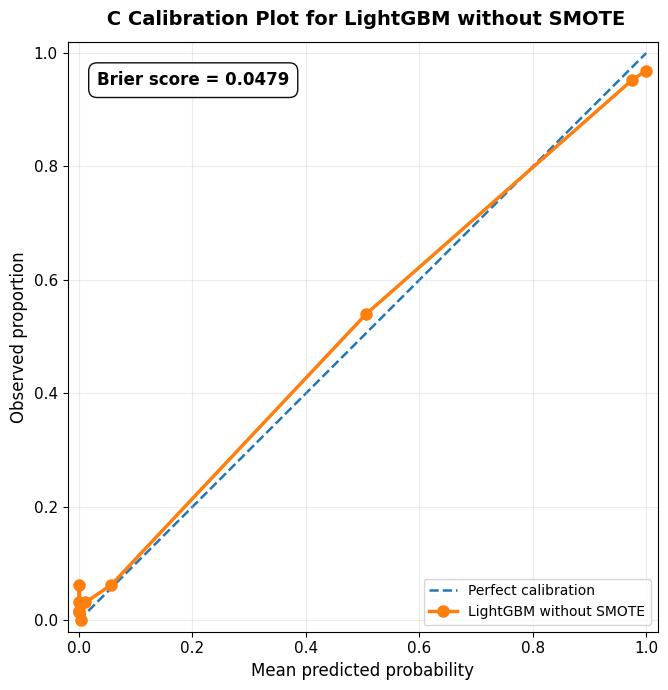

Brier score: 0.0479


In [53]:

import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss

# Calculate Brier score
brier_score = brier_score_loss(y_true, y_prob)

fig, ax = plt.subplots(figsize=(7, 7))

# Perfect calibration reference (plot first)
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.8,
    label="Perfect calibration",
    zorder=1
)

# Calibration curve (plot above reference line)
ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    markersize=8,
    linewidth=2.5,
    label="LightGBM without SMOTE",
    zorder=3,
    clip_on=False
)

# UPDATED: Give the curve more space near the origin
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("Mean predicted probability", fontsize=12)
ax.set_ylabel("Observed proportion", fontsize=12)

ax.set_title(
    " C Calibration Plot for LightGBM without SMOTE",
    fontsize=14,
    fontweight="bold",
    pad=12
)


# Display Brier score prominently
ax.text(
    0.05,
    0.95,
    f"Brier score = {brier_score:.4f}",
    transform=ax.transAxes,
    fontsize=12,
    fontweight="bold",
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="black",
        alpha=0.95
    )
)

ax.tick_params(axis="both", labelsize=11)
ax.legend(loc="lower right", fontsize=10, frameon=True)
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "LightGBM_No_SMOTE_calibration_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Brier score: {brier_score:.4f}")




# XGBoost 

In [35]:
import pandas as pd

df = pd.read_csv("nested_cv_out_of_fold_predictions.csv")

print("Column names:")
print(df.columns.tolist())

print("\nFirst five rows:")
print(df.head())

Column names:
['Model', 'Condition', 'Row_Index', 'y_true', 'y_pred', 'y_probability']

First five rows:
                 Model Condition  Row_Index  y_true  y_pred  y_probability
0  Logistic Regression  No_SMOTE          0       0       0       0.319236
1  Logistic Regression  No_SMOTE          1       0       0       0.347299
2  Logistic Regression  No_SMOTE          2       0       1       0.736288
3  Logistic Regression  No_SMOTE         10       0       0       0.124884
4  Logistic Regression  No_SMOTE         19       0       0       0.008574


Number of predictions: 634
Outcome prevalence: 0.2681


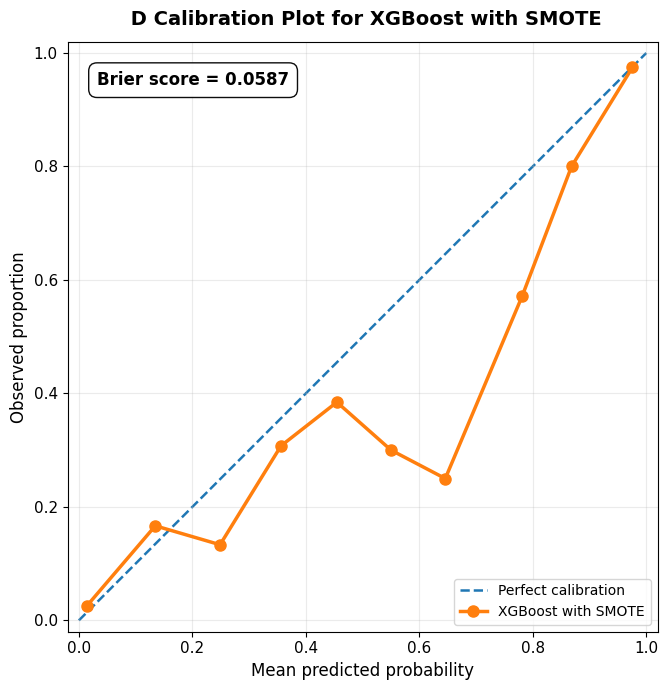

XGBoost with SMOTE Brier score: 0.0587


In [48]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

# 1. Load nested CV out-of-fold predictions
df = pd.read_csv("nested_cv_out_of_fold_predictions.csv")

# 2. Select XGBoost with SMOTE only
xgb = df[
    (df["Model"] == "XGBoost") &
    (df["Condition"] == "SMOTE")
].copy()

if xgb.empty:
    raise ValueError("No XGBoost SMOTE predictions found in the CSV.")

# 3. Extract actual outcomes and predicted probabilities
y_true = xgb["y_true"].astype(int)
y_prob = xgb["y_probability"].astype(float)

print("Number of predictions:", len(xgb))
print("Outcome prevalence:", round(y_true.mean(), 4))

# 4. Calculate Brier score
brier_score = brier_score_loss(y_true, y_prob)

# 5. Calculate calibration curve
prob_true, prob_pred = calibration_curve(
    y_true,
    y_prob,
    n_bins=10,
    strategy="uniform"
)

# 6. Plot calibration curve
fig, ax = plt.subplots(figsize=(7, 7))

# Perfect calibration reference
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    linewidth=1.8,
    label="Perfect calibration",
    zorder=1
)

# XGBoost with SMOTE
ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    markersize=8,
    linewidth=2.5,
    label="XGBoost with SMOTE",
    zorder=3,
    clip_on=False
)

# Axes
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("Mean predicted probability", fontsize=12)
ax.set_ylabel("Observed proportion", fontsize=12)
ax.set_title(
    " D Calibration Plot for XGBoost with SMOTE",
    fontsize=14,
    fontweight="bold",
    pad=12
)

# Brier score annotation
ax.text(
    0.05, 0.95,
    f"Brier score = {brier_score:.4f}",
    transform=ax.transAxes,
    fontsize=12,
    fontweight="bold",
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="black",
        alpha=0.95
    )
)

ax.tick_params(axis="both", labelsize=11)
ax.legend(loc="lower right", fontsize=10)
ax.grid(alpha=0.25)

plt.tight_layout()

# 7. Save high-resolution figure
plt.savefig(
    "XGBoost_SMOTE_calibration_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"XGBoost with SMOTE Brier score: {brier_score:.4f}")

# SHAP for the NESTED CV SHAP ANALYSIS FOR LIGHTGBM SMOTE Vs No SMOTE-Main analysis

Dataset shape: (634, 25)
Number of participants: 634
ALP included: True
ALP missingness before fold-specific imputation: 46.85 %
Outcome distribution:
HBsAg_Status
0    464
1    170
Name: count, dtype: int64

Numeric predictors: ['Age', 'ART_Duration', 'WBC', 'HGB', 'HCT', 'PLT', 'MCH', 'MCHC', 'MVC', 'NE#', 'LY#', 'RBC', 'RDW', 'CREA', 'BILT', 'ALB', 'V-LOAD', 'CD4', 'ALP', 'AST', 'ALT']
Categorical predictors: ['District', 'Sex', 'Regimen']

Saved fold-specific parameters verified for both models.

RUNNING OOF SHAP: LightGBM | No_SMOTE
Fold 1/5: training n=507, held-out n=127
Feature names used for SHAP:
['Age', 'ART_Duration', 'WBC', 'HGB', 'HCT', 'PLT', 'MCH', 'MCHC', 'MVC', 'NE#', 'LY#', 'RBC', 'RDW', 'CREA', 'BILT', 'ALB', 'V-LOAD', 'CD4', 'ALP', 'AST', 'ALT', 'District_AGAGO', 'District_BUIKWE', 'District_BUTAMBALA', 'District_Bundibugyo', 'District_Bushenyi', 'District_FORT PORTAL CITY', 'District_GOMBA', 'District_Gulu', 'District_Hoima', 'District_Iganga', 'District_Jinja', '

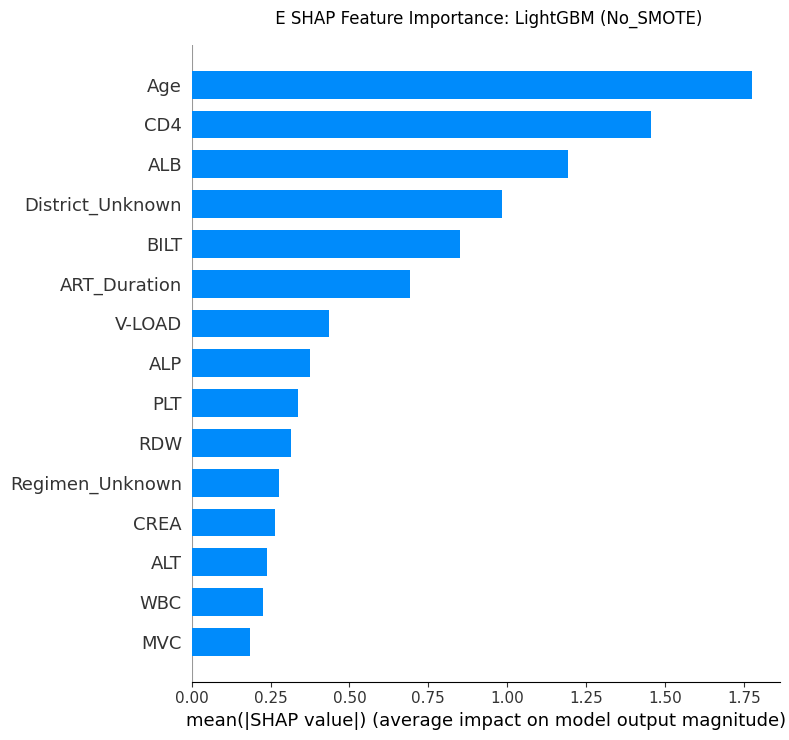

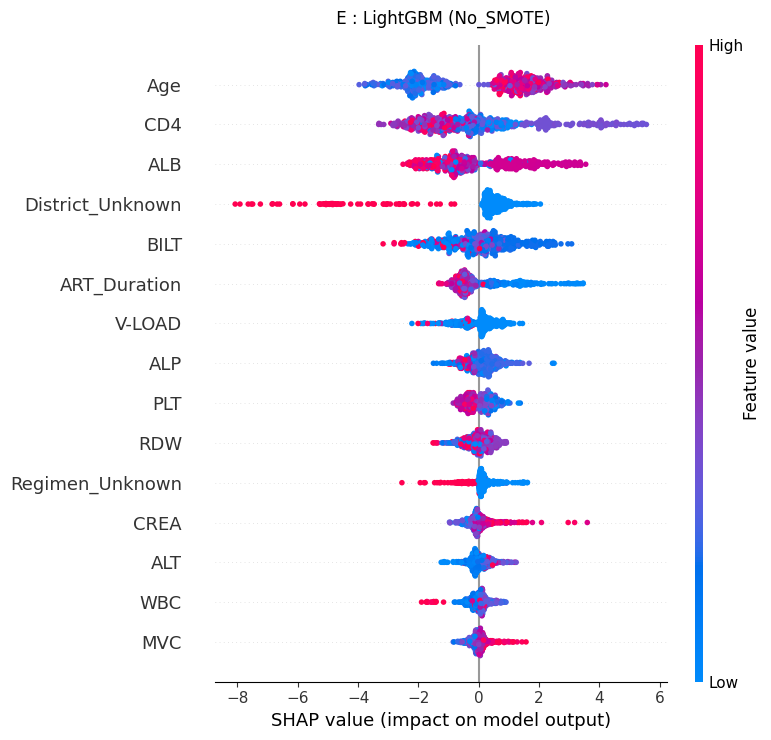


Saved files:
SHAP_OOF_Main_Analysis_ALP_Included\LightGBM_No_SMOTE_OOF_SHAP_values.csv
SHAP_OOF_Main_Analysis_ALP_Included\LightGBM_No_SMOTE_SHAP_importance.csv
SHAP_OOF_Main_Analysis_ALP_Included\LightGBM_No_SMOTE_SHAP_bar_top15.png
SHAP_OOF_Main_Analysis_ALP_Included\LightGBM_No_SMOTE_SHAP_beeswarm_top15.png

RUNNING OOF SHAP: XGBoost | SMOTE
Fold 1/5: training n=507, held-out n=127
Feature names used for SHAP:
['Age', 'ART_Duration', 'WBC', 'HGB', 'HCT', 'PLT', 'MCH', 'MCHC', 'MVC', 'NE#', 'LY#', 'RBC', 'RDW', 'CREA', 'BILT', 'ALB', 'V-LOAD', 'CD4', 'ALP', 'AST', 'ALT', 'District_AGAGO', 'District_BUIKWE', 'District_BUTAMBALA', 'District_Bundibugyo', 'District_Bushenyi', 'District_FORT PORTAL CITY', 'District_GOMBA', 'District_Gulu', 'District_Hoima', 'District_Iganga', 'District_Jinja', 'District_KIRYANDONGO', 'District_Kabale', 'District_Kampala', 'District_Kamuli', 'District_Kamwenge', 'District_Kayunga', 'District_Kiboga', 'District_Kiruhura', 'District_Luwero', 'District_Lyant

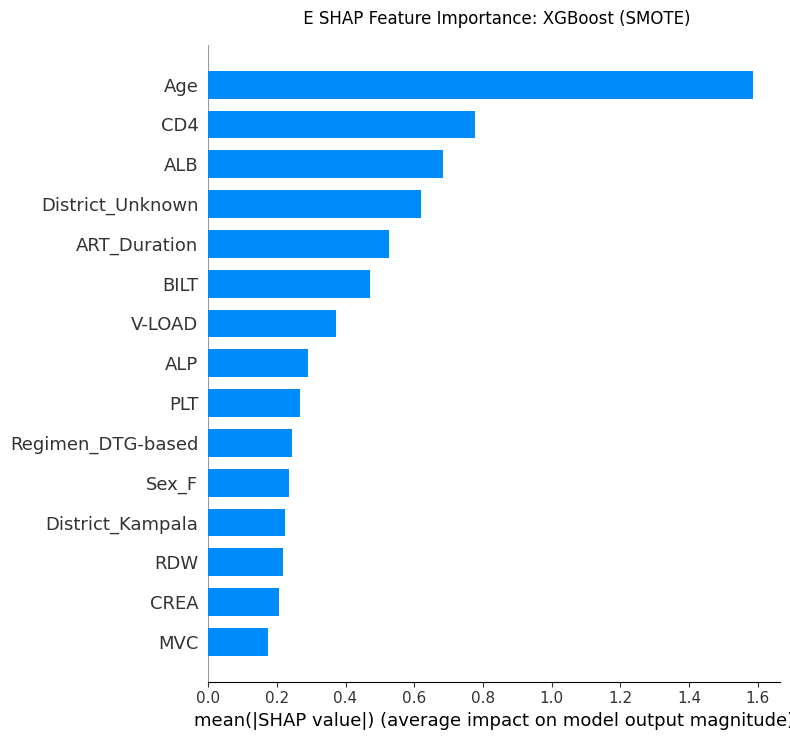

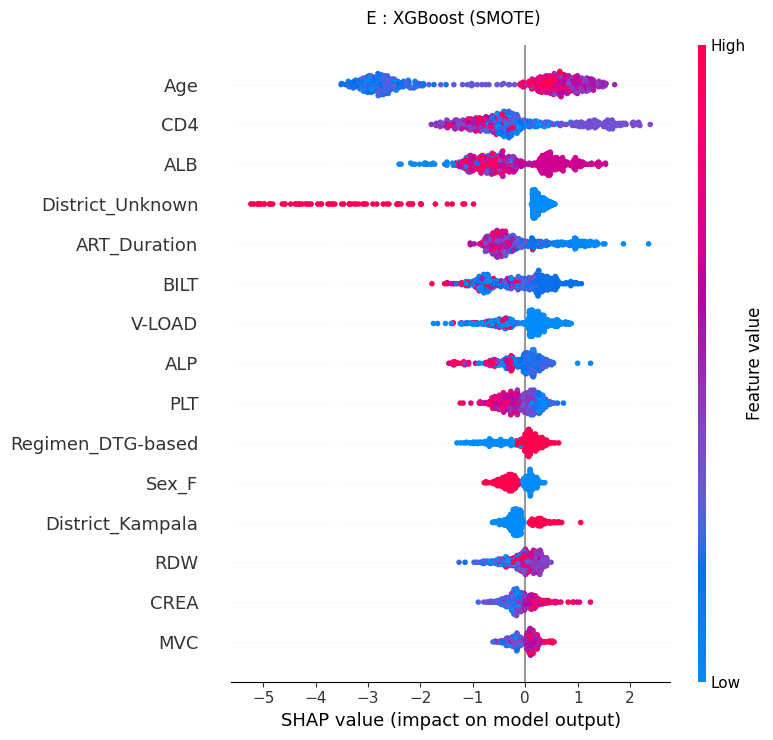


Saved files:
SHAP_OOF_Main_Analysis_ALP_Included\XGBoost_SMOTE_OOF_SHAP_values.csv
SHAP_OOF_Main_Analysis_ALP_Included\XGBoost_SMOTE_SHAP_importance.csv
SHAP_OOF_Main_Analysis_ALP_Included\XGBoost_SMOTE_SHAP_bar_top15.png
SHAP_OOF_Main_Analysis_ALP_Included\XGBoost_SMOTE_SHAP_beeswarm_top15.png

SHAP ANALYSIS FINISHED
Output folder: SHAP_OOF_Main_Analysis_ALP_Included
Models: LightGBM (No_SMOTE), XGBoost (SMOTE)
Plots generated: 4


In [54]:

# ============================================================
# STEP 3: OUT-OF-FOLD SHAP ANALYSIS FOR THE TWO BEST MODELS
#
# Main analysis:
#   1. LightGBM - No_SMOTE
#   2. XGBoost - SMOTE
#
# Outputs per model:
#   - SHAP bar plot (top 15)
#   - SHAP beeswarm plot (top 15)
#   - Out-of-fold SHAP values CSV
#   - Mean absolute SHAP importance CSV
#
# ALP IS RETAINED.
# SMOTE IS APPLIED TO OUTER TRAINING DATA ONLY.
# ============================================================

import os
import ast
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from imblearn.over_sampling import SMOTE

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

SEED = 42
N_SPLITS = 5
TARGET = "HBsAg_Status"
DATA_FILE = "cleaned_dataset_main_analysis.csv"
PARAM_FILE = "nested_cv_best_parameters.csv"

OUTPUT_DIR = "SHAP_OOF_Main_Analysis_ALP_Included"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. LOAD DATA AND SAVED TUNED PARAMETERS
# ------------------------------------------------------------

df = pd.read_csv(DATA_FILE)
params_df = pd.read_csv(PARAM_FILE)

if TARGET not in df.columns:
    raise ValueError(f"Missing outcome column: {TARGET}")

if "ALP" not in df.columns:
    raise ValueError(
        "ALP is missing. Stop and load the correct main-analysis dataset."
    )

if df[TARGET].isna().any():
    raise ValueError("The outcome contains missing values.")

y = pd.to_numeric(df[TARGET], errors="raise").astype(int)

if set(y.unique()) != {0, 1}:
    raise ValueError(
        f"Expected binary outcome coded 0/1; found {sorted(y.unique())}"
    )

X = df.drop(columns=[TARGET]).copy()

# Verify that only the intended high-missingness variables were removed.
print("Dataset shape:", df.shape)
print("Number of participants:", len(df))
print("ALP included:", "ALP" in X.columns)
print("ALP missingness before fold-specific imputation:",
      round(X["ALP"].isna().mean() * 100, 2), "%")
print("Outcome distribution:")
print(y.value_counts().sort_index())

# Convert known categorical predictors to consistent text values.
known_categorical = [
    col for col in ["Sex", "District", "Regimen"]
    if col in X.columns
]

for col in known_categorical:
    X[col] = X[col].where(X[col].notna(), "Unknown").astype(str)
    X[col] = X[col].replace(
        {"": "Unknown", "UNK": "Unknown", "N/A": "Unknown",
         "unknown": "Unknown"}
    )

# Convert other object columns to numeric where possible.
# This avoids treating malformed numeric entries as categories.
for col in X.columns:
    if col not in known_categorical and X[col].dtype == "object":
        converted = pd.to_numeric(X[col], errors="coerce")
        original_nonmissing = X[col].notna().sum()

        if original_nonmissing and (
            converted.notna().sum() / original_nonmissing >= 0.80
        ):
            X[col] = converted

# Identify numeric and categorical predictors.
categorical_cols = [
    col for col in X.columns
    if col in known_categorical or
    X[col].dtype == "object" or
    str(X[col].dtype) == "category"
]
numeric_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

# Force numeric predictors to numeric values.
for col in numeric_cols:
    X[col] = pd.to_numeric(X[col], errors="coerce")

print("\nNumeric predictors:", numeric_cols)
print("Categorical predictors:", categorical_cols)

# ------------------------------------------------------------
# 2. SELECT THE SAVED BEST PARAMETERS FOR EACH OUTER FOLD
# ------------------------------------------------------------

selected_models = {
    "No_SMOTE": "LightGBM",
    "SMOTE": "XGBoost",
}

def get_fold_parameters(model_name, condition, fold_number):
    selected = params_df[
        (params_df["Model"] == model_name) &
        (params_df["Condition"] == condition) &
        (params_df["Outer_Fold"] == fold_number)
    ]

    if len(selected) != 1:
        raise ValueError(
            f"Expected one parameter record for {model_name}, "
            f"{condition}, fold {fold_number}; found {len(selected)}."
        )

    raw_params = selected.iloc[0]["Best_Parameters"]
    parsed = ast.literal_eval(raw_params) if isinstance(raw_params, str) else raw_params

    # Remove sklearn Pipeline prefix from the saved parameter names.
    return {
        key.replace("classifier__", ""): value
        for key, value in parsed.items()
    }

# Confirm all five saved parameter sets exist before fitting.
for condition, model_name in selected_models.items():
    for fold_number in range(1, N_SPLITS + 1):
        get_fold_parameters(model_name, condition, fold_number)

print("\nSaved fold-specific parameters verified for both models.")


# ------------------------------------------------------------
# HELPER: CLEAN TRANSFORMED FEATURE NAMES FOR SHAP
# ------------------------------------------------------------

def clean_shap_feature_names(feature_names):
    """
    Remove preprocessing prefixes while preserving original
    predictor names and one-hot category labels.
    """
    cleaned_names = []

    for name in feature_names:
        name = str(name)

        for prefix in [
            "num__",
            "cat__",
            "numeric__",
            "categorical__",
            "num_",
            "Cat_"
        ]:
            if name.startswith(prefix):
                name = name[len(prefix):]
                break

        cleaned_names.append(name)

    return cleaned_names

# ------------------------------------------------------------
# 3. RECREATE OUTER FOLDS AND CALCULATE HELD-OUT SHAP VALUES
# ------------------------------------------------------------

outer_cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

# Store explanations for each model-condition separately.
all_explanations = {}

for condition, model_name in selected_models.items():

    print("\n" + "=" * 75)
    print(f"RUNNING OOF SHAP: {model_name} | {condition}")
    print("=" * 75)

    fold_records = []

    for fold_number, (train_idx, test_idx) in enumerate(
        outer_cv.split(X, y), start=1
    ):
        print(
            f"Fold {fold_number}/{N_SPLITS}: "
            f"training n={len(train_idx)}, held-out n={len(test_idx)}"
        )

        X_train = X.iloc[train_idx].copy()
        X_test = X.iloc[test_idx].copy()
        y_train = y.iloc[train_idx].copy()

        # Fit preprocessing on the outer training fold only.
        numeric_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ])

        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ])

        transformers = []

        if numeric_cols:
            transformers.append(
                ("num", numeric_pipeline, numeric_cols)
            )

        if categorical_cols:
            transformers.append(
                ("cat", categorical_pipeline, categorical_cols)
            )

        preprocessor = ColumnTransformer(
            transformers=transformers,
            remainder="drop",
            verbose_feature_names_out=True
        )

        X_train_transformed = preprocessor.fit_transform(X_train)
        X_test_transformed = preprocessor.transform(X_test)

        feature_names = preprocessor.get_feature_names_out().tolist()
        
        # Get the feature names generated by preprocessing
        feature_names_transformed = (
        preprocessor.get_feature_names_out().tolist()
)

        # Remove prefixes such as num__ and cat__
        feature_names = clean_shap_feature_names(
        feature_names_transformed
)

        print("Feature names used for SHAP:")
        print(feature_names)

        X_train_transformed = np.asarray(
            X_train_transformed, dtype=float
        )
        X_test_transformed = np.asarray(
            X_test_transformed, dtype=float
        )

        # Apply SMOTE to the training fold only.
        if condition == "SMOTE":
            sampler = SMOTE(random_state=SEED)
            X_fit, y_fit = sampler.fit_resample(
                X_train_transformed, y_train
            )
        else:
            X_fit, y_fit = X_train_transformed, y_train

        # Load the tuned parameters for this exact outer fold.
        model_params = get_fold_parameters(
            model_name, condition, fold_number
        )
        model_params["random_state"] = SEED
        model_params["n_jobs"] = -1

        if model_name == "LightGBM":
            model_params["verbosity"] = -1
            classifier = LGBMClassifier(**model_params)

        elif model_name == "XGBoost":
            model_params["eval_metric"] = "logloss"
            classifier = XGBClassifier(**model_params)

        else:
            raise ValueError(f"Unsupported model: {model_name}")

        classifier.fit(X_fit, y_fit)

        # Explain only participants held out from this outer fold.
        explainer = shap.TreeExplainer(classifier)
        shap_result = explainer.shap_values(X_test_transformed)

        # Support different SHAP return formats across versions.
        if isinstance(shap_result, list):
            shap_values = np.asarray(shap_result[-1])
        else:
            shap_values = np.asarray(shap_result)

        # Some versions return (participants, features, classes).
        if shap_values.ndim == 3:
            shap_values = shap_values[:, :, 1]

        if shap_values.shape != X_test_transformed.shape:
            raise ValueError(
                f"Unexpected SHAP shape {shap_values.shape}; "
                f"test matrix shape is {X_test_transformed.shape}."
            )

        # Keep fold-specific feature names to align them later.
        fold_records.append({
            "fold": fold_number,
            "test_indices": test_idx.copy(),
            "feature_names": feature_names,
            "shap_values": shap_values,
            "feature_values": X_test_transformed
        })

    # --------------------------------------------------------
    # 4. ALIGN FEATURES ACROSS FOLDS
    # --------------------------------------------------------

    # One-hot categories can differ between training folds.
    # Align all fold explanations by transformed feature name.
    feature_union = []
    for record in fold_records:
        for name in record["feature_names"]:
            if name not in feature_union:
                feature_union.append(name)

    n_rows = len(X)
    n_features = len(feature_union)

    oof_shap = np.zeros((n_rows, n_features), dtype=float)
    oof_feature_values = np.zeros((n_rows, n_features), dtype=float)
    seen = np.zeros(n_rows, dtype=int)

    name_to_position = {
        name: position for position, name in enumerate(feature_union)
    }

    for record in fold_records:
        test_indices = record["test_indices"]
        local_names = record["feature_names"]

        for local_position, name in enumerate(local_names):
            global_position = name_to_position[name]

            oof_shap[test_indices, global_position] = (
                record["shap_values"][:, local_position]
            )
            oof_feature_values[test_indices, global_position] = (
                record["feature_values"][:, local_position]
            )

        seen[test_indices] += 1

    if not np.all(seen == 1):
        raise ValueError(
            "Outer folds did not explain each participant exactly once. "
            f"Counts observed: {np.unique(seen, return_counts=True)}"
        )

    all_explanations[condition] = {
        "model": model_name,
        "feature_names": feature_union,
        "shap_values": oof_shap,
        "feature_values": oof_feature_values
    }

    # Save participant-level SHAP values in long format.
    shap_long = pd.DataFrame({
        "Row_Index": np.repeat(np.arange(n_rows), n_features),
        "y_true": np.repeat(y.to_numpy(), n_features),
        "Feature": np.tile(feature_union, n_rows),
        "Feature_Value": oof_feature_values.reshape(-1),
        "SHAP_Value": oof_shap.reshape(-1),
        "Abs_SHAP": np.abs(oof_shap).reshape(-1)
    })

    shap_csv = os.path.join(
        OUTPUT_DIR,
        f"{model_name}_{condition}_OOF_SHAP_values.csv"
    )
    shap_long.to_csv(shap_csv, index=False)

    # Save global mean absolute SHAP feature importance.
    importance = pd.DataFrame({
        "Feature": feature_union,
        "Mean_Abs_SHAP": np.mean(np.abs(oof_shap), axis=0)
    }).sort_values("Mean_Abs_SHAP", ascending=False)

    importance_csv = os.path.join(
        OUTPUT_DIR,
        f"{model_name}_{condition}_SHAP_importance.csv"
    )
    importance.to_csv(importance_csv, index=False)

    print("\nTop 15 features:")
    print(importance.head(15).to_string(index=False))

    # --------------------------------------------------------
    # 5. SHAP BAR PLOT: TOP 15
    # --------------------------------------------------------

    plt.figure(figsize=(10, 7))
    shap.summary_plot(
        oof_shap,
        oof_feature_values,
        feature_names=feature_union,
        plot_type="bar",
        max_display=15,
        show=False
    )
    plt.title(
        f" E SHAP Feature Importance: {model_name} ({condition})",
        pad=15
    )
    plt.tight_layout()

    bar_path = os.path.join(
        OUTPUT_DIR,
        f"{model_name}_{condition}_SHAP_bar_top15.png"
    )
    plt.savefig(bar_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    # --------------------------------------------------------
    # 6. SHAP BEESWARM PLOT: TOP 15
    # --------------------------------------------------------

    plt.figure(figsize=(10, 7))
    shap.summary_plot(
        oof_shap,
        oof_feature_values,
        feature_names=feature_union,
        plot_type="dot",
        max_display=15,
        show=False
    )
    plt.title(
        f" E : {model_name} ({condition})",
        pad=15
    )
    plt.tight_layout()

    beeswarm_path = os.path.join(
        OUTPUT_DIR,
        f"{model_name}_{condition}_SHAP_beeswarm_top15.png"
    )
    plt.savefig(beeswarm_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("\nSaved files:")
    print(shap_csv)
    print(importance_csv)
    print(bar_path)
    print(beeswarm_path)

print("\n" + "=" * 75)
print("SHAP ANALYSIS FINISHED")
print("Output folder:", OUTPUT_DIR)
print("Models: LightGBM (No_SMOTE), XGBoost (SMOTE)")
print("Plots generated: 4")
print("=" * 75)

# Complete Case Analysis

# new

LOADING DATA

Original dataset shape:
(634, 29)

Columns:
['District', 'Sex', 'Age', 'ART_Duration', 'Regimen', 'WBC', 'HGB', 'HCT', 'PLT', 'MCH', 'MCHC', 'MVC', 'NE#', 'LY#', 'RBC', 'RDW', 'CREA', 'BILT', 'BILD', 'ALB', 'V-LOAD', 'CD4', 'ALP', 'AST', 'ALT', 'GGT', 'NA+', 'K+', 'HBsAg_Status']

Target:
HBsAg_Status

Categorical features:
['District', 'Sex', 'Regimen']

Numeric features:
['Age', 'ART_Duration', 'V-LOAD', 'CD4', 'WBC', 'HGB', 'HCT', 'MVC', 'CREA', 'NA+', 'K+', 'BILT', 'BILD', 'ALB', 'AST', 'ALT', 'ALP']

Total predictors:
20

Converting numeric variables to numeric...

Missing values before complete-case filtering:
NA+       468
K+        468
BILD      442
ALP       297
ALB       211
BILT      184
CD4       113
V-LOAD     92
AST        85
HGB        61
WBC        57
HCT        57
MVC        57
CREA       45
ALT        37
dtype: int64

COMPLETE-CASE DATASET

Original rows: 634
Complete-case rows: 107
Rows excluded: 527
Percentage retained: 16.88%

Outcome distribution:
HB

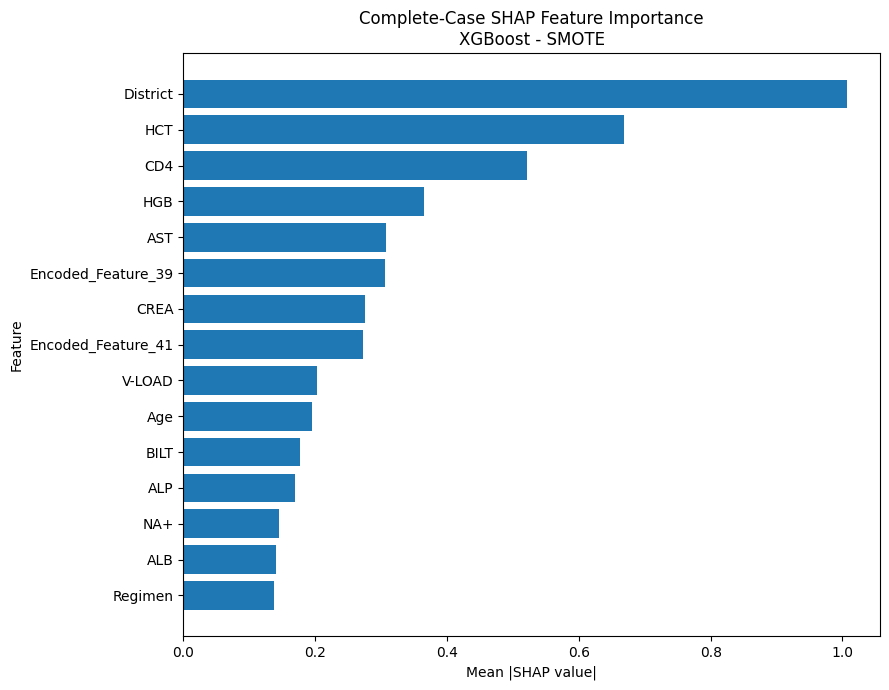

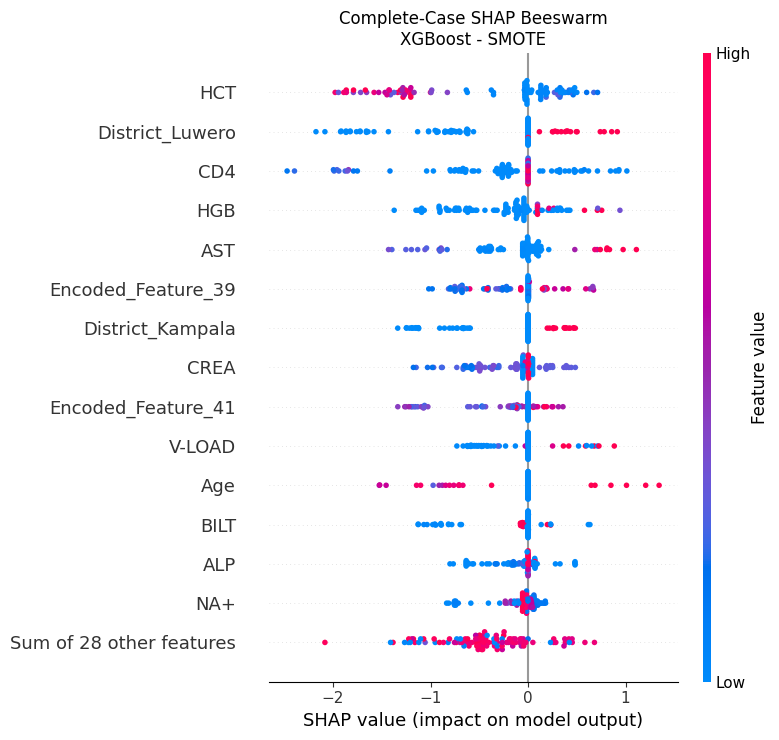


ANALYSIS COMPLETE

Complete-case sample size: 107
Number of predictors: 20

Conditions evaluated:
  1. Without SMOTE
  2. With SMOTE

Primary selection metric: MCC
Additional performance metric: ROC-AUC

Nested CV:
  Outer folds = 5
  Inner folds = 5

Best complete-case model-condition:
  Model = XGBoost
  Condition = Yes
  MCC = 0.124 (-0.270–0.519)
  ROC-AUC = 0.800 (0.580–1.021)

Results saved to:
c:\Users\jnabateesa\Videos\Masterproject\complete_case_sensitivity_results

IMPORTANT:
For the final manuscript sensitivity analysis, set PRIMARY_BEST_MODEL_NAME to the model selected in the PRIMARY analysis before interpreting the SHAP sensitivity results.


In [110]:
# ================================================================
# COMPLETE-CASE SENSITIVITY ANALYSIS
# Reviewer 5:
# "Rerun the best model on complete cases only and compare the
# SHAP rankings with the main analysis."
#
# Two conditions:
#   1. WITHOUT SMOTE
#   2. WITH SMOTE
#
# Nested 5-fold stratified CV
# Inner-fold hyperparameter tuning
# MCC = primary model-selection metric
# ROC-AUC + additional metrics = performance metrics
#
# ALP is included in this complete-case sensitivity analysis.
# ================================================================


# ================================================================
# 1. IMPORT LIBRARIES
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from scipy.stats import t

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.metrics import (
    matthews_corrcoef,
    roc_auc_score,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC

from imblearn.over_sampling import SMOTE


# ================================================================
# 2. OPTIONAL MODELS
# ================================================================

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost is not installed. It will be skipped.")

try:
    from lightgbm import LGBMClassifier
    LIGHTGBM_AVAILABLE = True
except ImportError:
    LIGHTGBM_AVAILABLE = False
    print("LightGBM is not installed. It will be skipped.")

try:
    from catboost import CatBoostClassifier
    CATBOOST_AVAILABLE = True
except ImportError:
    CATBOOST_AVAILABLE = False
    print("CatBoost is not installed. It will be skipped.")


# ================================================================
# 3. SHAP
# ================================================================

try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("SHAP is not installed. SHAP analysis will be skipped.")


# ================================================================
# 4. SETTINGS
# ================================================================

SEED = 42

DATA_FILE = "cleaned_dataset.csv"

OUTPUT_DIR = "complete_case_sensitivity_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTER_SPLITS = 5
INNER_SPLITS = 5

SELECTION_METRIC = "MCC"

# ---------------------------------------------------------------
# IMPORTANT:
#
# For the FINAL manuscript sensitivity analysis, enter the model
# identified as the BEST MODEL in your PRIMARY analysis.
#
# Example:
# PRIMARY_BEST_MODEL_NAME = "XGBoost"
#
# Leave as None initially if you want this script to first show
# which model performs best in the complete-case data.
# ---------------------------------------------------------------

PRIMARY_BEST_MODEL_NAME = None

# If True:
#   evaluate all models and both SMOTE conditions.
#
# If False AND PRIMARY_BEST_MODEL_NAME is supplied:
#   evaluate only the primary best model under both conditions.
#
RUN_ALL_MODELS = True


# ================================================================
# 5. LOAD DATA
# ================================================================

print("=" * 80)
print("LOADING DATA")
print("=" * 80)

df = pd.read_csv(DATA_FILE)

print("\nOriginal dataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())


# ================================================================
# 6. DEFINE TARGET AND COMPLETE-CASE FEATURES
# ================================================================

TARGET = "HBsAg_Status"

# IMPORTANT:
# ALP IS INCLUDED HERE because this is the complete-case
# sensitivity analysis.

CATEGORICAL_FEATURES = [
    "District",
    "Sex",
    "Regimen"
]

NUMERIC_FEATURES = [
    "Age",
    "ART_Duration",
    "V-LOAD",
    "CD4",
    "WBC",
    "HGB",
    "HCT",
    "MVC",
    "CREA",
    "NA+",
    "K+",
    "BILT",
    "BILD",
    "ALB",
    "AST",
    "ALT",
    "ALP"
]

FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

print("\nTarget:")
print(TARGET)

print("\nCategorical features:")
print(CATEGORICAL_FEATURES)

print("\nNumeric features:")
print(NUMERIC_FEATURES)

print("\nTotal predictors:")
print(len(FEATURES))


# ================================================================
# 7. CHECK REQUIRED COLUMNS
# ================================================================

required_columns = FEATURES + [TARGET]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"The following required columns are missing from the dataset:\n"
        f"{missing_columns}"
    )


# ================================================================
# 8. COPY DATA
# ================================================================

data = df[required_columns].copy()


# ================================================================
# 9. CLEAN TARGET
# ================================================================

data[TARGET] = pd.to_numeric(
    data[TARGET],
    errors="coerce"
)

# Keep only binary target values
data = data[
    data[TARGET].isin([0, 1])
].copy()

data[TARGET] = data[TARGET].astype(int)


# ================================================================
# 10. CLEAN NUMERIC VARIABLES
# ================================================================
#
# This is particularly important because the previous analysis
# encountered values such as:
#
#     "13..2"
#
# These are converted to NaN and therefore excluded from the
# COMPLETE-CASE dataset.
# ================================================================

print("\nConverting numeric variables to numeric...")

for col in NUMERIC_FEATURES:

    before_non_numeric = data[col].notna().sum()

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

    after_numeric = data[col].notna().sum()

    converted_to_nan = before_non_numeric - after_numeric

    if converted_to_nan > 0:
        print(
            f"{col}: {converted_to_nan} non-numeric values "
            f"converted to NaN"
        )


# ================================================================
# 11. STANDARDIZE CATEGORICAL VARIABLES
# ================================================================

for col in CATEGORICAL_FEATURES:

    data[col] = (
        data[col]
        .astype("string")
        .str.strip()
        .replace({
            "": pd.NA,
            "nan": pd.NA,
            "None": pd.NA,
            "NULL": pd.NA
        })
        .fillna("Unknown")
        .astype(str)
    )


# ================================================================
# 12. REMOVE COMPLETE-CASE MISSING VALUES
# ================================================================

print("\nMissing values before complete-case filtering:")

missing_before = data[FEATURES + [TARGET]].isna().sum()

print(
    missing_before[
        missing_before > 0
    ].sort_values(
        ascending=False
    )
)


# Complete case = no missing value in ANY predictor or target
complete_case_mask = (
    data[FEATURES + [TARGET]]
    .notna()
    .all(axis=1)
)

complete_data = data.loc[
    complete_case_mask
].copy()

print("\n" + "=" * 80)
print("COMPLETE-CASE DATASET")
print("=" * 80)

print(
    f"\nOriginal rows: {len(data)}"
)

print(
    f"Complete-case rows: {len(complete_data)}"
)

print(
    f"Rows excluded: {len(data) - len(complete_data)}"
)

print(
    f"Percentage retained: "
    f"{100 * len(complete_data) / len(data):.2f}%"
)


# ================================================================
# 13. COMPLETE-CASE OUTCOME DISTRIBUTION
# ================================================================

print("\nOutcome distribution:")

outcome_counts = (
    complete_data[TARGET]
    .value_counts()
    .sort_index()
)

outcome_percent = (
    complete_data[TARGET]
    .value_counts(
        normalize=True
    )
    .sort_index()
    * 100
)

for value in [0, 1]:

    if value in outcome_counts.index:

        print(
            f"HBsAg_Status={value}: "
            f"{outcome_counts[value]} "
            f"({outcome_percent[value]:.1f}%)"
        )


# ================================================================
# 14. X AND Y
# ================================================================

X = complete_data[FEATURES].copy()

y = complete_data[TARGET].copy()


# ================================================================
# 15. ONE-HOT ENCODER COMPATIBILITY
# ================================================================

try:

    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )

except TypeError:

    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )


# ================================================================
# 16. PREPROCESSOR
# ================================================================
#
# Complete-case data have no missing values, but imputers are
# retained INSIDE the pipeline so the workflow remains leakage-free
# and identical in structure to the main nested-CV analysis.
# ================================================================

def create_preprocessor(use_scaling=False):

    categorical_pipeline = SklearnPipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                )
            )
        ]
    )

    numeric_steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if use_scaling:

        numeric_steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    numeric_pipeline = SklearnPipeline(
        steps=numeric_steps
    )

    return ColumnTransformer(
        transformers=[
            (
                "cat",
                categorical_pipeline,
                CATEGORICAL_FEATURES
            ),
            (
                "num",
                numeric_pipeline,
                NUMERIC_FEATURES
            )
        ],
        remainder="drop"
    )


# ================================================================
# 17. MODEL DEFINITIONS
# ================================================================

models = {}

param_grids = {}


# ---------------------------------------------------------------
# Logistic Regression
# ---------------------------------------------------------------

models["Logistic Regression"] = LogisticRegression(
    max_iter=5000,
    random_state=SEED
)

param_grids["Logistic Regression"] = {
    "classifier__C": [
        0.01,
        0.1,
        1,
        10,
        100
    ],
    "classifier__solver": [
        "liblinear",
        "lbfgs"
    ]
}


# ---------------------------------------------------------------
# Decision Tree
# ---------------------------------------------------------------

models["Decision Tree"] = DecisionTreeClassifier(
    random_state=SEED
)

param_grids["Decision Tree"] = {
    "classifier__max_depth": [
        None,
        2,
        3,
        5,
        10
    ],
    "classifier__min_samples_split": [
        2,
        5,
        10
    ],
    "classifier__min_samples_leaf": [
        1,
        2,
        5
    ]
}


# ---------------------------------------------------------------
# Random Forest
# ---------------------------------------------------------------

models["Random Forest"] = RandomForestClassifier(
    random_state=SEED,
    n_jobs=-1
)

param_grids["Random Forest"] = {
    "classifier__n_estimators": [
        100,
        300
    ],
    "classifier__max_depth": [
        None,
        5,
        10
    ],
    "classifier__min_samples_leaf": [
        1,
        2,
        5
    ],
    "classifier__max_features": [
        "sqrt",
        "log2"
    ]
}


# ---------------------------------------------------------------
# SVM
# ---------------------------------------------------------------

models["SVM"] = SVC(
    probability=True,
    random_state=SEED
)

param_grids["SVM"] = {
    "classifier__C": [
        0.1,
        1,
        10
    ],
    "classifier__gamma": [
        "scale",
        "auto"
    ],
    "classifier__kernel": [
        "rbf"
    ]
}


# ---------------------------------------------------------------
# Gradient Boosting
# ---------------------------------------------------------------

models["Gradient Boosting"] = GradientBoostingClassifier(
    random_state=SEED
)

param_grids["Gradient Boosting"] = {
    "classifier__n_estimators": [
        50,
        100,
        200
    ],
    "classifier__learning_rate": [
        0.01,
        0.05,
        0.1
    ],
    "classifier__max_depth": [
        2,
        3,
        5
    ]
}


# ---------------------------------------------------------------
# XGBoost
# ---------------------------------------------------------------

if XGBOOST_AVAILABLE:

    models["XGBoost"] = XGBClassifier(
        random_state=SEED,
        eval_metric="logloss",
        n_jobs=-1
    )

    param_grids["XGBoost"] = {
        "classifier__n_estimators": [
            100,
            200
        ],
        "classifier__max_depth": [
            2,
            3,
            5
        ],
        "classifier__learning_rate": [
            0.03,
            0.05,
            0.1
        ],
        "classifier__subsample": [
            0.8,
            1.0
        ],
        "classifier__colsample_bytree": [
            0.8,
            1.0
        ]
    }


# ---------------------------------------------------------------
# LightGBM
# ---------------------------------------------------------------

if LIGHTGBM_AVAILABLE:

    models["LightGBM"] = LGBMClassifier(
        random_state=SEED,
        verbosity=-1,
        n_jobs=-1
    )

    param_grids["LightGBM"] = {
        "classifier__n_estimators": [
            100,
            200
        ],
        "classifier__num_leaves": [
            7,
            15,
            31
        ],
        "classifier__learning_rate": [
            0.03,
            0.05,
            0.1
        ],
        "classifier__max_depth": [
            -1,
            3,
            5
        ]
    }


# ---------------------------------------------------------------
# CatBoost
# ---------------------------------------------------------------

if CATBOOST_AVAILABLE:

    models["CatBoost"] = CatBoostClassifier(
        random_seed=SEED,
        verbose=False,
        thread_count=-1
    )

    param_grids["CatBoost"] = {
        "classifier__iterations": [
            100,
            200
        ],
        "classifier__depth": [
            3,
            5,
            7
        ],
        "classifier__learning_rate": [
            0.03,
            0.05,
            0.1
        ]
    }


# ================================================================
# 18. SELECT MODELS TO RUN
# ================================================================

if RUN_ALL_MODELS:

    selected_models = models.copy()

else:

    if PRIMARY_BEST_MODEL_NAME is None:

        raise ValueError(
            "PRIMARY_BEST_MODEL_NAME must be supplied when "
            "RUN_ALL_MODELS=False."
        )

    if PRIMARY_BEST_MODEL_NAME not in models:

        raise ValueError(
            f"{PRIMARY_BEST_MODEL_NAME} is not available. "
            f"Available models: {list(models.keys())}"
        )

    selected_models = {
        PRIMARY_BEST_MODEL_NAME:
        models[PRIMARY_BEST_MODEL_NAME]
    }


print("\nModels to evaluate:")

for name in selected_models:

    print(
        f"  - {name}"
    )


# ================================================================
# 19. OUTER AND INNER CV
# ================================================================

outer_cv = StratifiedKFold(
    n_splits=OUTER_SPLITS,
    shuffle=True,
    random_state=SEED
)


# ================================================================
# 20. PERFORMANCE METRIC FUNCTION
# ================================================================

def calculate_metrics(
    y_true,
    y_pred,
    y_prob
):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    try:
        auc = roc_auc_score(
            y_true,
            y_prob
        )
    except ValueError:
        auc = np.nan

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    sensitivity = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    balanced_accuracy = balanced_accuracy_score(
        y_true,
        y_pred
    )

    return {
        "MCC": mcc,
        "AUC": auc,
        "Accuracy": accuracy,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Precision": precision,
        "F1": f1,
        "Balanced_Accuracy": balanced_accuracy,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


# ================================================================
# 21. 95% CI FUNCTION
# ================================================================

def mean_ci(values, confidence=0.95):

    values = np.asarray(
        values,
        dtype=float
    )

    values = values[
        ~np.isnan(values)
    ]

    n = len(values)

    if n == 0:

        return np.nan, np.nan, np.nan

    mean_value = np.mean(values)

    if n == 1:

        return (
            mean_value,
            np.nan,
            np.nan
        )

    sd = np.std(
        values,
        ddof=1
    )

    se = sd / np.sqrt(n)

    t_critical = t.ppf(
        (1 + confidence) / 2,
        df=n - 1
    )

    margin = t_critical * se

    lower = mean_value - margin
    upper = mean_value + margin

    return (
        mean_value,
        lower,
        upper
    )


# ================================================================
# 22. NESTED CV FUNCTION
# ================================================================

def run_nested_cv(
    model_name,
    base_model,
    param_grid,
    use_smote
):

    print("\n" + "=" * 80)

    print(
        f"MODEL: {model_name}"
    )

    print(
        f"CONDITION: "
        f"{'WITH SMOTE' if use_smote else 'WITHOUT SMOTE'}"
    )

    print("=" * 80)

    outer_results = []

    fold_predictions = []

    for fold, (
        train_idx,
        test_idx
    ) in enumerate(
        outer_cv.split(X, y),
        start=1
    ):

        print(
            f"\nOuter fold {fold}/{OUTER_SPLITS}"
        )

        X_train = X.iloc[
            train_idx
        ].copy()

        X_test = X.iloc[
            test_idx
        ].copy()

        y_train = y.iloc[
            train_idx
        ].copy()

        y_test = y.iloc[
            test_idx
        ].copy()

        # --------------------------------------------------------
        # Scaling:
        # LR and SVM need scaling.
        # Tree-based models do not.
        # --------------------------------------------------------

        use_scaling = model_name in [
            "Logistic Regression",
            "SVM"
        ]

        preprocessor = create_preprocessor(
            use_scaling=use_scaling
        )

        # --------------------------------------------------------
        # Pipeline
        # --------------------------------------------------------

        if use_smote:

            pipeline = Pipeline(
                steps=[
                    (
                        "preprocessor",
                        preprocessor
                    ),
                    (
                        "smote",
                        SMOTE(
                            random_state=SEED,
                            k_neighbors=2
                        )
                    ),
                    (
                        "classifier",
                        clone(base_model)
                    )
                ]
            )

        else:

            pipeline = Pipeline(
                steps=[
                    (
                        "preprocessor",
                        preprocessor
                    ),
                    (
                        "classifier",
                        clone(base_model)
                    )
                ]
            )

        # --------------------------------------------------------
        # Inner CV
        # --------------------------------------------------------

        inner_cv = StratifiedKFold(
            n_splits=INNER_SPLITS,
            shuffle=True,
            random_state=SEED + fold
        )

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            scoring="matthews_corrcoef",
            cv=inner_cv,
            refit=True,
            n_jobs=-1,
            verbose=0
        )

        # --------------------------------------------------------
        # Fit only on outer training fold
        # --------------------------------------------------------

        grid_search.fit(
            X_train,
            y_train
        )

        best_pipeline = grid_search.best_estimator_

        print(
            f"Best inner MCC: "
            f"{grid_search.best_score_:.4f}"
        )

        # --------------------------------------------------------
        # Outer test predictions
        # --------------------------------------------------------

        y_pred = best_pipeline.predict(
            X_test
        )

        if hasattr(
            best_pipeline,
            "predict_proba"
        ):

            y_prob = (
                best_pipeline
                .predict_proba(X_test)[:, 1]
            )

        elif hasattr(
            best_pipeline,
            "decision_function"
        ):

            y_prob = (
                best_pipeline
                .decision_function(X_test)
            )

        else:

            y_prob = y_pred.astype(float)

        metrics = calculate_metrics(
            y_test,
            y_pred,
            y_prob
        )

        metrics["Fold"] = fold

        outer_results.append(
            metrics
        )

        fold_prediction_df = pd.DataFrame({
            "Fold": fold,
            "y_true": y_test.values,
            "y_pred": y_pred,
            "y_prob": y_prob
        })

        fold_predictions.append(
            fold_prediction_df
        )

        print(
            f"MCC={metrics['MCC']:.4f} | "
            f"AUC={metrics['AUC']:.4f} | "
            f"Accuracy={metrics['Accuracy']:.4f} | "
            f"Sensitivity={metrics['Sensitivity']:.4f} | "
            f"Specificity={metrics['Specificity']:.4f}"
        )

    return (
        pd.DataFrame(outer_results),
        pd.concat(
            fold_predictions,
            ignore_index=True
        )
    )


# ================================================================
# 23. RUN ALL MODELS × BOTH CONDITIONS
# ================================================================

all_results = {}

summary_rows = []

conditions = {
    "No_SMOTE": False,
    "SMOTE": True
}


for condition_name, use_smote in conditions.items():

    for model_name, model in selected_models.items():

        fold_results, predictions = run_nested_cv(
            model_name=model_name,
            base_model=model,
            param_grid=param_grids[model_name],
            use_smote=use_smote
        )

        key = (
            model_name,
            condition_name
        )

        all_results[key] = {
            "fold_results": fold_results,
            "predictions": predictions
        }

        # --------------------------------------------------------
        # Save individual fold results
        # --------------------------------------------------------

        fold_results.to_csv(
            os.path.join(
                OUTPUT_DIR,
                f"{model_name.replace(' ', '_')}_"
                f"{condition_name}_fold_results.csv"
            ),
            index=False
        )

        predictions.to_csv(
            os.path.join(
                OUTPUT_DIR,
                f"{model_name.replace(' ', '_')}_"
                f"{condition_name}_predictions.csv"
            ),
            index=False
        )

        # --------------------------------------------------------
        # Calculate point estimates and CIs
        # --------------------------------------------------------

        row = {
            "Model": model_name,
            "SMOTE": (
                "Yes"
                if use_smote
                else "No"
            )
        }

        metrics_to_summarize = [
            "MCC",
            "AUC",
            "Accuracy",
            "Sensitivity",
            "Specificity",
            "Precision",
            "F1",
            "Balanced_Accuracy"
        ]

        for metric in metrics_to_summarize:

            values = fold_results[
                metric
            ].values

            mean_value, ci_low, ci_high = mean_ci(
                values
            )

            sd_value = np.nanstd(
                values,
                ddof=1
            )

            row[
                f"{metric}_Mean"
            ] = mean_value

            row[
                f"{metric}_SD"
            ] = sd_value

            row[
                f"{metric}_CI_Lower"
            ] = ci_low

            row[
                f"{metric}_CI_Upper"
            ] = ci_high

        summary_rows.append(
            row
        )


# ================================================================
# 24. CREATE COMPLETE RESULTS TABLE
# ================================================================

summary_df = pd.DataFrame(
    summary_rows
)


# ================================================================
# 25. RANK MODELS WITHIN EACH SMOTE CONDITION
# ================================================================

summary_df["MCC_Rank"] = (
    summary_df
    .groupby("SMOTE")["MCC_Mean"]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

summary_df = (
    summary_df
    .sort_values(
        [
            "SMOTE",
            "MCC_Mean"
        ],
        ascending=[
            True,
            False
        ]
    )
    .reset_index(drop=True)
)


# ================================================================
# 26. DISPLAY FULL RESULTS
# ================================================================

print("\n" + "=" * 100)
print("COMPLETE-CASE NESTED CV RESULTS")
print("=" * 100)

display_columns = [
    "Model",
    "SMOTE",
    "MCC_Mean",
    "MCC_CI_Lower",
    "MCC_CI_Upper",
    "AUC_Mean",
    "AUC_CI_Lower",
    "AUC_CI_Upper",
    "Accuracy_Mean",
    "Accuracy_CI_Lower",
    "Accuracy_CI_Upper",
    "Sensitivity_Mean",
    "Sensitivity_CI_Lower",
    "Sensitivity_CI_Upper",
    "Specificity_Mean",
    "Specificity_CI_Lower",
    "Specificity_CI_Upper",
    "Precision_Mean",
    "Precision_CI_Lower",
    "Precision_CI_Upper",
    "F1_Mean",
    "F1_CI_Lower",
    "F1_CI_Upper",
    "Balanced_Accuracy_Mean",
    "Balanced_Accuracy_CI_Lower",
    "Balanced_Accuracy_CI_Upper",
    "MCC_Rank"
]

print(
    summary_df[
        display_columns
    ].to_string(
        index=False
    )
)


# ================================================================
# 27. MANUSCRIPT-FRIENDLY TABLE
# ================================================================
#
# Example:
#
# 0.238 (−0.201–0.677)
#
# This is the format that should go into the manuscript.
# ================================================================

def format_ci(
    mean_value,
    lower,
    upper
):

    if pd.isna(mean_value):

        return "NA"

    if pd.isna(lower) or pd.isna(upper):

        return f"{mean_value:.3f}"

    return (
        f"{mean_value:.3f} "
        f"({lower:.3f}–{upper:.3f})"
    )


manuscript_rows = []

for _, row in summary_df.iterrows():

    manuscript_row = {
        "Model": row["Model"],
        "SMOTE": row["SMOTE"],

        "MCC": format_ci(
            row["MCC_Mean"],
            row["MCC_CI_Lower"],
            row["MCC_CI_Upper"]
        ),

        "ROC-AUC": format_ci(
            row["AUC_Mean"],
            row["AUC_CI_Lower"],
            row["AUC_CI_Upper"]
        ),

        "Accuracy": format_ci(
            row["Accuracy_Mean"],
            row["Accuracy_CI_Lower"],
            row["Accuracy_CI_Upper"]
        ),

        "Sensitivity": format_ci(
            row["Sensitivity_Mean"],
            row["Sensitivity_CI_Lower"],
            row["Sensitivity_CI_Upper"]
        ),

        "Specificity": format_ci(
            row["Specificity_Mean"],
            row["Specificity_CI_Lower"],
            row["Specificity_CI_Upper"]
        ),

        "Precision": format_ci(
            row["Precision_Mean"],
            row["Precision_CI_Lower"],
            row["Precision_CI_Upper"]
        ),

        "F1": format_ci(
            row["F1_Mean"],
            row["F1_CI_Lower"],
            row["F1_CI_Upper"]
        ),

        "Balanced Accuracy": format_ci(
            row["Balanced_Accuracy_Mean"],
            row["Balanced_Accuracy_CI_Lower"],
            row["Balanced_Accuracy_CI_Upper"]
        ),

        "MCC_Rank": int(
            row["MCC_Rank"]
        )
    }

    manuscript_rows.append(
        manuscript_row
    )


manuscript_df = pd.DataFrame(
    manuscript_rows
)

print("\n" + "=" * 100)
print("MANUSCRIPT-FRIENDLY RESULTS")
print("=" * 100)

print(
    manuscript_df.to_string(
        index=False
    )
)


# ================================================================
# 28. SAVE RESULTS
# ================================================================

summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "complete_case_all_results_with_CI.csv"
    ),
    index=False
)

manuscript_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "complete_case_manuscript_table.csv"
    ),
    index=False
)


# ================================================================
# 29. IDENTIFY BEST MODEL WITHOUT SMOTE
# ================================================================

no_smote_results = (
    summary_df[
        summary_df["SMOTE"] == "No"
    ]
    .sort_values(
        "MCC_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

best_no_smote = no_smote_results.iloc[0]


print("\n" + "=" * 80)
print("BEST MODEL WITHOUT SMOTE")
print("=" * 80)

print(
    f"Model: {best_no_smote['Model']}"
)

print(
    f"MCC: "
    f"{best_no_smote['MCC_Mean']:.3f} "
    f"({best_no_smote['MCC_CI_Lower']:.3f}–"
    f"{best_no_smote['MCC_CI_Upper']:.3f})"
)

print(
    f"ROC-AUC: "
    f"{best_no_smote['AUC_Mean']:.3f} "
    f"({best_no_smote['AUC_CI_Lower']:.3f}–"
    f"{best_no_smote['AUC_CI_Upper']:.3f})"
)


# ================================================================
# 30. IDENTIFY BEST MODEL WITH SMOTE
# ================================================================

smote_results = (
    summary_df[
        summary_df["SMOTE"] == "Yes"
    ]
    .sort_values(
        "MCC_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

best_smote = smote_results.iloc[0]


print("\n" + "=" * 80)
print("BEST MODEL WITH SMOTE")
print("=" * 80)

print(
    f"Model: {best_smote['Model']}"
)

print(
    f"MCC: "
    f"{best_smote['MCC_Mean']:.3f} "
    f"({best_smote['MCC_CI_Lower']:.3f}–"
    f"{best_smote['MCC_CI_Upper']:.3f})"
)

print(
    f"ROC-AUC: "
    f"{best_smote['AUC_Mean']:.3f} "
    f"({best_smote['AUC_CI_Lower']:.3f}–"
    f"{best_smote['AUC_CI_Upper']:.3f})"
)


# ================================================================
# 31. OVERALL BEST MODEL-CONDITION
# ================================================================

best_overall = (
    summary_df
    .sort_values(
        "MCC_Mean",
        ascending=False
    )
    .iloc[0]
)

print("\n" + "=" * 80)
print("BEST COMPLETE-CASE MODEL-CONDITION")
print("=" * 80)

print(
    f"Model: {best_overall['Model']}"
)

print(
    f"SMOTE: {best_overall['SMOTE']}"
)

print(
    f"MCC: "
    f"{best_overall['MCC_Mean']:.3f} "
    f"({best_overall['MCC_CI_Lower']:.3f}–"
    f"{best_overall['MCC_CI_Upper']:.3f})"
)

print(
    f"ROC-AUC: "
    f"{best_overall['AUC_Mean']:.3f} "
    f"({best_overall['AUC_CI_Lower']:.3f}–"
    f"{best_overall['AUC_CI_Upper']:.3f})"
)


# ================================================================
# 32. COMPARE SMOTE VS NO-SMOTE
# ================================================================

print("\n" + "=" * 80)
print("SMOTE VS NO-SMOTE COMPARISON")
print("=" * 80)

comparison_rows = []

for model_name in selected_models.keys():

    no_smote = summary_df[
        (summary_df["Model"] == model_name) &
        (summary_df["SMOTE"] == "No")
    ]

    smote = summary_df[
        (summary_df["Model"] == model_name) &
        (summary_df["SMOTE"] == "Yes")
    ]

    if len(no_smote) == 1 and len(smote) == 1:

        no_mcc = no_smote.iloc[0]["MCC_Mean"]
        sm_mcc = smote.iloc[0]["MCC_Mean"]

        no_auc = no_smote.iloc[0]["AUC_Mean"]
        sm_auc = smote.iloc[0]["AUC_Mean"]

        no_sens = no_smote.iloc[0]["Sensitivity_Mean"]
        sm_sens = smote.iloc[0]["Sensitivity_Mean"]

        no_spec = no_smote.iloc[0]["Specificity_Mean"]
        sm_spec = smote.iloc[0]["Specificity_Mean"]

        comparison_rows.append({
            "Model": model_name,

            "MCC_No_SMOTE": no_mcc,
            "MCC_SMOTE": sm_mcc,
            "MCC_Change": sm_mcc - no_mcc,

            "AUC_No_SMOTE": no_auc,
            "AUC_SMOTE": sm_auc,
            "AUC_Change": sm_auc - no_auc,

            "Sensitivity_No_SMOTE": no_sens,
            "Sensitivity_SMOTE": sm_sens,
            "Sensitivity_Change": sm_sens - no_sens,

            "Specificity_No_SMOTE": no_spec,
            "Specificity_SMOTE": sm_spec,
            "Specificity_Change": sm_spec - no_spec
        })


smote_comparison_df = pd.DataFrame(
    comparison_rows
)

print(
    smote_comparison_df.to_string(
        index=False
    )
)

smote_comparison_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "SMOTE_vs_No_SMOTE_comparison.csv"
    ),
    index=False
)


# ================================================================
# 33. DETERMINE SHAP MODEL
# ================================================================
#
# IMPORTANT REVIEWER LOGIC:
#
# If PRIMARY_BEST_MODEL_NAME is specified, the SHAP sensitivity
# analysis uses THAT model, rather than selecting a different
# algorithm just because it performs better on complete cases.
#
# This is the most faithful interpretation of:
#
# "Rerun the best model on complete cases only."
#
# The code still reports all models above.
# ================================================================

if PRIMARY_BEST_MODEL_NAME is not None:

    shap_model_name = PRIMARY_BEST_MODEL_NAME

    # Select the better SMOTE condition for that model
    primary_model_results = summary_df[
        summary_df["Model"] == shap_model_name
    ].copy()

    best_primary_condition = (
        primary_model_results
        .sort_values(
            "MCC_Mean",
            ascending=False
        )
        .iloc[0]
    )

    shap_condition = (
        "SMOTE"
        if best_primary_condition["SMOTE"] == "Yes"
        else "No_SMOTE"
    )

else:

    # Initial exploratory mode:
    # use the complete-case best model-condition

    shap_model_name = best_overall["Model"]

    shap_condition = (
        "SMOTE"
        if best_overall["SMOTE"] == "Yes"
        else "No_SMOTE"
    )


print("\n" + "=" * 80)
print("MODEL SELECTED FOR COMPLETE-CASE SHAP ANALYSIS")
print("=" * 80)

print(
    f"Model: {shap_model_name}"
)

print(
    f"Condition: {shap_condition}"
)


# ================================================================
# 34. SHAP ANALYSIS FUNCTION
# ================================================================

def run_shap_analysis(
    model_name,
    condition_name
):

    if not SHAP_AVAILABLE:

        print(
            "\nSHAP package unavailable. "
            "Skipping SHAP analysis."
        )

        return None

    use_smote = (
        condition_name == "SMOTE"
    )

    key = (
        model_name,
        condition_name
    )

    if key not in all_results:

        raise ValueError(
            f"No stored results for {key}"
        )

    base_model = models[
        model_name
    ]

    fold_results = all_results[
        key
    ]["fold_results"]

    # ------------------------------------------------------------
    # Storage
    # ------------------------------------------------------------

    shap_values_all = []

    feature_values_all = []

    feature_names_reference = None

    # ------------------------------------------------------------
    # Outer CV again
    #
    # We reconstruct each fold so SHAP is generated from models
    # trained only on the corresponding outer training data.
    # ------------------------------------------------------------

    for fold, (
        train_idx,
        test_idx
    ) in enumerate(
        outer_cv.split(X, y),
        start=1
    ):

        print(
            f"\nSHAP: processing fold "
            f"{fold}/{OUTER_SPLITS}"
        )

        X_train = X.iloc[
            train_idx
        ].copy()

        X_test = X.iloc[
            test_idx
        ].copy()

        y_train = y.iloc[
            train_idx
        ].copy()

        # --------------------------------------------------------
        # Preprocessor
        # --------------------------------------------------------

        use_scaling = model_name in [
            "Logistic Regression",
            "SVM"
        ]

        preprocessor = create_preprocessor(
            use_scaling=use_scaling
        )

        if use_smote:

            pipeline = Pipeline(
                steps=[
                    (
                        "preprocessor",
                        preprocessor
                    ),
                    (
                        "smote",
                        SMOTE(
                            random_state=SEED,
                            k_neighbors=2
                        )
                    ),
                    (
                        "classifier",
                        clone(base_model)
                    )
                ]
            )

        else:

            pipeline = Pipeline(
                steps=[
                    (
                        "preprocessor",
                        preprocessor
                    ),
                    (
                        "classifier",
                        clone(base_model)
                    )
                ]
            )

        # --------------------------------------------------------
        # Inner CV
        # --------------------------------------------------------

        inner_cv = StratifiedKFold(
            n_splits=INNER_SPLITS,
            shuffle=True,
            random_state=SEED + fold
        )

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids[
                model_name
            ],
            scoring="matthews_corrcoef",
            cv=inner_cv,
            refit=True,
            n_jobs=-1,
            verbose=0
        )

        grid_search.fit(
            X_train,
            y_train
        )

        fitted_pipeline = (
            grid_search.best_estimator_
        )

        # --------------------------------------------------------
        # Transform outer test data
        # --------------------------------------------------------

        fitted_preprocessor = (
            fitted_pipeline
            .named_steps[
                "preprocessor"
            ]
        )

        X_test_transformed = (
            fitted_preprocessor
            .transform(X_test)
        )

        # --------------------------------------------------------
        # Feature names
        # --------------------------------------------------------

        try:

            feature_names = (
                fitted_preprocessor
                .get_feature_names_out()
            )

        except Exception:

            feature_names = np.array([
                f"Feature_{i}"
                for i in range(
                    X_test_transformed.shape[1]
                )
            ])

        # Remove transformer prefixes
        clean_feature_names = []

        for name in feature_names:

            name = str(name)

            name = name.replace(
                "cat__",
                ""
            )

            name = name.replace(
                "num__",
                ""
            )

            clean_feature_names.append(
                name
            )

        feature_names = np.array(
            clean_feature_names
        )

        # --------------------------------------------------------
        # Align feature names across folds
        # --------------------------------------------------------

        if feature_names_reference is None:

            feature_names_reference = feature_names.copy()

        # --------------------------------------------------------
        # Extract classifier
        # --------------------------------------------------------

        classifier = (
            fitted_pipeline
            .named_steps[
                "classifier"
            ]
        )

        # --------------------------------------------------------
        # Handle SMOTE
        # --------------------------------------------------------
        #
        # SHAP should explain the classifier using the transformed
        # outer-test data. SMOTE is not applied to the test data.
        # --------------------------------------------------------

        try:

            if (
                model_name in [
                    "XGBoost",
                    "LightGBM",
                    "CatBoost",
                    "Random Forest",
                    "Decision Tree",
                    "Gradient Boosting"
                ]
            ):

                explainer = shap.TreeExplainer(
                    classifier
                )

                shap_values = explainer.shap_values(
                    X_test_transformed
                )

                # Binary classifiers can return:
                #   list of two arrays
                # or
                #   one array

                if isinstance(
                    shap_values,
                    list
                ):

                    if len(shap_values) == 2:

                        shap_values = (
                            shap_values[1]
                        )

                    else:

                        shap_values = (
                            shap_values[0]
                        )

                shap_values = np.asarray(
                    shap_values
                )

                # Some SHAP versions return
                # (n_samples, n_features, 2)
                if shap_values.ndim == 3:

                    shap_values = (
                        shap_values[:, :, 1]
                    )

            elif model_name == "Logistic Regression":

                explainer = shap.LinearExplainer(
                    classifier,
                    X_test_transformed
                )

                shap_values = explainer.shap_values(
                    X_test_transformed
                )

            else:

                # ------------------------------------------------
                # Kernel SHAP for SVM
                #
                # Use a small background sample to keep runtime
                # manageable.
                # ------------------------------------------------

                background_size = min(
                    30,
                    X_test_transformed.shape[0]
                )

                background = (
                    X_test_transformed[
                        :background_size
                    ]
                )

                def predict_fn(z):

                    return classifier.predict_proba(
                        z
                    )[:, 1]

                explainer = shap.KernelExplainer(
                    predict_fn,
                    background
                )

                shap_values = explainer.shap_values(
                    X_test_transformed,
                    nsamples=100
                )

                if isinstance(
                    shap_values,
                    list
                ):

                    shap_values = (
                        shap_values[-1]
                    )

        except Exception as e:

            print(
                f"SHAP failed in fold {fold}: "
                f"{e}"
            )

            continue

        shap_values = np.asarray(
            shap_values
        )

        if shap_values.ndim != 2:

            print(
                f"Unexpected SHAP shape "
                f"in fold {fold}: "
                f"{shap_values.shape}"
            )

            continue

        # --------------------------------------------------------
        # Store
        # --------------------------------------------------------

        shap_values_all.append(
            shap_values
        )

        feature_values_all.append(
            X_test_transformed
        )


    # ============================================================
    # CHECK SHAP RESULTS
    # ============================================================

    if len(shap_values_all) == 0:

        print(
            "\nNo SHAP values were successfully generated."
        )

        return None


    # ============================================================
    # ALIGN FEATURES ACROSS FOLDS
    # ============================================================

    # The one-hot encoded feature space may differ slightly
    # between folds. We therefore create the union of all
    # feature names and align the fold matrices.

    # Re-run fold names to create robust union
    # from stored arrays where possible.

    max_features = max(
        arr.shape[1]
        for arr in shap_values_all
    )

    aligned_shap = []

    aligned_X = []

    for shap_arr, x_arr in zip(
        shap_values_all,
        feature_values_all
    ):

        current_features = shap_arr.shape[1]

        if current_features < max_features:

            shap_arr = np.pad(
                shap_arr,
                (
                    (
                        0,
                        0
                    ),
                    (
                        0,
                        max_features -
                        current_features
                    )
                ),
                mode="constant"
            )

            x_arr = np.pad(
                x_arr,
                (
                    (
                        0,
                        0
                    ),
                    (
                        0,
                        max_features -
                        current_features
                    )
                ),
                mode="constant"
            )

        aligned_shap.append(
            shap_arr
        )

        aligned_X.append(
            x_arr
        )

    pooled_shap = np.vstack(
        aligned_shap
    )

    pooled_X = np.vstack(
        aligned_X
    )

    # ------------------------------------------------------------
    # Feature names
    # ------------------------------------------------------------

    if len(feature_names_reference) < max_features:

        feature_names_reference = np.concatenate([
            feature_names_reference,
            np.array([
                f"Encoded_Feature_{i}"
                for i in range(
                    len(feature_names_reference),
                    max_features
                )
            ])
        ])

    feature_names_reference = (
        feature_names_reference[
            :max_features
        ]
    )


    # ============================================================
    # 35. MAP ENCODED FEATURES TO ORIGINAL VARIABLES
    # ============================================================

    def map_original_feature(
        encoded_name
    ):

        name = str(
            encoded_name
        )

        # Categorical one-hot variables
        for cat in CATEGORICAL_FEATURES:

            if name.startswith(
                cat + "_"
            ):

                return cat

        # Numeric variables
        for num in NUMERIC_FEATURES:

            if name == num:

                return num

        # Try prefix matching
        for num in NUMERIC_FEATURES:

            if name.startswith(
                num
            ):

                return num

        return name


    original_feature_names = [
        map_original_feature(name)
        for name in feature_names_reference
    ]


    # ============================================================
    # 36. SHAP MEAN ABSOLUTE IMPORTANCE
    # ============================================================

    mean_abs_shap = np.mean(
        np.abs(pooled_shap),
        axis=0
    )

    shap_encoded_df = pd.DataFrame({
        "Encoded_Feature":
            feature_names_reference,
        "Original_Feature":
            original_feature_names,
        "Mean_Abs_SHAP":
            mean_abs_shap
    })

    shap_encoded_df = (
        shap_encoded_df
        .sort_values(
            "Mean_Abs_SHAP",
            ascending=False
        )
        .reset_index(drop=True)
    )

    shap_encoded_df[
        "Rank"
    ] = np.arange(
        1,
        len(shap_encoded_df) + 1
    )


    # ============================================================
    # 37. GROUP SHAP BY ORIGINAL FEATURE
    # ============================================================

    grouped_shap_df = (
        shap_encoded_df
        .groupby(
            "Original_Feature",
            as_index=False
        )[
            "Mean_Abs_SHAP"
        ]
        .sum()
        .sort_values(
            "Mean_Abs_SHAP",
            ascending=False
        )
        .reset_index(drop=True)
    )

    grouped_shap_df[
        "Rank"
    ] = np.arange(
        1,
        len(grouped_shap_df) + 1
    )


    # ============================================================
    # 38. SAVE SHAP RESULTS
    # ============================================================

    shap_encoded_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"SHAP_encoded_"
            f"{model_name.replace(' ', '_')}_"
            f"{condition_name}.csv"
        ),
        index=False
    )

    grouped_shap_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"SHAP_grouped_"
            f"{model_name.replace(' ', '_')}_"
            f"{condition_name}.csv"
        ),
        index=False
    )


    # ============================================================
    # 39. PRINT SHAP RANKING
    # ============================================================

    print("\n" + "=" * 80)
    print("COMPLETE-CASE SHAP RANKING")
    print("=" * 80)

    print(
        grouped_shap_df[
            [
                "Rank",
                "Original_Feature",
                "Mean_Abs_SHAP"
            ]
        ].head(20).to_string(
            index=False
        )
    )


    # ============================================================
    # 40. SHAP BAR PLOT
    # ============================================================

    top_n = min(
        15,
        len(grouped_shap_df)
    )

    plot_df = (
        grouped_shap_df
        .head(top_n)
        .sort_values(
            "Mean_Abs_SHAP",
            ascending=True
        )
    )

    plt.figure(
        figsize=(9, 7)
    )

    plt.barh(
        plot_df[
            "Original_Feature"
        ],
        plot_df[
            "Mean_Abs_SHAP"
        ]
    )

    plt.xlabel(
        "Mean |SHAP value|"
    )

    plt.ylabel(
        "Feature"
    )

    plt.title(
        f"Complete-Case SHAP Feature Importance\n"
        f"{model_name} - {condition_name}"
    )

    plt.tight_layout()

    barplot_file = os.path.join(
        OUTPUT_DIR,
        f"SHAP_barplot_"
        f"{model_name.replace(' ', '_')}_"
        f"{condition_name}.png"
    )

    plt.savefig(
        barplot_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


    # ============================================================
    # 41. SHAP BEESWARM
    # ============================================================
    #
    # The beeswarm is based on encoded features because SHAP
    # values are calculated in the transformed feature space.
    #
    # The grouped ranking above should be used for the clinical
    # feature-level interpretation.
    # ============================================================

    try:

        shap_explanation = shap.Explanation(
            values=pooled_shap,
            data=pooled_X,
            feature_names=feature_names_reference
        )

        plt.figure(
            figsize=(10, 8)
        )

        shap.plots.beeswarm(
            shap_explanation,
            max_display=15,
            show=False
        )

        plt.title(
            f"Complete-Case SHAP Beeswarm\n"
            f"{model_name} - {condition_name}"
        )

        plt.tight_layout()

        beeswarm_file = os.path.join(
            OUTPUT_DIR,
            f"SHAP_beeswarm_"
            f"{model_name.replace(' ', '_')}_"
            f"{condition_name}.png"
        )

        plt.savefig(
            beeswarm_file,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

        plt.close()

    except Exception as e:

        print(
            "\nCould not generate SHAP beeswarm:"
        )

        print(e)


    # ============================================================
    # 42. RETURN SHAP RESULTS
    # ============================================================

    return {
        "encoded_shap": shap_encoded_df,
        "grouped_shap": grouped_shap_df,
        "pooled_shap": pooled_shap,
        "pooled_X": pooled_X,
        "feature_names": feature_names_reference
    }


# ================================================================
# 43. RUN SHAP
# ================================================================

shap_results = run_shap_analysis(
    model_name=shap_model_name,
    condition_name=shap_condition
)


# ================================================================
# 44. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 100)
print("ANALYSIS COMPLETE")
print("=" * 100)

print(
    f"\nComplete-case sample size: "
    f"{len(complete_data)}"
)

print(
    f"Number of predictors: "
    f"{len(FEATURES)}"
)

print(
    "\nConditions evaluated:"
)

print(
    "  1. Without SMOTE"
)

print(
    "  2. With SMOTE"
)

print(
    "\nPrimary selection metric: MCC"
)

print(
    "Additional performance metric: ROC-AUC"
)

print(
    "\nNested CV:"
)

print(
    "  Outer folds = 5"
)

print(
    "  Inner folds = 5"
)

print(
    "\nBest complete-case model-condition:"
)

print(
    f"  Model = {best_overall['Model']}"
)

print(
    f"  Condition = {best_overall['SMOTE']}"
)

print(
    f"  MCC = "
    f"{best_overall['MCC_Mean']:.3f} "
    f"({best_overall['MCC_CI_Lower']:.3f}–"
    f"{best_overall['MCC_CI_Upper']:.3f})"
)

print(
    f"  ROC-AUC = "
    f"{best_overall['AUC_Mean']:.3f} "
    f"({best_overall['AUC_CI_Lower']:.3f}–"
    f"{best_overall['AUC_CI_Upper']:.3f})"
)

print(
    "\nResults saved to:"
)

print(
    os.path.abspath(
        OUTPUT_DIR
    )
)

print(
    "\nIMPORTANT:"
)

print(
    "For the final manuscript sensitivity analysis, set "
    "PRIMARY_BEST_MODEL_NAME to the model selected in the "
    "PRIMARY analysis before interpreting the SHAP sensitivity results."
)

In [62]:
# ========================================================================
# COMPLETE-CASE SENSITIVITY ANALYSIS
# ========================================================================
#
# Reviewer 5:
#
# "Rerun the best model on complete cases only and compare the
# SHAP rankings with the main analysis."
#
# Complete-case sensitivity analysis:
#
#   CONDITION 1: WITHOUT SMOTE
#   CONDITION 2: WITH SMOTE
#
# Nested cross-validation:
#   Outer CV = 5-fold stratified
#   Inner CV = 5-fold stratified
#
# Primary model-selection metric:
#   MCC
#
# Performance metrics:
#   MCC
#   ROC-AUC
#   Accuracy
#   Sensitivity
#   Specificity
#   Precision
#   F1
#   Balanced Accuracy
#
# Point estimate:
#   Mean performance across the 5 outer folds
#
# Uncertainty:
#   SD across outer folds
#   95% t-based CI
#
# SHAP:
#   Both WITHOUT SMOTE and WITH SMOTE
#
# IMPORTANT:
#   ALP IS INCLUDED in this complete-case sensitivity analysis.
#
# IMPORTANT:
#   Feature alignment for SHAP is performed using the actual encoded
#   feature names from each fold. Artificial names such as
#   "Encoded_Feature_39" or "Encoded_Feature_41" are NOT created.
# ========================================================================


# ========================================================================
# 1. IMPORT LIBRARIES
# ========================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from scipy.stats import t

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.metrics import (
    matthews_corrcoef,
    roc_auc_score,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC


# ========================================================================
# 2. OPTIONAL MODELS
# ========================================================================

try:

    from xgboost import XGBClassifier

    XGBOOST_AVAILABLE = True

except ImportError:

    XGBOOST_AVAILABLE = False

    print(
        "XGBoost is not installed. "
        "It will be skipped."
    )


try:

    from lightgbm import LGBMClassifier

    LIGHTGBM_AVAILABLE = True

except ImportError:

    LIGHTGBM_AVAILABLE = False

    print(
        "LightGBM is not installed. "
        "It will be skipped."
    )


try:

    from catboost import CatBoostClassifier

    CATBOOST_AVAILABLE = True

except ImportError:

    CATBOOST_AVAILABLE = False

    print(
        "CatBoost is not installed. "
        "It will be skipped."
    )


# ========================================================================
# 3. SHAP
# ========================================================================

try:

    import shap

    SHAP_AVAILABLE = True

except ImportError:

    SHAP_AVAILABLE = False

    print(
        "SHAP is not installed. "
        "SHAP analysis will be skipped."
    )


# ========================================================================
# 4. SETTINGS
# ========================================================================

SEED = 42

DATA_FILE = "cleaned_dataset.csv"

OUTPUT_DIR = (
    "complete_case_sensitivity_results"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

OUTER_SPLITS = 5
INNER_SPLITS = 5

SELECTION_METRIC = "MCC"


# ------------------------------------------------------------------------
# IMPORTANT
# ------------------------------------------------------------------------
#
# Enter the BEST MODEL from your PRIMARY analysis here.
#
# Example:
#
# PRIMARY_BEST_MODEL_NAME = "Gradient Boosting"
#
# or
#
# PRIMARY_BEST_MODEL_NAME = "XGBoost"
#
# or
#
# PRIMARY_BEST_MODEL_NAME = "LightGBM"
#
# For testing, leave None.
#
# When None:
#   The script evaluates all models and identifies the best complete-case
#   model. That model is then used for BOTH SHAP conditions.
#
# For the final manuscript:
#   Put the best model from your MAIN analysis here.
# ------------------------------------------------------------------------

PRIMARY_BEST_MODEL_NAME = None


# ------------------------------------------------------------------------
# RUN_ALL_MODELS
# ------------------------------------------------------------------------
#
# True:
#   Evaluate every available model under both conditions.
#
# False:
#   Evaluate only PRIMARY_BEST_MODEL_NAME under both conditions.
#
# I recommend TRUE initially so that you can see the complete-case
# sensitivity performance of all models.
# ------------------------------------------------------------------------

RUN_ALL_MODELS = True


# ========================================================================
# 5. LOAD DATA
# ========================================================================

print("=" * 100)
print("LOADING DATA")
print("=" * 100)

df = pd.read_csv(
    DATA_FILE
)

print(
    "\nOriginal dataset shape:"
)

print(
    df.shape
)

print(
    "\nColumns:"
)

print(
    df.columns.tolist()
)


# ========================================================================
# 6. DEFINE TARGET AND FEATURES
# ========================================================================

TARGET = "HBsAg_Status"


# ------------------------------------------------------------------------
# CATEGORICAL FEATURES
# ------------------------------------------------------------------------

CATEGORICAL_FEATURES = [
    "District",
    "Sex",
    "Regimen"
]


# ------------------------------------------------------------------------
# NUMERIC FEATURES
# ------------------------------------------------------------------------
#
# ALP IS INCLUDED because this is the complete-case sensitivity analysis.
# ------------------------------------------------------------------------

NUMERIC_FEATURES = [
    "Age",
    "ART_Duration",
    "V-LOAD",
    "CD4",
    "WBC",
    "HGB",
    "HCT",
    "MVC",
    "CREA",
    "NA+",
    "K+",
    "BILT",
    "BILD",
    "ALB",
    "AST",
    "ALT",
    "ALP"
]


FEATURES = (
    CATEGORICAL_FEATURES
    +
    NUMERIC_FEATURES
)


print(
    "\nTarget:"
)

print(
    TARGET
)

print(
    "\nCategorical features:"
)

print(
    CATEGORICAL_FEATURES
)

print(
    "\nNumeric features:"
)

print(
    NUMERIC_FEATURES
)

print(
    "\nTotal predictors:"
)

print(
    len(FEATURES)
)


# ========================================================================
# 7. CHECK REQUIRED COLUMNS
# ========================================================================

required_columns = (
    FEATURES
    +
    [TARGET]
)

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        "The following required columns are missing:\n"
        +
        str(missing_columns)
    )


# ========================================================================
# 8. COPY DATA
# ========================================================================

data = df[
    required_columns
].copy()


# ========================================================================
# 9. CLEAN TARGET
# ========================================================================

data[TARGET] = pd.to_numeric(
    data[TARGET],
    errors="coerce"
)

data = data[
    data[TARGET].isin([0, 1])
].copy()

data[TARGET] = (
    data[TARGET]
    .astype(int)
)


# ========================================================================
# 10. CLEAN NUMERIC VARIABLES
# ========================================================================
#
# This is important because the dataset previously contained values such
# as "13..2".
#
# Such values are converted to NaN and subsequently excluded from the
# complete-case analysis.
# ========================================================================

print(
    "\n" + "=" * 100
)

print(
    "CLEANING NUMERIC VARIABLES"
)

print(
    "=" * 100
)

for col in NUMERIC_FEATURES:

    before_non_missing = (
        data[col]
        .notna()
        .sum()
    )

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

    after_numeric = (
        data[col]
        .notna()
        .sum()
    )

    converted_to_nan = (
        before_non_missing
        -
        after_numeric
    )

    if converted_to_nan > 0:

        print(
            f"{col}: "
            f"{converted_to_nan} non-numeric values "
            f"converted to NaN"
        )


# ========================================================================
# 11. CHECK CATEGORICAL MISSINGNESS
# ========================================================================
#
# For a true complete-case analysis, categorical missing values should
# also result in exclusion.
#
# Therefore, we identify them BEFORE replacing missing values with
# "Unknown".
# ========================================================================

for col in CATEGORICAL_FEATURES:

    data[col] = (
        data[col]
        .astype("string")
        .str.strip()
    )

    data.loc[
        data[col].isin([
            "",
            "nan",
            "None",
            "NULL",
            "<NA>"
        ]),
        col
    ] = pd.NA


# ========================================================================
# 12. MISSINGNESS BEFORE COMPLETE-CASE FILTERING
# ========================================================================

print(
    "\n" + "=" * 100
)

print(
    "MISSING VALUES BEFORE COMPLETE-CASE FILTERING"
)

print(
    "=" * 100
)

missing_before = (
    data[
        FEATURES + [TARGET]
    ]
    .isna()
    .sum()
)

print(
    missing_before[
        missing_before > 0
    ]
    .sort_values(
        ascending=False
    )
)


# ========================================================================
# 13. COMPLETE-CASE FILTERING
# ========================================================================
#
# A complete case must have:
#
#   - no missing categorical predictor
#   - no missing numeric predictor
#   - no missing target
#
# No imputation is performed before this filtering step.
# ========================================================================

complete_case_mask = (
    data[
        FEATURES + [TARGET]
    ]
    .notna()
    .all(axis=1)
)

complete_data = (
    data.loc[
        complete_case_mask
    ]
    .copy()
)


# ========================================================================
# 14. STANDARDIZE CATEGORICAL VARIABLES AFTER COMPLETE-CASE FILTERING
# ========================================================================

for col in CATEGORICAL_FEATURES:

    complete_data[col] = (
        complete_data[col]
        .astype(str)
        .str.strip()
    )


# ========================================================================
# 15. COMPLETE-CASE DATASET SUMMARY
# ========================================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPLETE-CASE DATASET"
)

print(
    "=" * 100
)

print(
    f"\nRows before complete-case filtering: "
    f"{len(data)}"
)

print(
    f"Complete-case rows: "
    f"{len(complete_data)}"
)

print(
    f"Rows excluded: "
    f"{len(data) - len(complete_data)}"
)

print(
    f"Percentage retained: "
    f"{100 * len(complete_data) / len(data):.2f}%"
)


# ========================================================================
# 16. COMPLETE-CASE OUTCOME DISTRIBUTION
# ========================================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPLETE-CASE OUTCOME DISTRIBUTION"
)

print(
    "=" * 100
)

outcome_counts = (
    complete_data[TARGET]
    .value_counts()
    .sort_index()
)

outcome_percent = (
    complete_data[TARGET]
    .value_counts(
        normalize=True
    )
    .sort_index()
    * 100
)

for value in [0, 1]:

    if value in outcome_counts.index:

        print(
            f"HBsAg_Status={value}: "
            f"{outcome_counts[value]} "
            f"({outcome_percent[value]:.1f}%)"
        )
        
print("\nComplete-case sample size:", len(complete_data))
print("Outcome counts:")
print(complete_data[TARGET].value_counts().sort_index())

if complete_data[TARGET].nunique() != 2:
    raise ValueError(
        "Complete-case dataset must contain both outcome classes."
    )

if complete_data[TARGET].value_counts().min() < OUTER_SPLITS:
    raise ValueError(
        "Insufficient participants in the minority class "
        "for 5-fold stratified cross-validation."
    )

# ========================================================================
# 17. X AND Y
# ========================================================================

X = complete_data[
    FEATURES
].copy()

y = complete_data[
    TARGET
].copy()


# ========================================================================
# 18. ONE-HOT ENCODER FACTORY
# ========================================================================
#
# Handles both newer and older sklearn versions.
# ========================================================================

def create_onehot_encoder():

    try:

        return OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

    except TypeError:

        return OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )


# ========================================================================
# 19. PREPROCESSOR
# ========================================================================
#
# Although complete cases have no missing values, imputers remain inside
# the pipeline so that preprocessing remains leakage-free and consistent
# with the main analysis.
# ========================================================================

def create_preprocessor(
    use_scaling=False
):

    categorical_pipeline = SklearnPipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "onehot",
                create_onehot_encoder()
            )
        ]
    )

    numeric_steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if use_scaling:

        numeric_steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    numeric_pipeline = SklearnPipeline(
        steps=numeric_steps
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "cat",
                categorical_pipeline,
                CATEGORICAL_FEATURES
            ),
            (
                "num",
                numeric_pipeline,
                NUMERIC_FEATURES
            )
        ],
        remainder="drop"
    )

    return preprocessor


# ========================================================================
# 20. MODEL DEFINITIONS
# ========================================================================

models = {}

param_grids = {}


# ------------------------------------------------------------------------
# Logistic Regression
# ------------------------------------------------------------------------

models["Logistic Regression"] = (
    LogisticRegression(
        max_iter=5000,
        random_state=SEED
    )
)

param_grids["Logistic Regression"] = {

    "classifier__C": [
        0.01,
        0.1,
        1,
        10,
        100
    ],

    "classifier__solver": [
        "liblinear",
        "lbfgs"
    ]
}


# ------------------------------------------------------------------------
# Decision Tree
# ------------------------------------------------------------------------

models["Decision Tree"] = (
    DecisionTreeClassifier(
        random_state=SEED
    )
)

param_grids["Decision Tree"] = {

    "classifier__max_depth": [
        None,
        2,
        3,
        5,
        10
    ],

    "classifier__min_samples_split": [
        2,
        5,
        10
    ],

    "classifier__min_samples_leaf": [
        1,
        2,
        5
    ]
}


# ------------------------------------------------------------------------
# Random Forest
# ------------------------------------------------------------------------

models["Random Forest"] = (
    RandomForestClassifier(
        random_state=SEED,
        n_jobs=-1
    )
)

param_grids["Random Forest"] = {

    "classifier__n_estimators": [
        100,
        300
    ],

    "classifier__max_depth": [
        None,
        5,
        10
    ],

    "classifier__min_samples_leaf": [
        1,
        2,
        5
    ],

    "classifier__max_features": [
        "sqrt",
        "log2"
    ]
}


# ------------------------------------------------------------------------
# SVM
# ------------------------------------------------------------------------

models["SVM"] = (
    SVC(
        probability=True,
        random_state=SEED
    )
)

param_grids["SVM"] = {

    "classifier__C": [
        0.1,
        1,
        10
    ],

    "classifier__gamma": [
        "scale",
        "auto"
    ],

    "classifier__kernel": [
        "rbf"
    ]
}


# ------------------------------------------------------------------------
# Gradient Boosting
# ------------------------------------------------------------------------

models["Gradient Boosting"] = (
    GradientBoostingClassifier(
        random_state=SEED
    )
)

param_grids["Gradient Boosting"] = {

    "classifier__n_estimators": [
        50,
        100,
        200
    ],

    "classifier__learning_rate": [
        0.01,
        0.05,
        0.1
    ],

    "classifier__max_depth": [
        2,
        3,
        5
    ]
}


# ------------------------------------------------------------------------
# XGBoost
# ------------------------------------------------------------------------

if XGBOOST_AVAILABLE:

    models["XGBoost"] = (
        XGBClassifier(
            random_state=SEED,
            eval_metric="logloss",
            n_jobs=-1
        )
    )

    param_grids["XGBoost"] = {

        "classifier__n_estimators": [
            100,
            200
        ],

        "classifier__max_depth": [
            2,
            3,
            5
        ],

        "classifier__learning_rate": [
            0.03,
            0.05,
            0.1
        ],

        "classifier__subsample": [
            0.8,
            1.0
        ],

        "classifier__colsample_bytree": [
            0.8,
            1.0
        ]
    }


# ------------------------------------------------------------------------
# LightGBM
# ------------------------------------------------------------------------

if LIGHTGBM_AVAILABLE:

    models["LightGBM"] = (
        LGBMClassifier(
            random_state=SEED,
            verbosity=-1,
            n_jobs=-1
        )
    )

    param_grids["LightGBM"] = {

        "classifier__n_estimators": [
            100,
            200
        ],

        "classifier__num_leaves": [
            7,
            15,
            31
        ],

        "classifier__learning_rate": [
            0.03,
            0.05,
            0.1
        ],

        "classifier__max_depth": [
            -1,
            3,
            5
        ]
    }


# ------------------------------------------------------------------------
# CatBoost
# ------------------------------------------------------------------------

if CATBOOST_AVAILABLE:

    models["CatBoost"] = (
        CatBoostClassifier(
            random_seed=SEED,
            verbose=False,
            thread_count=-1
        )
    )

    param_grids["CatBoost"] = {

        "classifier__iterations": [
            100,
            200
        ],

        "classifier__depth": [
            3,
            5,
            7
        ],

        "classifier__learning_rate": [
            0.03,
            0.05,
            0.1
        ]
    }


# ========================================================================
# 21. SELECT MODELS
# ========================================================================

if RUN_ALL_MODELS:

    selected_models = models.copy()

else:

    if PRIMARY_BEST_MODEL_NAME is None:

        raise ValueError(
            "Set PRIMARY_BEST_MODEL_NAME when "
            "RUN_ALL_MODELS=False."
        )

    if PRIMARY_BEST_MODEL_NAME not in models:

        raise ValueError(
            f"{PRIMARY_BEST_MODEL_NAME} is not available. "
            f"Available models: {list(models.keys())}"
        )

    selected_models = {
        PRIMARY_BEST_MODEL_NAME:
        models[PRIMARY_BEST_MODEL_NAME]
    }


print(
    "\n" + "=" * 100
)

print(
    "MODELS TO BE EVALUATED"
)

print(
    "=" * 100
)

for model_name in selected_models:

    print(
        f"  - {model_name}"
    )


# ========================================================================
# 22. OUTER CV
# ========================================================================

outer_cv = StratifiedKFold(
    n_splits=OUTER_SPLITS,
    shuffle=True,
    random_state=SEED
)


# ========================================================================
# 23. METRIC CALCULATION
# ========================================================================

def calculate_metrics(
    y_true,
    y_pred,
    y_prob
):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    try:

        auc = roc_auc_score(
            y_true,
            y_prob
        )

    except ValueError:

        auc = np.nan

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    sensitivity = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    balanced_accuracy = (
        balanced_accuracy_score(
            y_true,
            y_pred
        )
    )

    return {

        "MCC": mcc,

        "AUC": auc,

        "Accuracy": accuracy,

        "Sensitivity": sensitivity,

        "Specificity": specificity,

        "Precision": precision,

        "F1": f1,

        "Balanced_Accuracy":
            balanced_accuracy,

        "TN": tn,

        "FP": fp,

        "FN": fn,

        "TP": tp
    }


# ========================================================================
# 24. MEAN + SD + 95% CI
# ========================================================================

def summarize_metric(
    values,
    confidence=0.95
):

    values = np.asarray(
        values,
        dtype=float
    )

    values = values[
        ~np.isnan(values)
    ]

    n = len(values)

    if n == 0:

        return {
            "Point_Estimate": np.nan,
            "SD": np.nan,
            "CI_Lower": np.nan,
            "CI_Upper": np.nan
        }

    point_estimate = np.mean(
        values
    )

    if n == 1:

        return {
            "Point_Estimate":
                point_estimate,

            "SD":
                np.nan,

            "CI_Lower":
                np.nan,

            "CI_Upper":
                np.nan
        }

    sd = np.std(
        values,
        ddof=1
    )

    se = (
        sd /
        np.sqrt(n)
    )

    t_critical = t.ppf(
        (1 + confidence) / 2,
        df=n - 1
    )

    margin = (
        t_critical *
        se
    )

    return {

        "Point_Estimate":
            point_estimate,

        "SD":
            sd,

        "CI_Lower":
            point_estimate - margin,

        "CI_Upper":
            point_estimate + margin
    }


# ========================================================================
# 25. BUILD PIPELINE
# ========================================================================

def build_pipeline(
    model_name,
    base_model,
    use_smote
):

    use_scaling = (
        model_name in [
            "Logistic Regression",
            "SVM"
        ]
    )

    preprocessor = (
        create_preprocessor(
            use_scaling=use_scaling
        )
    )

    if use_smote:

        pipeline = Pipeline(
            steps=[

                (
                    "preprocessor",
                    preprocessor
                ),

                (
                    "smote",
                    SMOTE(
                        random_state=SEED,
                        k_neighbors=2
                    )
                ),

                (
                    "classifier",
                    clone(base_model)
                )
            ]
        )

    else:

        pipeline = Pipeline(
            steps=[

                (
                    "preprocessor",
                    preprocessor
                ),

                (
                    "classifier",
                    clone(base_model)
                )
            ]
        )

    return pipeline


# ========================================================================
# 26. NESTED CV FUNCTION
# ========================================================================

def run_nested_cv(
    model_name,
    base_model,
    param_grid,
    use_smote
):

    print(
        "\n" + "=" * 100
    )

    print(
        f"MODEL: {model_name}"
    )

    print(
        "CONDITION: "
        +
        (
            "WITH SMOTE"
            if use_smote
            else
            "WITHOUT SMOTE"
        )
    )

    print(
        "=" * 100
    )

    outer_results = []

    fold_predictions = []

    for fold, (
        train_idx,
        test_idx
    ) in enumerate(
        outer_cv.split(X, y),
        start=1
    ):

        print(
            f"\nOuter fold "
            f"{fold}/{OUTER_SPLITS}"
        )

        X_train = X.iloc[
            train_idx
        ].copy()

        X_test = X.iloc[
            test_idx
        ].copy()

        y_train = y.iloc[
            train_idx
        ].copy()

        y_test = y.iloc[
            test_idx
        ].copy()

        pipeline = build_pipeline(
            model_name=model_name,
            base_model=base_model,
            use_smote=use_smote
        )

        inner_cv = StratifiedKFold(
            n_splits=INNER_SPLITS,
            shuffle=True,
            random_state=SEED + fold
        )

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            scoring="matthews_corrcoef",
            cv=inner_cv,
            refit=True,
            n_jobs=-1,
            verbose=0
        )

        grid_search.fit(
            X_train,
            y_train
        )

        best_pipeline = (
            grid_search.best_estimator_
        )

        print(
            f"Best inner MCC: "
            f"{grid_search.best_score_:.4f}"
        )

        y_pred = (
            best_pipeline
            .predict(X_test)
        )

        if hasattr(
            best_pipeline,
            "predict_proba"
        ):

            y_prob = (
                best_pipeline
                .predict_proba(X_test)[:, 1]
            )

        elif hasattr(
            best_pipeline,
            "decision_function"
        ):

            y_prob = (
                best_pipeline
                .decision_function(X_test)
            )

        else:

            y_prob = (
                y_pred
                .astype(float)
            )

        metrics = calculate_metrics(
            y_true=y_test,
            y_pred=y_pred,
            y_prob=y_prob
        )

        metrics["Fold"] = fold

        outer_results.append(
            metrics
        )

        fold_predictions.append(
            pd.DataFrame({

                "Fold":
                    fold,

                "y_true":
                    y_test.values,

                "y_pred":
                    y_pred,

                "y_prob":
                    y_prob
            })
        )

        print(
            f"MCC={metrics['MCC']:.4f} | "
            f"ROC-AUC={metrics['AUC']:.4f} | "
            f"Accuracy={metrics['Accuracy']:.4f} | "
            f"Sensitivity={metrics['Sensitivity']:.4f} | "
            f"Specificity={metrics['Specificity']:.4f}"
        )

    return (

        pd.DataFrame(
            outer_results
        ),

        pd.concat(
            fold_predictions,
            ignore_index=True
        )
    )


# ========================================================================
# 27. RUN ALL MODELS UNDER BOTH CONDITIONS
# ========================================================================

all_results = {}

summary_rows = []


conditions = {

    "No_SMOTE":
        False,

    "SMOTE":
        True
}


for condition_name, use_smote in conditions.items():

    for model_name, model in selected_models.items():

        fold_results, predictions = (
            run_nested_cv(
                model_name=model_name,
                base_model=model,
                param_grid=param_grids[
                    model_name
                ],
                use_smote=use_smote
            )
        )

        key = (
            model_name,
            condition_name
        )

        all_results[key] = {

            "fold_results":
                fold_results,

            "predictions":
                predictions
        }

        # --------------------------------------------------------------
        # Save fold-level results
        # --------------------------------------------------------------

        safe_model_name = (
            model_name
            .replace(" ", "_")
        )

        fold_results.to_csv(

            os.path.join(
                OUTPUT_DIR,
                f"{safe_model_name}_"
                f"{condition_name}_"
                f"fold_results.csv"
            ),

            index=False
        )

        predictions.to_csv(

            os.path.join(
                OUTPUT_DIR,
                f"{safe_model_name}_"
                f"{condition_name}_"
                f"predictions.csv"
            ),

            index=False
        )

        # --------------------------------------------------------------
        # Summary
        #
        # POINT ESTIMATE = MEAN OF OUTER-FOLD RESULTS
        # --------------------------------------------------------------

        row = {

            "Model":
                model_name,

            "SMOTE":
                (
                    "Yes"
                    if use_smote
                    else "No"
                )
        }

        metrics_to_summarize = [

            "MCC",

            "AUC",

            "Accuracy",

            "Sensitivity",

            "Specificity",

            "Precision",

            "F1",

            "Balanced_Accuracy"
        ]

        for metric in metrics_to_summarize:

            summary = summarize_metric(
                fold_results[metric]
                .values
            )

            # ----------------------------------------------------------
            # Point estimate
            # ----------------------------------------------------------

            row[
                f"{metric}_Mean"
            ] = (
                summary[
                    "Point_Estimate"
                ]
            )

            # ----------------------------------------------------------
            # SD
            # ----------------------------------------------------------

            row[
                f"{metric}_SD"
            ] = (
                summary[
                    "SD"
                ]
            )

            # ----------------------------------------------------------
            # 95% CI
            # ----------------------------------------------------------

            row[
                f"{metric}_CI_Lower"
            ] = (
                summary[
                    "CI_Lower"
                ]
            )

            row[
                f"{metric}_CI_Upper"
            ] = (
                summary[
                    "CI_Upper"
                ]
            )

        summary_rows.append(
            row
        )


# ========================================================================
# 28. RESULTS DATAFRAME
# ========================================================================

summary_df = pd.DataFrame(
    summary_rows
)


# ========================================================================
# 29. MCC RANK WITHIN EACH CONDITION
# ========================================================================

summary_df["MCC_Rank"] = (

    summary_df
    .groupby("SMOTE")[
        "MCC_Mean"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)


summary_df = (

    summary_df
    .sort_values(
        [
            "SMOTE",
            "MCC_Mean"
        ],
        ascending=[
            True,
            False
        ]
    )
    .reset_index(
        drop=True
    )
)


# ========================================================================
# 30. DISPLAY RESULTS WITH POINT ESTIMATE + SD + 95% CI
# ========================================================================

print(
    "\n" + "=" * 120
)

print(
    "COMPLETE-CASE NESTED CV RESULTS"
)

print(
    "POINT ESTIMATE = MEAN OUTER-FOLD PERFORMANCE"
)

print(
    "=" * 120
)


display_columns = [

    "Model",

    "SMOTE",

    "MCC_Mean",
    "MCC_SD",
    "MCC_CI_Lower",
    "MCC_CI_Upper",

    "AUC_Mean",
    "AUC_SD",
    "AUC_CI_Lower",
    "AUC_CI_Upper",

    "Accuracy_Mean",
    "Accuracy_SD",
    "Accuracy_CI_Lower",
    "Accuracy_CI_Upper",

    "Sensitivity_Mean",
    "Sensitivity_SD",
    "Sensitivity_CI_Lower",
    "Sensitivity_CI_Upper",

    "Specificity_Mean",
    "Specificity_SD",
    "Specificity_CI_Lower",
    "Specificity_CI_Upper",

    "Precision_Mean",
    "Precision_SD",
    "Precision_CI_Lower",
    "Precision_CI_Upper",

    "F1_Mean",
    "F1_SD",
    "F1_CI_Lower",
    "F1_CI_Upper",

    "Balanced_Accuracy_Mean",
    "Balanced_Accuracy_SD",
    "Balanced_Accuracy_CI_Lower",
    "Balanced_Accuracy_CI_Upper",

    "MCC_Rank"
]


print(
    summary_df[
        display_columns
    ].to_string(
        index=False
    )
)


# ========================================================================
# 31. MANUSCRIPT-FRIENDLY FORMATTING
# ========================================================================

def format_estimate_ci(
    point,
    lower,
    upper
):

    if pd.isna(point):

        return "NA"

    if (
        pd.isna(lower)
        or
        pd.isna(upper)
    ):

        return (
            f"{point:.3f}"
        )

    return (
        f"{point:.3f} "
        f"({lower:.3f}–{upper:.3f})"
    )


manuscript_rows = []


for _, row in summary_df.iterrows():

    manuscript_rows.append({

        "Model":
            row["Model"],

        "SMOTE":
            row["SMOTE"],

        "MCC":
            format_estimate_ci(
                row["MCC_Mean"],
                row["MCC_CI_Lower"],
                row["MCC_CI_Upper"]
            ),

        "ROC-AUC":
            format_estimate_ci(
                row["AUC_Mean"],
                row["AUC_CI_Lower"],
                row["AUC_CI_Upper"]
            ),

        "Accuracy":
            format_estimate_ci(
                row["Accuracy_Mean"],
                row["Accuracy_CI_Lower"],
                row["Accuracy_CI_Upper"]
            ),

        "Sensitivity":
            format_estimate_ci(
                row["Sensitivity_Mean"],
                row["Sensitivity_CI_Lower"],
                row["Sensitivity_CI_Upper"]
            ),

        "Specificity":
            format_estimate_ci(
                row["Specificity_Mean"],
                row["Specificity_CI_Lower"],
                row["Specificity_CI_Upper"]
            ),

        "Precision":
            format_estimate_ci(
                row["Precision_Mean"],
                row["Precision_CI_Lower"],
                row["Precision_CI_Upper"]
            ),

        "F1":
            format_estimate_ci(
                row["F1_Mean"],
                row["F1_CI_Lower"],
                row["F1_CI_Upper"]
            ),

        "Balanced Accuracy":
            format_estimate_ci(
                row["Balanced_Accuracy_Mean"],
                row["Balanced_Accuracy_CI_Lower"],
                row["Balanced_Accuracy_CI_Upper"]
            ),

        "MCC_Rank":
            int(
                row["MCC_Rank"]
            )
    })


manuscript_df = pd.DataFrame(
    manuscript_rows
)


print(
    "\n" + "=" * 120
)

print(
    "MANUSCRIPT-FRIENDLY RESULTS"
)

print(
    "=" * 120
)

print(
    manuscript_df.to_string(
        index=False
    )
)


# ========================================================================
# 32. SAVE RESULTS
# ========================================================================

summary_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "complete_case_all_results_with_point_estimates_SD_CI.csv"
    ),

    index=False
)


manuscript_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "complete_case_manuscript_table.csv"
    ),

    index=False
)


# ========================================================================
# 33. BEST MODEL WITHOUT SMOTE
# ========================================================================

no_smote_results = (

    summary_df[
        summary_df["SMOTE"] == "No"
    ]

    .sort_values(
        "MCC_Mean",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


best_no_smote = (
    no_smote_results.iloc[0]
)


print(
    "\n" + "=" * 100
)

print(
    "BEST COMPLETE-CASE MODEL WITHOUT SMOTE"
)

print(
    "=" * 100
)

print(
    f"Model: "
    f"{best_no_smote['Model']}"
)

print(
    f"MCC point estimate: "
    f"{best_no_smote['MCC_Mean']:.3f}"
)

print(
    f"MCC SD: "
    f"{best_no_smote['MCC_SD']:.3f}"
)

print(
    f"MCC 95% CI: "
    f"{best_no_smote['MCC_CI_Lower']:.3f}–"
    f"{best_no_smote['MCC_CI_Upper']:.3f}"
)

print(
    f"ROC-AUC point estimate: "
    f"{best_no_smote['AUC_Mean']:.3f}"
)

print(
    f"ROC-AUC SD: "
    f"{best_no_smote['AUC_SD']:.3f}"
)

print(
    f"ROC-AUC 95% CI: "
    f"{best_no_smote['AUC_CI_Lower']:.3f}–"
    f"{best_no_smote['AUC_CI_Upper']:.3f}"
)


# ========================================================================
# 34. BEST MODEL WITH SMOTE
# ========================================================================

smote_results = (

    summary_df[
        summary_df["SMOTE"] == "Yes"
    ]

    .sort_values(
        "MCC_Mean",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


best_smote = (
    smote_results.iloc[0]
)


print(
    "\n" + "=" * 100
)

print(
    "BEST COMPLETE-CASE MODEL WITH SMOTE"
)

print(
    "=" * 100
)

print(
    f"Model: "
    f"{best_smote['Model']}"
)

print(
    f"MCC point estimate: "
    f"{best_smote['MCC_Mean']:.3f}"
)

print(
    f"MCC SD: "
    f"{best_smote['MCC_SD']:.3f}"
)

print(
    f"MCC 95% CI: "
    f"{best_smote['MCC_CI_Lower']:.3f}–"
    f"{best_smote['MCC_CI_Upper']:.3f}"
)

print(
    f"ROC-AUC point estimate: "
    f"{best_smote['AUC_Mean']:.3f}"
)

print(
    f"ROC-AUC SD: "
    f"{best_smote['AUC_SD']:.3f}"
)

print(
    f"ROC-AUC 95% CI: "
    f"{best_smote['AUC_CI_Lower']:.3f}–"
    f"{best_smote['AUC_CI_Upper']:.3f}"
)


# ========================================================================
# 35. OVERALL BEST MODEL-CONDITION
# ========================================================================

best_overall = (

    summary_df

    .sort_values(
        "MCC_Mean",
        ascending=False
    )

    .iloc[0]
)


print(
    "\n" + "=" * 100
)

print(
    "BEST COMPLETE-CASE MODEL-CONDITION"
)

print(
    "=" * 100
)

print(
    f"Model: "
    f"{best_overall['Model']}"
)

print(
    f"SMOTE: "
    f"{best_overall['SMOTE']}"
)

print(
    f"MCC point estimate: "
    f"{best_overall['MCC_Mean']:.3f}"
)

print(
    f"MCC SD: "
    f"{best_overall['MCC_SD']:.3f}"
)

print(
    f"MCC 95% CI: "
    f"{best_overall['MCC_CI_Lower']:.3f}–"
    f"{best_overall['MCC_CI_Upper']:.3f}"
)

print(
    f"ROC-AUC point estimate: "
    f"{best_overall['AUC_Mean']:.3f}"
)

print(
    f"ROC-AUC SD: "
    f"{best_overall['AUC_SD']:.3f}"
)

print(
    f"ROC-AUC 95% CI: "
    f"{best_overall['AUC_CI_Lower']:.3f}–"
    f"{best_overall['AUC_CI_Upper']:.3f}"
)


# ========================================================================
# 36. SMOTE VS NO-SMOTE COMPARISON
# ========================================================================

print(
    "\n" + "=" * 100
)

print(
    "SMOTE VS NO-SMOTE COMPARISON"
)

print(
    "=" * 100
)


comparison_rows = []


for model_name in selected_models.keys():

    no_smote = summary_df[
        (
            summary_df["Model"]
            ==
            model_name
        )
        &
        (
            summary_df["SMOTE"]
            ==
            "No"
        )
    ]

    smote = summary_df[
        (
            summary_df["Model"]
            ==
            model_name
        )
        &
        (
            summary_df["SMOTE"]
            ==
            "Yes"
        )
    ]

    if (
        len(no_smote) == 1
        and
        len(smote) == 1
    ):

        no_row = (
            no_smote.iloc[0]
        )

        sm_row = (
            smote.iloc[0]
        )

        comparison_rows.append({

            "Model":
                model_name,

            "MCC_No_SMOTE":
                no_row["MCC_Mean"],

            "MCC_SMOTE":
                sm_row["MCC_Mean"],

            "MCC_Change":
                (
                    sm_row["MCC_Mean"]
                    -
                    no_row["MCC_Mean"]
                ),

            "AUC_No_SMOTE":
                no_row["AUC_Mean"],

            "AUC_SMOTE":
                sm_row["AUC_Mean"],

            "AUC_Change":
                (
                    sm_row["AUC_Mean"]
                    -
                    no_row["AUC_Mean"]
                ),

            "Sensitivity_No_SMOTE":
                no_row["Sensitivity_Mean"],

            "Sensitivity_SMOTE":
                sm_row["Sensitivity_Mean"],

            "Sensitivity_Change":
                (
                    sm_row["Sensitivity_Mean"]
                    -
                    no_row["Sensitivity_Mean"]
                ),

            "Specificity_No_SMOTE":
                no_row["Specificity_Mean"],

            "Specificity_SMOTE":
                sm_row["Specificity_Mean"],

            "Specificity_Change":
                (
                    sm_row["Specificity_Mean"]
                    -
                    no_row["Specificity_Mean"]
                )
        })


smote_comparison_df = pd.DataFrame(
    comparison_rows
)


print(
    smote_comparison_df.to_string(
        index=False
    )
)


smote_comparison_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "SMOTE_vs_No_SMOTE_comparison.csv"
    ),

    index=False
)


# ========================================================================
# 37. DETERMINE MODEL FOR SHAP
# ========================================================================
#
# FINAL MANUSCRIPT LOGIC:
#
# If PRIMARY_BEST_MODEL_NAME is supplied:
#
#   Use that same model for both:
#       - No SMOTE SHAP
#       - SMOTE SHAP
#
# This is the cleanest interpretation of:
#
# "Rerun the best model on complete cases only and compare the
# SHAP rankings."
#
# We do NOT choose a different algorithm for each SHAP condition.
#
# If PRIMARY_BEST_MODEL_NAME is None:
#
#   Use the best complete-case model-condition to identify the model,
#   then run that SAME model under both conditions.
# ========================================================================

if PRIMARY_BEST_MODEL_NAME is not None:

    if PRIMARY_BEST_MODEL_NAME not in selected_models:

        raise ValueError(
            f"PRIMARY_BEST_MODEL_NAME "
            f"'{PRIMARY_BEST_MODEL_NAME}' "
            f"is not available."
        )

    shap_model_name = (
        PRIMARY_BEST_MODEL_NAME
    )

else:

    shap_model_name = (
        best_overall["Model"]
    )


print(
    "\n" + "=" * 100
)

print(
    "MODEL USED FOR SHAP SENSITIVITY ANALYSIS"
)

print(
    "=" * 100
)

print(
    f"Model: "
    f"{shap_model_name}"
)

print(
    "\nSHAP will be calculated separately for:"
)

print(
    "  1. WITHOUT SMOTE"
)

print(
    "  2. WITH SMOTE"
)


# ========================================================================
# 38. SHAP FEATURE-NAME CLEANING
# ========================================================================
#
# This function is central to preventing:
#
#     Encoded_Feature_39
#     Encoded_Feature_41
#
# from appearing.
#
# We only use genuine feature names produced by ColumnTransformer.
# ========================================================================

def clean_feature_name(
    name
):

    name = str(
        name
    )

    name = name.replace(
        "cat__",
        ""
    )

    name = name.replace(
        "num__",
        ""
    )

    return name


# ========================================================================
# 39. MAP ENCODED FEATURE TO ORIGINAL FEATURE
# ========================================================================

def map_original_feature(
    encoded_name
):

    name = clean_feature_name(
        encoded_name
    )

    # --------------------------------------------------------------
    # Numeric variables
    # --------------------------------------------------------------

    for num in NUMERIC_FEATURES:

        if name == num:

            return num

    # --------------------------------------------------------------
    # Categorical variables
    # --------------------------------------------------------------

    for cat in CATEGORICAL_FEATURES:

        if (
            name == cat
            or
            name.startswith(
                cat + "_"
            )
        ):

            return cat

    # --------------------------------------------------------------
    # If this happens, retain actual name rather than inventing
    # Encoded_Feature_N.
    # --------------------------------------------------------------

    return name


# ========================================================================
# 40. EXTRACT SHAP VALUES IN A VERSION-SAFE WAY
# ========================================================================

def extract_shap_values(
    model_name,
    classifier,
    X_transformed
):

    # --------------------------------------------------------------------
    # Tree models
    # --------------------------------------------------------------------

    if model_name in [

        "XGBoost",

        "LightGBM",

        "CatBoost",

        "Random Forest",

        "Decision Tree",

        "Gradient Boosting"
    ]:

        explainer = shap.TreeExplainer(
            classifier
        )

        shap_output = (
            explainer.shap_values(
                X_transformed
            )
        )

        # --------------------------------------------------------------
        # Newer SHAP versions may return an Explanation object
        # --------------------------------------------------------------

        if hasattr(
            shap_output,
            "values"
        ):

            shap_output = (
                shap_output.values
            )

        # --------------------------------------------------------------
        # Older SHAP versions may return list
        # --------------------------------------------------------------

        elif isinstance(
            shap_output,
            list
        ):

            if len(shap_output) == 2:

                shap_output = (
                    shap_output[1]
                )

            elif len(shap_output) == 1:

                shap_output = (
                    shap_output[0]
                )

        shap_output = np.asarray(
            shap_output
        )

        # --------------------------------------------------------------
        # Handle 3D SHAP output
        # --------------------------------------------------------------

        if shap_output.ndim == 3:

            # Common format:
            # n_samples × n_features × n_classes

            if shap_output.shape[2] == 2:

                shap_output = (
                    shap_output[:, :, 1]
                )

            else:

                shap_output = (
                    shap_output[:, :, 0]
                )

        return shap_output


    # --------------------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------------------

    elif model_name == "Logistic Regression":

        explainer = shap.LinearExplainer(
            classifier,
            X_transformed
        )

        shap_output = (
            explainer.shap_values(
                X_transformed
            )
        )

        if hasattr(
            shap_output,
            "values"
        ):

            shap_output = (
                shap_output.values
            )

        shap_output = np.asarray(
            shap_output
        )

        if shap_output.ndim == 3:

            shap_output = (
                shap_output[:, :, 0]
            )

        return shap_output


    # --------------------------------------------------------------------
    # SVM
    # --------------------------------------------------------------------

    else:

        background_size = min(
            30,
            X_transformed.shape[0]
        )

        background = (
            X_transformed[
                :background_size
            ]
        )

        def predict_fn(z):

            return (
                classifier
                .predict_proba(z)[:, 1]
            )

        explainer = shap.KernelExplainer(
            predict_fn,
            background
        )

        shap_output = (
            explainer.shap_values(
                X_transformed,
                nsamples=100
            )
        )

        if hasattr(
            shap_output,
            "values"
        ):

            shap_output = (
                shap_output.values
            )

        elif isinstance(
            shap_output,
            list
        ):

            shap_output = (
                shap_output[-1]
            )

        shap_output = np.asarray(
            shap_output
        )

        if shap_output.ndim == 3:

            shap_output = (
                shap_output[:, :, 0]
            )

        return shap_output


# ========================================================================
# 41. SHAP ANALYSIS FUNCTION
# ========================================================================
#
# IMPORTANT CORRECTION:
#
# Feature matrices from different outer folds are NOT aligned by column
# position.
#
# Instead:
#
#   Fold 1:
#       feature_name -> SHAP column
#
#   Fold 2:
#       feature_name -> SHAP column
#
# etc.
#
# All folds are then merged by actual feature name.
#
# This prevents artificial names such as:
#
#       Encoded_Feature_39
#       Encoded_Feature_41
#
# ========================================================================

def run_shap_analysis(
    model_name,
    condition_name
):

    if not SHAP_AVAILABLE:

        print(
            "\nSHAP is unavailable."
        )

        return None

    use_smote = (
        condition_name == "SMOTE"
    )

    key = (
        model_name,
        condition_name
    )

    if key not in all_results:

        raise ValueError(
            f"No stored nested-CV result for "
            f"{key}"
        )

    base_model = (
        models[
            model_name
        ]
    )

    # --------------------------------------------------------------------
    # Store fold-specific SHAP results as DataFrames
    # --------------------------------------------------------------------

    fold_shap_tables = []

    fold_feature_tables = []

    # ====================================================================
    # LOOP THROUGH OUTER FOLDS
    # ====================================================================

    for fold, (
        train_idx,
        test_idx
    ) in enumerate(
        outer_cv.split(X, y),
        start=1
    ):

        print(
            "\n" + "-" * 80
        )

        print(
            f"SHAP: "
            f"{model_name} | "
            f"{condition_name} | "
            f"Fold {fold}/{OUTER_SPLITS}"
        )

        print(
            "-" * 80
        )

        X_train = X.iloc[
            train_idx
        ].copy()

        X_test = X.iloc[
            test_idx
        ].copy()

        y_train = y.iloc[
            train_idx
        ].copy()

        # --------------------------------------------------------------
        # Rebuild pipeline
        # --------------------------------------------------------------

        pipeline = build_pipeline(
            model_name=model_name,
            base_model=base_model,
            use_smote=use_smote
        )

        # --------------------------------------------------------------
        # Inner CV
        # --------------------------------------------------------------

        inner_cv = StratifiedKFold(
            n_splits=INNER_SPLITS,
            shuffle=True,
            random_state=SEED + fold
        )

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids[
                model_name
            ],
            scoring="matthews_corrcoef",
            cv=inner_cv,
            refit=True,
            n_jobs=-1,
            verbose=0
        )

        # --------------------------------------------------------------
        # Fit on outer training data only
        # --------------------------------------------------------------

        grid_search.fit(
            X_train,
            y_train
        )

        fitted_pipeline = (
            grid_search.best_estimator_
        )

        # --------------------------------------------------------------
        # Get fitted preprocessor
        # --------------------------------------------------------------

        fitted_preprocessor = (
            fitted_pipeline
            .named_steps[
                "preprocessor"
            ]
        )

        # --------------------------------------------------------------
        # Transform OUTER TEST data only
        # --------------------------------------------------------------

        X_test_transformed = (
            fitted_preprocessor
            .transform(
                X_test
            )
        )

        X_test_transformed = (
            np.asarray(
                X_test_transformed
            )
        )

        # --------------------------------------------------------------
        # Get ACTUAL feature names
        # --------------------------------------------------------------

        feature_names = (
            fitted_preprocessor
            .get_feature_names_out()
        )

        feature_names = np.array([

            clean_feature_name(
                name
            )

            for name in feature_names

        ])

        # --------------------------------------------------------------
        # Verify feature names
        # --------------------------------------------------------------

        if len(feature_names) != (
            X_test_transformed.shape[1]
        ):

            raise ValueError(
                f"Feature-name mismatch in fold {fold}: "
                f"{len(feature_names)} names vs "
                f"{X_test_transformed.shape[1]} columns."
            )

        # --------------------------------------------------------------
        # Extract fitted classifier
        # --------------------------------------------------------------

        classifier = (
            fitted_pipeline
            .named_steps[
                "classifier"
            ]
        )

        # --------------------------------------------------------------
        # Calculate SHAP
        #
        # IMPORTANT:
        # SMOTE has already been applied only during training.
        # The outer test data are NOT SMOTEd.
        # --------------------------------------------------------------

        try:

            shap_values = (
                extract_shap_values(
                    model_name=model_name,
                    classifier=classifier,
                    X_transformed=X_test_transformed
                )
            )

        except Exception as e:

            print(
                f"SHAP failed in fold {fold}: "
                f"{e}"
            )

            continue

        shap_values = np.asarray(
            shap_values
        )

        # --------------------------------------------------------------
        # Validate shape
        # --------------------------------------------------------------

        if shap_values.ndim != 2:

            print(
                f"Unexpected SHAP dimensions in "
                f"fold {fold}: "
                f"{shap_values.shape}"
            )

            continue

        if (
            shap_values.shape[1]
            !=
            len(feature_names)
        ):

            print(
                f"SHAP feature mismatch in fold {fold}: "
                f"{shap_values.shape[1]} SHAP columns vs "
                f"{len(feature_names)} feature names."
            )

            continue

        # --------------------------------------------------------------
        # Create fold SHAP DataFrame
        # --------------------------------------------------------------

        fold_shap_df = pd.DataFrame(
            shap_values,
            columns=feature_names
        )

        fold_shap_df[
            "_Fold"
        ] = fold

        fold_shap_tables.append(
            fold_shap_df
        )

        # --------------------------------------------------------------
        # Store transformed feature values
        # --------------------------------------------------------------

        fold_X_df = pd.DataFrame(
            X_test_transformed,
            columns=feature_names
        )

        fold_X_df[
            "_Fold"
        ] = fold

        fold_feature_tables.append(
            fold_X_df
        )

        print(
            f"✓ Fold {fold} SHAP completed"
        )

        print(
            f"  Encoded features: "
            f"{len(feature_names)}"
        )


    # ====================================================================
    # CHECK RESULTS
    # ====================================================================

    if len(fold_shap_tables) == 0:

        print(
            "\nNo SHAP values were successfully generated."
        )

        return None


    # ====================================================================
    # ALIGN SHAP VALUES BY ACTUAL FEATURE NAME
    # ====================================================================
    #
    # This is the key correction.
    #
    # Missing one-hot levels in a fold are represented as zero contribution
    # for that feature in that fold.
    #
    # No artificial Encoded_Feature_N variables are created.
    # ====================================================================

    all_feature_names = sorted(

        set(
            feature
            for fold_df in fold_shap_tables
            for feature in fold_df.columns
            if feature != "_Fold"
        )
    )


    aligned_shap_tables = []

    aligned_X_tables = []


    for shap_df, X_df in zip(
        fold_shap_tables,
        fold_feature_tables
    ):

        fold_number = (
            shap_df["_Fold"].iloc[0]
        )

        # --------------------------------------------------------------
        # Reindex SHAP values by actual feature names
        # --------------------------------------------------------------

        aligned_shap = (
            shap_df
            .drop(
                columns="_Fold"
            )
            .reindex(
                columns=all_feature_names,
                fill_value=0.0
            )
        )

        aligned_shap[
            "_Fold"
        ] = fold_number

        aligned_shap_tables.append(
            aligned_shap
        )

        # --------------------------------------------------------------
        # Reindex feature values
        # --------------------------------------------------------------

        aligned_X = (
            X_df
            .drop(
                columns="_Fold"
            )
            .reindex(
                columns=all_feature_names,
                fill_value=0.0
            )
        )

        aligned_X[
            "_Fold"
        ] = fold_number

        aligned_X_tables.append(
            aligned_X
        )


    # ====================================================================
    # POOL
    # ====================================================================

    pooled_shap_df = pd.concat(
        aligned_shap_tables,
        ignore_index=True
    )

    pooled_X_df = pd.concat(
        aligned_X_tables,
        ignore_index=True
    )


    pooled_shap = (
        pooled_shap_df
        .drop(
            columns="_Fold"
        )
        .values
    )

    pooled_X = (
        pooled_X_df
        .drop(
            columns="_Fold"
        )
        .values
    )


    feature_names_reference = (
        np.array(
            all_feature_names
        )
    )


    # ====================================================================
    # 42. ENCODED-FEATURE SHAP IMPORTANCE
    # ====================================================================

    mean_abs_shap = np.mean(
        np.abs(
            pooled_shap
        ),
        axis=0
    )


    original_feature_names = [

        map_original_feature(
            name
        )

        for name in feature_names_reference
    ]


    shap_encoded_df = pd.DataFrame({

        "Encoded_Feature":
            feature_names_reference,

        "Original_Feature":
            original_feature_names,

        "Mean_Abs_SHAP":
            mean_abs_shap
    })


    shap_encoded_df = (

        shap_encoded_df

        .sort_values(
            "Mean_Abs_SHAP",
            ascending=False
        )

        .reset_index(
            drop=True
        )
    )


    shap_encoded_df[
        "Rank"
    ] = np.arange(
        1,
        len(shap_encoded_df) + 1
    )


    # ====================================================================
    # 43. GROUP SHAP BY ORIGINAL CLINICAL FEATURE
    # ====================================================================
    #
    # This is the ranking that should be used to compare predictors such
    # as:
    #
    #   HCT
    #   CD4
    #   HGB
    #   AST
    #   Age
    #   ALP
    #   etc.
    #
    # One-hot levels of District/Sex/Regimen are grouped back to their
    # original variables.
    # ====================================================================

    grouped_shap_df = (

        shap_encoded_df

        .groupby(
            "Original_Feature",
            as_index=False
        )[

            "Mean_Abs_SHAP"

        ]

        .sum()

        .sort_values(
            "Mean_Abs_SHAP",
            ascending=False
        )

        .reset_index(
            drop=True
        )
    )


    grouped_shap_df[
        "Rank"
    ] = np.arange(
        1,
        len(grouped_shap_df) + 1
    )


    # ====================================================================
    # 44. SAVE SHAP TABLES
    # ====================================================================

    safe_model_name = (
        model_name
        .replace(" ", "_")
    )


    shap_encoded_file = os.path.join(

        OUTPUT_DIR,

        f"SHAP_encoded_"
        f"{safe_model_name}_"
        f"{condition_name}.csv"
    )


    shap_grouped_file = os.path.join(

        OUTPUT_DIR,

        f"SHAP_grouped_"
        f"{safe_model_name}_"
        f"{condition_name}.csv"
    )


    shap_encoded_df.to_csv(

        shap_encoded_file,

        index=False
    )


    grouped_shap_df.to_csv(

        shap_grouped_file,

        index=False
    )


    # ====================================================================
    # 45. PRINT SHAP RANKING
    # ====================================================================

    print(
        "\n" + "=" * 100
    )

    print(
        f"SHAP RANKING — "
        f"{model_name} — "
        f"{condition_name}"
    )

    print(
        "=" * 100
    )

    print(
        grouped_shap_df[
            [
                "Rank",
                "Original_Feature",
                "Mean_Abs_SHAP"
            ]
        ]
        .head(20)
        .to_string(
            index=False
        )
    )


    # ====================================================================
    # 46. CHECK FOR ARTIFICIAL FEATURE NAMES
    # ====================================================================

    artificial_features = (

        shap_encoded_df[
            shap_encoded_df[
                "Encoded_Feature"
            ]
            .astype(str)
            .str.startswith(
                "Encoded_Feature_"
            )
        ]
    )


    if len(artificial_features) > 0:

        print(
            "\nWARNING:"
        )

        print(
            "Artificial Encoded_Feature names detected:"
        )

        print(
            artificial_features[
                "Encoded_Feature"
            ]
            .tolist()
        )

    else:

        print(
            "\n✓ No artificial "
            "Encoded_Feature_N variables detected."
        )


    # ====================================================================
    # 47. SHAP BAR PLOT
    # ====================================================================

    top_n = min(
        15,
        len(grouped_shap_df)
    )


    plot_df = (

        grouped_shap_df

        .head(top_n)

        .sort_values(
            "Mean_Abs_SHAP",
            ascending=True
        )
    )


    plt.figure(
        figsize=(9, 7)
    )


    plt.barh(

        plot_df[
            "Original_Feature"
        ],

        plot_df[
            "Mean_Abs_SHAP"
        ]
    )


    plt.xlabel(
        "Mean |SHAP value|"
    )


    plt.ylabel(
        "Feature"
    )


    plt.title(

        f"Complete-Case SHAP Feature Importance\n"
        f"{model_name} - {condition_name}"
    )


    plt.tight_layout()


    barplot_file = os.path.join(

        OUTPUT_DIR,

        f"SHAP_barplot_"
        f"{safe_model_name}_"
        f"{condition_name}.png"
    )


    plt.savefig(

        barplot_file,

        dpi=300,

        bbox_inches="tight"
    )


    plt.show()

    plt.close()


    # ====================================================================
    # 48. SHAP BEESWARM
    # ====================================================================
    #
    # IMPORTANT:
    #
    # Beeswarm is shown at the encoded feature level because SHAP was
    # calculated in the transformed model feature space.
    #
    # The grouped SHAP ranking above is the feature-level result for
    # manuscript interpretation.
    # ====================================================================

    try:

        shap_explanation = shap.Explanation(

            values=pooled_shap,

            data=pooled_X,

            feature_names=feature_names_reference
        )


        plt.figure(
            figsize=(10, 8)
        )


        shap.plots.beeswarm(

            shap_explanation,

            max_display=15,

            show=False
        )


        plt.title(

            f"Complete-Case SHAP Beeswarm\n"
            f"{model_name} - {condition_name}"
        )


        plt.tight_layout()


        beeswarm_file = os.path.join(

            OUTPUT_DIR,

            f"SHAP_beeswarm_"
            f"{safe_model_name}_"
            f"{condition_name}.png"
        )


        plt.savefig(

            beeswarm_file,

            dpi=300,

            bbox_inches="tight"
        )


        plt.show()

        plt.close()


    except Exception as e:

        print(
            "\nCould not generate SHAP beeswarm:"
        )

        print(
            e
        )


    # ====================================================================
    # 49. RETURN RESULTS
    # ====================================================================

    return {

        "encoded_shap":
            shap_encoded_df,

        "grouped_shap":
            grouped_shap_df,

        "pooled_shap":
            pooled_shap,

        "pooled_X":
            pooled_X,

        "feature_names":
            feature_names_reference
    }


# ========================================================================
# 50. RUN SHAP WITHOUT SMOTE
# ========================================================================

print(
    "\n\n" + "=" * 120
)

print(
    "RUNNING SHAP — WITHOUT SMOTE"
)

print(
    "=" * 120
)


shap_no_smote_results = (
    run_shap_analysis(

        model_name=
            shap_model_name,

        condition_name=
            "No_SMOTE"
    )
)


# ========================================================================
# 51. RUN SHAP WITH SMOTE
# ========================================================================

print(
    "\n\n" + "=" * 120
)

print(
    "RUNNING SHAP — WITH SMOTE"
)

print(
    "=" * 120
)


shap_smote_results = (
    run_shap_analysis(

        model_name=
            shap_model_name,

        condition_name=
            "SMOTE"
    )
)


# ========================================================================
# 52. COMPARE SHAP RANKINGS: SMOTE VS NO-SMOTE
# ========================================================================

if (

    shap_no_smote_results is not None

    and

    shap_smote_results is not None
):

    print(
        "\n" + "=" * 120
    )

    print(
        "SHAP RANKING COMPARISON — SMOTE VS NO-SMOTE"
    )

    print(
        "=" * 120
    )


    no_smote_shap = (

        shap_no_smote_results[
            "grouped_shap"
        ]

        [
            [
                "Original_Feature",
                "Mean_Abs_SHAP"
            ]
        ]

        .rename(
            columns={
                "Mean_Abs_SHAP":
                    "Mean_Abs_SHAP_No_SMOTE"
            }
        )
    )


    smote_shap = (

        shap_smote_results[
            "grouped_shap"
        ]

        [
            [
                "Original_Feature",
                "Mean_Abs_SHAP"
            ]
        ]

        .rename(
            columns={
                "Mean_Abs_SHAP":
                    "Mean_Abs_SHAP_SMOTE"
            }
        )
    )


    shap_comparison = pd.merge(

        no_smote_shap,

        smote_shap,

        on="Original_Feature",

        how="outer"
    )


    shap_comparison[
        "Mean_Abs_SHAP_No_SMOTE"
    ] = (

        shap_comparison[
            "Mean_Abs_SHAP_No_SMOTE"
        ]

        .fillna(0)
    )


    shap_comparison[
        "Mean_Abs_SHAP_SMOTE"
    ] = (

        shap_comparison[
            "Mean_Abs_SHAP_SMOTE"
        ]

        .fillna(0)
    )


    # --------------------------------------------------------------------
    # RANK
    # --------------------------------------------------------------------

    shap_comparison[
        "Rank_No_SMOTE"
    ] = (

        shap_comparison[
            "Mean_Abs_SHAP_No_SMOTE"
        ]

        .rank(
            ascending=False,
            method="min"
        )

        .astype(int)
    )


    shap_comparison[
        "Rank_SMOTE"
    ] = (

        shap_comparison[
            "Mean_Abs_SHAP_SMOTE"
        ]

        .rank(
            ascending=False,
            method="min"
        )

        .astype(int)
    )


    # --------------------------------------------------------------------
    # DIFFERENCE IN SHAP IMPORTANCE
    # --------------------------------------------------------------------

    shap_comparison[
        "SHAP_Change"
    ] = (

        shap_comparison[
            "Mean_Abs_SHAP_SMOTE"
        ]

        -

        shap_comparison[
            "Mean_Abs_SHAP_No_SMOTE"
        ]
    )


    # --------------------------------------------------------------------
    # CHANGE IN RANK
    # --------------------------------------------------------------------

    shap_comparison[
        "Rank_Change"
    ] = (

        shap_comparison[
            "Rank_SMOTE"
        ]

        -

        shap_comparison[
            "Rank_No_SMOTE"
        ]
    )


    # --------------------------------------------------------------------
    # SORT BY SMOTE SHAP IMPORTANCE
    # --------------------------------------------------------------------

    shap_comparison = (

        shap_comparison

        .sort_values(
            "Mean_Abs_SHAP_SMOTE",
            ascending=False
        )

        .reset_index(
            drop=True
        )
    )


    # --------------------------------------------------------------------
    # SAVE
    # --------------------------------------------------------------------

    shap_comparison_file = os.path.join(

        OUTPUT_DIR,

        f"SHAP_Ranking_Comparison_"
        f"{shap_model_name.replace(' ', '_')}.csv"
    )


    shap_comparison.to_csv(

        shap_comparison_file,

        index=False
    )


    # --------------------------------------------------------------------
    # DISPLAY
    # --------------------------------------------------------------------

    print(

        shap_comparison[
            [
                "Original_Feature",

                "Rank_No_SMOTE",

                "Rank_SMOTE",

                "Mean_Abs_SHAP_No_SMOTE",

                "Mean_Abs_SHAP_SMOTE",

                "SHAP_Change",

                "Rank_Change"
            ]
        ]

        .head(25)

        .to_string(
            index=False
        )
    )


# ========================================================================
# 53. FINAL SUMMARY
# ========================================================================

print(
    "\n\n" + "=" * 120
)

print(
    "ANALYSIS COMPLETE"
)

print(
    "=" * 120
)


print(
    f"\nComplete-case sample size: "
    f"{len(complete_data)}"
)


print(
    f"Number of predictors: "
    f"{len(FEATURES)}"
)


print(
    "\nConditions evaluated:"
)

print(
    "  1. WITHOUT SMOTE"
)

print(
    "  2. WITH SMOTE"
)


print(
    "\nPrimary model-selection metric:"
)

print(
    "  MCC"
)


print(
    "\nPerformance metrics:"
)

print(
    "  MCC"
)

print(
    "  ROC-AUC"
)

print(
    "  Accuracy"
)

print(
    "  Sensitivity"
)

print(
    "  Specificity"
)

print(
    "  Precision"
)

print(
    "  F1"
)

print(
    "  Balanced Accuracy"
)


print(
    "\nPoint estimate:"
)

print(
    "  Mean performance across outer folds"
)


print(
    "\nNested CV:"
)

print(
    "  Outer folds = 5"
)

print(
    "  Inner folds = 5"
)


print(
    "\nBest complete-case model WITHOUT SMOTE:"
)

print(
    f"  {best_no_smote['Model']}"
)

print(
    f"  MCC = "
    f"{best_no_smote['MCC_Mean']:.3f}"
)


print(
    "\nBest complete-case model WITH SMOTE:"
)

print(
    f"  {best_smote['Model']}"
)

print(
    f"  MCC = "
    f"{best_smote['MCC_Mean']:.3f}"
)


print(
    "\nOverall best complete-case model-condition:"
)

print(
    f"  Model = "
    f"{best_overall['Model']}"
)

print(
    f"  Condition = "
    f"{best_overall['SMOTE']}"
)

print(
    f"  MCC = "
    f"{best_overall['MCC_Mean']:.3f}"
)

print(
    f"  ROC-AUC = "
    f"{best_overall['AUC_Mean']:.3f}"
)


print(
    "\nModel used for SHAP:"
)

print(
    f"  {shap_model_name}"
)


print(
    "\nSHAP analyses performed:"
)

print(
    "  ✓ No-SMOTE SHAP"
)

print(
    "  ✓ SMOTE SHAP"
)

print(
    "  ✓ SHAP bar plots"
)

print(
    "  ✓ SHAP beeswarm plots"
)

print(
    "  ✓ SHAP ranking comparison"
)


print(
    "\nFeature-name correction:"
)

print(
    "  ✓ SHAP features aligned by actual encoded feature names"
)

print(
    "  ✓ No artificial Encoded_Feature_N names created"
)


print(
    "\nResults saved to:"
)

print(
    os.path.abspath(
        OUTPUT_DIR
    )
)


print(
    "\n" + "=" * 120
)

print(
    "IMPORTANT FOR FINAL MANUSCRIPT"
)

print(
    "=" * 120
)

print(
    "Set PRIMARY_BEST_MODEL_NAME to the model selected "
    "in your PRIMARY analysis."
)

print(
    "The same primary model will then be evaluated on "
    "complete cases under BOTH No-SMOTE and SMOTE conditions "
    "for the sensitivity analysis and SHAP comparison."
)

LOADING DATA

Original dataset shape:
(634, 29)

Columns:
['District', 'Sex', 'Age', 'ART_Duration', 'Regimen', 'WBC', 'HGB', 'HCT', 'PLT', 'MCH', 'MCHC', 'MVC', 'NE#', 'LY#', 'RBC', 'RDW', 'CREA', 'BILT', 'BILD', 'ALB', 'V-LOAD', 'CD4', 'ALP', 'AST', 'ALT', 'GGT', 'NA+', 'K+', 'HBsAg_Status']

Target:
HBsAg_Status

Categorical features:
['District', 'Sex', 'Regimen']

Numeric features:
['Age', 'ART_Duration', 'V-LOAD', 'CD4', 'WBC', 'HGB', 'HCT', 'MVC', 'CREA', 'NA+', 'K+', 'BILT', 'BILD', 'ALB', 'AST', 'ALT', 'ALP']

Total predictors:
20

CLEANING NUMERIC VARIABLES

MISSING VALUES BEFORE COMPLETE-CASE FILTERING
NA+       468
K+        468
BILD      442
ALP       297
ALB       211
BILT      184
CD4       113
V-LOAD     92
AST        85
HGB        61
WBC        57
HCT        57
MVC        57
CREA       45
ALT        37
dtype: int64

COMPLETE-CASE DATASET

Rows before complete-case filtering: 634
Complete-case rows: 107
Rows excluded: 527
Percentage retained: 16.88%

COMPLETE-CASE OUTCO

KeyboardInterrupt: 

# New Final; Few Positive =6 to run the nested CV 

In [57]:

import pandas as pd
import numpy as np

DATA_PATH = "complete_case_dataset.csv"
TARGET = "HBsAg_Status"

df_check = pd.read_csv(DATA_PATH)
df_check = df_check.loc[
    :, ~df_check.columns.astype(str).str.match(r"^Unnamed:")
].copy()

df_check[TARGET] = pd.to_numeric(
    df_check[TARGET], errors="coerce"
)
df_check = df_check[df_check[TARGET].isin([0, 1])].copy()
df_check[TARGET] = df_check[TARGET].astype(int)

exclude = ["GGT", "NA+", "K+", "BILD"]
identifiers = [
    "Patient_ID", "PatientID", "Patient_ID_Number",
    "Record_ID", "ID"
]

predictors = [
    c for c in df_check.columns
    if c != TARGET
    and c not in exclude
    and c not in identifiers
]

categorical = [
    c for c in ["District", "Sex", "Regimen"]
    if c in predictors
]
numeric = [c for c in predictors if c not in categorical]

for col in numeric:
    df_check[col] = pd.to_numeric(
        df_check[col], errors="coerce"
    )

for col in categorical:
    df_check[col] = df_check[col].replace(
        ["", " ", "NA", "N/A", "NULL", "UNKNOWN",
         "UNK", "NONE"],
        np.nan
    )

complete = df_check.dropna(
    subset=predictors + [TARGET]
)

print("Original eligible rows:", len(df_check))
print("Predictors used:", len(predictors))
print("Complete-case rows:", len(complete))
print("\nOutcome counts before complete-case filtering:")
print(df_check[TARGET].value_counts().sort_index())
print("\nOutcome counts after complete-case filtering:")
print(complete[TARGET].value_counts().sort_index())
print("\nMissing values per predictor:")
print(
    df_check[predictors].isna().sum()
    .sort_values(ascending=False)
    .to_string()
)

Original eligible rows: 107
Predictors used: 17
Complete-case rows: 107

Outcome counts before complete-case filtering:
HBsAg_Status
0    101
1      6
Name: count, dtype: int64

Outcome counts after complete-case filtering:
HBsAg_Status
0    101
1      6
Name: count, dtype: int64

Missing values per predictor:
District        0
HCT             0
ALT             0
AST             0
ALB             0
BILT            0
CREA            0
MVC             0
HGB             0
Sex             0
WBC             0
CD4             0
V-LOAD          0
Regimen         0
ART_Duration    0
Age             0
ALP             0


In [58]:
import pandas as pd

for path in [
    "cleaned_dataset.csv",
    "complete_case_dataset.csv"
]:
    df_check = pd.read_csv(path)

    print(f"\n{path}")
    print("Rows:", len(df_check))

    if "HBsAg_Status" in df_check.columns:
        print(
            pd.to_numeric(
                df_check["HBsAg_Status"],
                errors="coerce"
            ).value_counts().sort_index()
        )


cleaned_dataset.csv
Rows: 634
HBsAg_Status
0    464
1    170
Name: count, dtype: int64

complete_case_dataset.csv
Rows: 107
HBsAg_Status
0    101
1      6
Name: count, dtype: int64


In [59]:

import pandas as pd
import numpy as np
from pathlib import Path

SOURCE = "cleaned_dataset.csv"
TARGET = "HBsAg_Status"

# Prespecified predictors for the complete-case sensitivity analysis
PREDICTORS = [
    "District", "HCT", "ALT", "AST", "ALB", "BILT",
    "CREA", "MVC", "HGB", "Sex", "WBC", "CD4",
    "V-LOAD", "Regimen", "ART_Duration", "Age", "ALP"
]

df = pd.read_csv(SOURCE)

# Remove accidental CSV index columns
df = df.loc[
    :, ~df.columns.astype(str).str.match(r"^Unnamed:")
].copy()

required = PREDICTORS + [TARGET]
missing_columns = [c for c in required if c not in df.columns]

if missing_columns:
    raise ValueError(
        f"Required columns missing from source: {missing_columns}"
    )

# Keep valid binary outcomes
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df[df[TARGET].isin([0, 1])].copy()
df[TARGET] = df[TARGET].astype(int)

# Convert numerical predictors safely
categorical = ["District", "Sex", "Regimen"]
numeric = [c for c in PREDICTORS if c not in categorical]

for col in numeric:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Standardize categorical missing-like values.
# Preserve these as an explicit Unknown category.
missing_tokens = {
    "", "NA", "N/A", "NULL", "UNKNOWN", "UNK", "NONE"
}

for col in categorical:
    df[col] = df[col].astype("object")
    df[col] = df[col].apply(
        lambda x: "Unknown"
        if pd.isna(x) or str(x).strip().upper() in missing_tokens
        else str(x).strip()
    )

# Filter using ONLY the prespecified sensitivity predictors
before = len(df)

sensitivity_df = df.dropna(
    subset=PREDICTORS + [TARGET]
).copy()

print("Eligible source participants:", before)
print("Complete-case participants:", len(sensitivity_df))
print("\nOutcome counts:")
print(sensitivity_df[TARGET].value_counts().sort_index())
print("\nOutcome proportions:")
print(sensitivity_df[TARGET].value_counts(normalize=True).sort_index().round(3))
print("\nMissingness in selected predictors:")
print(sensitivity_df[PREDICTORS].isna().sum())

# Save to a new file; preserve the original files
output_path = "complete_case_dataset_reconstructed.csv"
sensitivity_df.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Eligible source participants: 634
Complete-case participants: 274

Outcome counts:
HBsAg_Status
0    268
1      6
Name: count, dtype: int64

Outcome proportions:
HBsAg_Status
0    0.978
1    0.022
Name: proportion, dtype: float64

Missingness in selected predictors:
District        0
HCT             0
ALT             0
AST             0
ALB             0
BILT            0
CREA            0
MVC             0
HGB             0
Sex             0
WBC             0
CD4             0
V-LOAD          0
Regimen         0
ART_Duration    0
Age             0
ALP             0
dtype: int64

Saved: complete_case_dataset_reconstructed.csv


In [60]:

import pandas as pd

original = pd.read_csv("cleaned_dataset.csv")
reconstructed = pd.read_csv(
    "complete_case_dataset_reconstructed.csv"
)

for name, data in [
    ("Original", original),
    ("Reconstructed", reconstructed)
]:
    print(f"\n{name}")
    print("Rows:", len(data))
    print("Outcome data type:", data["HBsAg_Status"].dtype)
    print("Raw outcome values:")
    print(data["HBsAg_Status"].value_counts(dropna=False))
    print("\nOutcome proportions:")
    print(
        pd.to_numeric(
            data["HBsAg_Status"], errors="coerce"
        ).value_counts(normalize=True).sort_index().round(4)
    )


Original
Rows: 634
Outcome data type: int64
Raw outcome values:
HBsAg_Status
0    464
1    170
Name: count, dtype: int64

Outcome proportions:
HBsAg_Status
0    0.7319
1    0.2681
Name: proportion, dtype: float64

Reconstructed
Rows: 274
Outcome data type: int64
Raw outcome values:
HBsAg_Status
0    268
1      6
Name: count, dtype: int64

Outcome proportions:
HBsAg_Status
0    0.9781
1    0.0219
Name: proportion, dtype: float64


In [61]:

import pandas as pd
import numpy as np

df = pd.read_csv("cleaned_dataset.csv")

target = "HBsAg_Status"

predictors = [
    "District", "HCT", "ALT", "AST", "ALB", "BILT",
    "CREA", "MVC", "HGB", "Sex", "WBC", "CD4",
    "V-LOAD", "Regimen", "ART_Duration", "Age", "ALP"
]

categorical = ["District", "Sex", "Regimen"]
numeric = [c for c in predictors if c not in categorical]

# Confirm required columns
missing_cols = [
    c for c in predictors + [target] if c not in df.columns
]
if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

df[target] = pd.to_numeric(df[target], errors="coerce")
df = df[df[target].isin([0, 1])].copy()
df[target] = df[target].astype(int)

# Check numeric conversion, including any invalid strings
for col in numeric:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Treat missing-like categorical entries as missing for this diagnostic
missing_tokens = {
    "", "NA", "N/A", "NULL", "UNKNOWN", "UNK", "NONE"
}

for col in categorical:
    df[col] = df[col].apply(
        lambda x: np.nan
        if pd.isna(x)
        or str(x).strip().upper() in missing_tokens
        else str(x).strip()
    )

# 1. Missingness by outcome
rows = []

for col in predictors:
    for outcome in [0, 1]:
        subset = df[df[target] == outcome]
        n_missing = int(subset[col].isna().sum())

        rows.append({
            "Feature": col,
            "Outcome": outcome,
            "Participants": len(subset),
            "Missing": n_missing,
            "Missing_Percent": round(
                100 * n_missing / len(subset), 1
            )
        })

missingness = pd.DataFrame(rows)

print("\nMISSINGNESS BY OUTCOME")
print(
    missingness.pivot(
        index="Feature",
        columns="Outcome",
        values="Missing_Percent"
    ).rename(columns={
        0: "Negative_Missing_%",
        1: "Positive_Missing_%"
    }).sort_values("Positive_Missing_%", ascending=False)
)

# 2. Complete cases retained when each predictor is considered alone
print("\nRETENTION BY INDIVIDUAL PREDICTOR")

for col in predictors:
    complete_positive = df.loc[
        df[target] == 1, col
    ].notna().sum()

    complete_negative = df.loc[
        df[target] == 0, col
    ].notna().sum()

    print(
        f"{col:15s} | Positive complete: "
        f"{complete_positive:3d}/170 | "
        f"Negative complete: {complete_negative:3d}/464"
    )

# 3. Number of positive cases retained cumulatively
print("\nCUMULATIVE COMPLETE-CASE RETENTION")

for col in predictors:
    n_pos = df.loc[df[target] == 1, col].notna().sum()
    print(f"{col:15s}: {n_pos}/170 positive cases individually")

all_complete = df.dropna(subset=predictors)
print("\nAll predictors complete:")
print(all_complete[target].value_counts().sort_index())

# 4. Number of missing predictors per participant, by outcome
missing_count = df[predictors].isna().sum(axis=1)

print("\nMISSING PREDICTOR COUNT BY OUTCOME")
print(
    pd.DataFrame({
        "Outcome": df[target],
        "Missing_Predictor_Count": missing_count
    }).groupby("Outcome")["Missing_Predictor_Count"]
    .describe()
)


MISSINGNESS BY OUTCOME
Outcome       Negative_Missing_%  Positive_Missing_%
Feature                                             
ALB                         15.3                82.4
BILT                        12.1                75.3
ALP                         37.1                73.5
CD4                          4.1                55.3
V-LOAD                       0.0                54.1
Regimen                      8.8                40.6
HGB                          2.6                28.8
HCT                          2.2                27.6
MVC                          2.2                27.6
WBC                          2.2                27.6
CREA                         2.4                20.0
AST                         12.1                17.1
ALT                          1.7                17.1
District                    14.7                 1.2
Age                          0.0                 0.0
ART_Duration                 0.0                 0.0
Sex                   

In [56]:

# ============================================================
# COMPLETE-CASE SENSITIVITY ANALYSIS
# Reviewer 5:
#   1. Rerun the selected main-analysis models on complete cases
#   2. Use nested stratified 5-fold CV + inner GridSearchCV
#   3. Compare performance and SHAP feature rankings
#
# Models:
#   - LightGBM: No_SMOTE
#   - XGBoost: SMOTE
#
# Input:
#   complete_case_dataset.csv
#
# IMPORTANT:
#   ALP is included when present.
#   GGT, NA+, K+, and BILD are excluded from the predictors.
#   They were excluded from the main model because of high missingness.
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import shap

from scipy.stats import t
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    matthews_corrcoef,
    roc_auc_score,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)
from sklearn.pipeline import Pipeline as SklearnPipeline

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# ============================================================
# 1. SETTINGS
# ============================================================

DATA_PATH = "complete_case_dataset.csv"
TARGET = "HBsAg_Status"

OUTER_SPLITS = 5
INNER_SPLITS = 5
SEED = 42

OUTPUT_DIR = "Complete_Case_Sensitivity_Analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# These are the two main-analysis configurations identified
# in our previous discussion.
MODEL_CONFIGS = [
    {"Model": "LightGBM", "Condition": "No_SMOTE"},
    {"Model": "XGBoost", "Condition": "SMOTE"},
]

# Optional paths to the MAIN-ANALYSIS OOF SHAP files.
# Change these paths if your files are saved elsewhere.
MAIN_SHAP_FILES = {
    ("LightGBM", "No_SMOTE"):
        "LightGBM_SHAP_nested_CV/LightGBM_OOF_SHAP_values.csv",

    ("XGBoost", "SMOTE"):
        "XGBoost_SHAP_nested_CV/XGBoost_OOF_SHAP_values.csv",
}

# ============================================================
# 2. LOAD DATA
# ============================================================

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH}. "
        "Place it in the notebook's working directory or "
        "change DATA_PATH to the correct file path."
    )

df = pd.read_csv(DATA_PATH)

# Remove common accidental CSV index columns.
df = df.loc[
    :,
    ~df.columns.astype(str).str.match(r"^Unnamed:")
].copy()

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Convert target to numeric.
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

# Keep the two expected outcome classes.
df = df[df[TARGET].isin([0, 1])].copy()
df[TARGET] = df[TARGET].astype(int)

# Remove high-missingness variables excluded from the main model.
# ALP is deliberately retained for this sensitivity analysis.
EXCLUDE_FROM_PREDICTORS = ["GGT", "NA+", "K+", "BILD"]

# Exclude identifiers if present; they should not be model predictors.
IDENTIFIER_COLUMNS = [
    "Patient_ID", "PatientID", "Patient_ID_Number",
    "Record_ID", "ID"
]

excluded_present = [
    c for c in EXCLUDE_FROM_PREDICTORS
    if c in df.columns
]

identifier_present = [
    c for c in IDENTIFIER_COLUMNS
    if c in df.columns
]

predictor_columns = [
    c for c in df.columns
    if c != TARGET
    and c not in EXCLUDE_FROM_PREDICTORS
    and c not in IDENTIFIER_COLUMNS
]

if not predictor_columns:
    raise ValueError("No predictor columns were found.")

# Expected categorical predictors.
categorical_candidates = ["District", "Sex", "Regimen"]

categorical_features = [
    c for c in categorical_candidates
    if c in predictor_columns
]

numeric_features = [
    c for c in predictor_columns
    if c not in categorical_features
]

# Convert numerical predictors safely.
for col in numeric_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Standardize missing-like categorical values.
missing_tokens = [
    "", " ", "NA", "N/A", "NULL", "UNKNOWN", "UNK", "NONE"
]

for col in categorical_features:
    df[col] = df[col].astype("object")
    df[col] = df[col].apply(
        lambda x: np.nan
        if pd.isna(x)
        or str(x).strip().upper() in missing_tokens
        else str(x).strip()
    )

# Enforce complete cases for the selected sensitivity predictors.
n_before = len(df)

complete_data = df.dropna(
    subset=predictor_columns + [TARGET]
).copy()

X = complete_data[predictor_columns].copy()
y = complete_data[TARGET].astype(int).copy()

print("\n========== COMPLETE-CASE DATA ==========")
print("Rows before complete-case check:", n_before)
print("Complete-case sample size:", len(complete_data))
print("\nOutcome counts:")
print(y.value_counts().sort_index())
print("\nOutcome proportions:")
print(y.value_counts(normalize=True).sort_index().round(3))
print("\nPredictor count:", len(predictor_columns))
print("Categorical predictors:", categorical_features)
print("Numeric predictors:", numeric_features)
print("Excluded high-missingness columns present:", excluded_present)
print("Identifier columns excluded:", identifier_present)
print("ALP included:", "ALP" in predictor_columns)

# Save the actual analysis dataset used.
complete_data.to_csv(
    os.path.join(OUTPUT_DIR, "complete_case_dataset_used.csv"),
    index=False
)

# Require enough participants to attempt nested 5-fold CV.
class_counts = y.value_counts()

if len(class_counts) != 2:
    raise ValueError("The outcome must contain both classes 0 and 1.")

if class_counts.min() < 10:
    raise ValueError(
        "The minority class has fewer than 10 participants. "
        "Nested 5-fold CV with inner 5-fold CV and SMOTE may "
        "not be reliable. Inspect the complete-case sample "
        "and consider fewer folds if scientifically justified."
    )

# ============================================================
# 3. PREPROCESSING
# ============================================================

# Imputation is retained inside the pipeline to ensure that
# preprocessing is fitted within each training fold.
# Complete-case filtering above means these imputers should
# generally have no missing values to fill.

try:
    onehot = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibility with older scikit-learn versions.
    onehot = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

transformers = []

if numeric_features:
    numeric_pipeline = SklearnPipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])
    transformers.append(
        ("num", numeric_pipeline, numeric_features)
    )

if categorical_features:
    categorical_pipeline = SklearnPipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", onehot)
    ])
    transformers.append(
        ("cat", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
    verbose_feature_names_out=True
)

# ============================================================
# 4. MODEL AND GRID DEFINITIONS
# ============================================================

def build_model_and_grid(model_name, condition):
    """
    Build a leakage-free imbalanced-learn pipeline.
    SMOTE is applied only during pipeline.fit().
    """

    if model_name == "LightGBM":
        classifier = LGBMClassifier(
            random_state=SEED,
            verbosity=-1,
            n_jobs=1
        )

        param_grid = {
            "classifier__n_estimators": [100, 200],
            "classifier__learning_rate": [0.03, 0.1],
            "classifier__num_leaves": [15, 31],
            "classifier__max_depth": [-1, 5]
        }

    elif model_name == "XGBoost":
        classifier = XGBClassifier(
            random_state=SEED,
            eval_metric="logloss",
            n_jobs=1
        )

        param_grid = {
            "classifier__n_estimators": [100, 200],
            "classifier__learning_rate": [0.03, 0.1],
            "classifier__max_depth": [3, 5],
            "classifier__subsample": [0.8, 1.0]
        }

    else:
        raise ValueError(f"Unsupported model: {model_name}")

    steps = [("preprocessor", clone(preprocessor))]

    if condition == "SMOTE":
        # k_neighbors=2 is less demanding than the default 5.
        # The training folds must still contain enough minority
        # class participants for SMOTE to work.
        steps.append((
            "smote",
            SMOTE(
                random_state=SEED,
                k_neighbors=2
            )
        ))

    steps.append(("classifier", classifier))

    pipeline = Pipeline(steps=steps)

    return pipeline, param_grid


# ============================================================
# 5. METRICS
# ============================================================

def calculate_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan

    return {
        "MCC": matthews_corrcoef(y_true, y_pred),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_true, y_pred
        )
    }


def mean_t_ci(values, confidence=0.95):
    """
    Mean outer-fold estimate and two-sided t-based CI.
    With five outer folds, df = 4.
    These intervals are descriptive because CV folds
    are not statistically independent.
    """
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    n = len(values)

    if n == 0:
        return np.nan, np.nan, np.nan, np.nan

    mean_value = float(np.mean(values))

    if n == 1:
        return mean_value, np.nan, np.nan, np.nan

    sd_value = float(np.std(values, ddof=1))
    critical_value = t.ppf(
        (1 + confidence) / 2,
        df=n - 1
    )

    margin = critical_value * sd_value / np.sqrt(n)

    return (
        mean_value,
        sd_value,
        mean_value - margin,
        mean_value + margin
    )


# ============================================================
# 6. NESTED CROSS-VALIDATION + OOF SHAP
# ============================================================

all_fold_results = []
all_oof_predictions = []
all_best_parameters = []
all_shap_rows = []

outer_cv = StratifiedKFold(
    n_splits=OUTER_SPLITS,
    shuffle=True,
    random_state=SEED
)

for config in MODEL_CONFIGS:

    model_name = config["Model"]
    condition = config["Condition"]

    print("\n" + "=" * 70)
    print(f"MODEL: {model_name} | CONDITION: {condition}")
    print("=" * 70)

    outer_fold = 0

    for train_idx, test_idx in outer_cv.split(X, y):
        outer_fold += 1

        print(
            f"\nOuter fold {outer_fold}/{OUTER_SPLITS}"
        )

        X_train = X.iloc[train_idx].copy()
        X_test = X.iloc[test_idx].copy()

        y_train = y.iloc[train_idx].copy()
        y_test = y.iloc[test_idx].copy()

        inner_minority = int(y_train.value_counts().min())

        if inner_minority < INNER_SPLITS:
            raise ValueError(
                f"{model_name}/{condition}, outer fold "
                f"{outer_fold}: insufficient minority-class "
                f"participants for inner {INNER_SPLITS}-fold CV."
            )

        pipeline, param_grid = build_model_and_grid(
            model_name,
            condition
        )

        inner_cv = StratifiedKFold(
            n_splits=INNER_SPLITS,
            shuffle=True,
            random_state=SEED + outer_fold
        )

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            scoring="matthews_corrcoef",
            cv=inner_cv,
            refit=True,
            n_jobs=-1,
            error_score="raise",
            return_train_score=False
        )

        # Preprocessing and, when applicable, SMOTE are fitted
        # exclusively within the training data and inner folds.
        search.fit(X_train, y_train)

        best_pipeline = search.best_estimator_

        y_pred = best_pipeline.predict(X_test)
        y_prob = best_pipeline.predict_proba(X_test)[:, 1]

        fold_metrics = calculate_metrics(
            y_test,
            y_pred,
            y_prob
        )

        fold_metrics.update({
            "Model": model_name,
            "Condition": condition,
            "Outer_Fold": outer_fold,
            "N_Train": len(train_idx),
            "N_Test": len(test_idx),
            "Inner_Best_MCC": search.best_score_
        })

        all_fold_results.append(fold_metrics)

        all_best_parameters.append({
            "Model": model_name,
            "Condition": condition,
            "Outer_Fold": outer_fold,
            "Best_Parameters": str(search.best_params_)
        })

        fold_predictions = pd.DataFrame({
            "Model": model_name,
            "Condition": condition,
            "Outer_Fold": outer_fold,
            "Row_Index": X_test.index,
            "y_true": y_test.to_numpy(),
            "y_pred": y_pred,
            "y_prob": y_prob
        })

        all_oof_predictions.append(fold_predictions)

        print(
            f"Fold {outer_fold}: "
            f"MCC={fold_metrics['MCC']:.3f}, "
            f"AUC={fold_metrics['ROC_AUC']:.3f}"
        )

        # ----------------------------------------------------
        # SHAP on the outer test fold only
        # ----------------------------------------------------

        fitted_preprocessor = best_pipeline.named_steps[
            "preprocessor"
        ]

        fitted_classifier = best_pipeline.named_steps[
            "classifier"
        ]

        X_test_transformed = fitted_preprocessor.transform(X_test)

        try:
            transformed_names = (
                fitted_preprocessor.get_feature_names_out()
            )
        except Exception:
            transformed_names = np.array([
                f"feature_{i}"
                for i in range(X_test_transformed.shape[1])
            ])

        explainer = shap.TreeExplainer(fitted_classifier)
        shap_values = explainer.shap_values(
            X_test_transformed
        )

        # SHAP versions differ in their output format.
        if isinstance(shap_values, list):
            shap_matrix = np.asarray(shap_values[-1])
        elif hasattr(shap_values, "values"):
            shap_matrix = np.asarray(shap_values.values)
        else:
            shap_matrix = np.asarray(shap_values)

        # Binary classifiers may return (n, p, 2).
        if shap_matrix.ndim == 3:
            shap_matrix = shap_matrix[:, :, 1]

        if shap_matrix.ndim != 2:
            raise ValueError(
                f"Unexpected SHAP array shape: {shap_matrix.shape}"
            )

        if shap_matrix.shape[1] != len(transformed_names):
            raise ValueError(
                "SHAP columns do not match transformed feature names."
            )

        shap_fold = pd.DataFrame(
            shap_matrix,
            columns=transformed_names,
            index=X_test.index
        )

        shap_fold["Model"] = model_name
        shap_fold["Condition"] = condition
        shap_fold["Outer_Fold"] = outer_fold
        shap_fold["Row_Index"] = X_test.index

        # Save per-participant out-of-fold SHAP values.
        all_shap_rows.append(shap_fold)

# ============================================================
# 7. SAVE OUTER-FOLD RESULTS AND OOF PREDICTIONS
# ============================================================

fold_results = pd.DataFrame(all_fold_results)
oof_predictions = pd.concat(
    all_oof_predictions,
    ignore_index=True
)
best_parameters = pd.DataFrame(all_best_parameters)

fold_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "complete_case_outer_fold_results.csv"
    ),
    index=False
)

oof_predictions.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "complete_case_oof_predictions.csv"
    ),
    index=False
)

best_parameters.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "complete_case_best_parameters.csv"
    ),
    index=False
)

# ============================================================
# 8. PERFORMANCE POINT ESTIMATES AND 95% t-BASED CIs
# ============================================================

metric_columns = [
    "MCC",
    "ROC_AUC",
    "Accuracy",
    "Sensitivity",
    "Specificity",
    "Precision",
    "F1",
    "Balanced_Accuracy"
]

summary_rows = []

for (model_name, condition), group in fold_results.groupby(
    ["Model", "Condition"]
):
    row = {
        "Model": model_name,
        "Condition": condition,
        "N_Complete_Cases": len(complete_data),
        "HBsAg_Negative": int((y == 0).sum()),
        "HBsAg_Positive": int((y == 1).sum())
    }

    for metric in metric_columns:
        mean_value, sd_value, ci_low, ci_high = mean_t_ci(
            group[metric].values
        )

        row[f"{metric}_Mean"] = mean_value
        row[f"{metric}_SD"] = sd_value
        row[f"{metric}_CI_Lower"] = ci_low
        row[f"{metric}_CI_Upper"] = ci_high

        if np.isfinite(ci_low) and np.isfinite(ci_high):
            row[f"{metric}_95%_CI"] = (
                f"{mean_value:.3f} "
                f"({ci_low:.3f}–{ci_high:.3f})"
            )
        else:
            row[f"{metric}_95%_CI"] = f"{mean_value:.3f}"

    summary_rows.append(row)

performance_summary = pd.DataFrame(summary_rows)

performance_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "complete_case_performance_summary.csv"
    ),
    index=False
)

# Manuscript-friendly table.
manuscript_table = performance_summary[
    ["Model", "Condition", "N_Complete_Cases"]
].copy()

for metric in metric_columns:
    manuscript_table[metric] = performance_summary[
        f"{metric}_95%_CI"
    ]

manuscript_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "complete_case_manuscript_performance_table.csv"
    ),
    index=False
)

print("\n========== COMPLETE-CASE PERFORMANCE ==========")
print(manuscript_table.to_string(index=False))

# ============================================================
# 9. SUMMARIZE OOF SHAP VALUES
# ============================================================

shap_oof = pd.concat(all_shap_rows, ignore_index=True)

shap_oof.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "complete_case_oof_shap_values_encoded.csv"
    ),
    index=False
)

# Determine original variable for each encoded feature.
# For one-hot encoded variables, aggregate the encoded levels
# under the original variable name.
def map_to_original_feature(encoded_name, original_features):
    name = str(encoded_name)

    if "__" in name:
        name = name.split("__", 1)[1]

    # Exact match for numerical variables.
    if name in original_features:
        return name

    # Match one-hot encoded levels such as Sex_M or District_X.
    candidates = [
        feature for feature in original_features
        if name.startswith(str(feature) + "_")
    ]

    if candidates:
        return max(candidates, key=len)

    return name


shap_long_rows = []

for _, row in shap_oof.iterrows():
    model_name = row["Model"]
    condition = row["Condition"]
    fold = row["Outer_Fold"]
    row_index = row["Row_Index"]

    for encoded_feature in transformed_names:
        shap_long_rows.append({
            "Model": model_name,
            "Condition": condition,
            "Outer_Fold": fold,
            "Row_Index": row_index,
            "Encoded_Feature": encoded_feature,
            "Feature": map_to_original_feature(
                encoded_feature,
                predictor_columns
            ),
            "SHAP_Value": row[encoded_feature],
            "Abs_SHAP": abs(row[encoded_feature])
        })

shap_long = pd.DataFrame(shap_long_rows)

shap_long.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "complete_case_oof_shap_values_long.csv"
    ),
    index=False
)

# Global feature ranking:
# sum mean absolute SHAP contributions across encoded levels
# belonging to each original variable.
shap_ranking = (
    shap_long
    .groupby(["Model", "Condition", "Feature"], as_index=False)
    .agg(
        Mean_Absolute_SHAP=("Abs_SHAP", "mean"),
        Total_Absolute_SHAP=("Abs_SHAP", "sum")
    )
)

# Use mean absolute SHAP as the primary ranking metric.
shap_ranking["SHAP_Rank"] = (
    shap_ranking
    .groupby(["Model", "Condition"])["Mean_Absolute_SHAP"]
    .rank(method="min", ascending=False)
    .astype(int)
)

shap_ranking = shap_ranking.sort_values(
    ["Model", "Condition", "SHAP_Rank"]
)

shap_ranking.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "complete_case_shap_feature_rankings.csv"
    ),
    index=False
)

print("\n========== COMPLETE-CASE SHAP TOP 15 ==========")

for (model_name, condition), group in shap_ranking.groupby(
    ["Model", "Condition"]
):
    print(f"\n{model_name} | {condition}")
    print(
        group.sort_values("SHAP_Rank")
        [["SHAP_Rank", "Feature", "Mean_Absolute_SHAP"]]
        .head(15)
        .to_string(index=False)
    )

# ============================================================
# 10. OPTIONAL COMPARISON WITH MAIN-ANALYSIS SHAP RANKINGS
# ============================================================

comparison_tables = []

for (model_name, condition), main_path in MAIN_SHAP_FILES.items():

    sensitivity_part = shap_ranking[
        (shap_ranking["Model"] == model_name)
        & (shap_ranking["Condition"] == condition)
    ].copy()

    if sensitivity_part.empty:
        print(
            f"\nNo sensitivity SHAP rankings for "
            f"{model_name}/{condition}; skipping comparison."
        )
        continue

    if not os.path.exists(main_path):
        print(
            f"\nMain SHAP file not found: {main_path}\n"
            "Skipping this comparison. Update MAIN_SHAP_FILES "
            "with the correct path to the main-analysis SHAP CSV."
        )
        continue

    main_shap = pd.read_csv(main_path)

    # Support common column names in the main SHAP output.
    if "Feature" not in main_shap.columns:
        print(
            f"Cannot compare {main_path}: no 'Feature' column."
        )
        continue

    if "Abs_SHAP" in main_shap.columns:
        main_importance = (
            main_shap.groupby("Feature", as_index=False)
            ["Abs_SHAP"].mean()
            .rename(columns={"Abs_SHAP": "Main_Mean_Absolute_SHAP"})
        )
    elif "SHAP_Value" in main_shap.columns:
        main_shap["Abs_SHAP_temp"] = (
            main_shap["SHAP_Value"].abs()
        )
        main_importance = (
            main_shap.groupby("Feature", as_index=False)
            ["Abs_SHAP_temp"].mean()
            .rename(columns={
                "Abs_SHAP_temp": "Main_Mean_Absolute_SHAP"
            })
        )
    else:
        print(
            f"Cannot compare {main_path}: expected 'Abs_SHAP' "
            "or 'SHAP_Value'."
        )
        continue

    main_importance["Main_SHAP_Rank"] = (
        main_importance["Main_Mean_Absolute_SHAP"]
        .rank(method="min", ascending=False)
        .astype(int)
    )

    sensitivity_part = sensitivity_part.rename(
        columns={
            "Mean_Absolute_SHAP":
                "Complete_Case_Mean_Absolute_SHAP",
            "SHAP_Rank": "Complete_Case_SHAP_Rank"
        }
    )

    comparison = main_importance.merge(
        sensitivity_part[
            [
                "Feature",
                "Complete_Case_Mean_Absolute_SHAP",
                "Complete_Case_SHAP_Rank"
            ]
        ],
        on="Feature",
        how="outer"
    )

    comparison["Model"] = model_name
    comparison["Condition"] = condition

    comparison["Rank_Change"] = (
        comparison["Complete_Case_SHAP_Rank"]
        - comparison["Main_SHAP_Rank"]
    )

    comparison_tables.append(comparison)

if comparison_tables:
    shap_comparison = pd.concat(
        comparison_tables,
        ignore_index=True
    )

    shap_comparison = shap_comparison.sort_values(
        ["Model", "Condition", "Main_SHAP_Rank"]
    )

    shap_comparison.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "main_vs_complete_case_shap_comparison.csv"
        ),
        index=False
    )

    print("\n========== MAIN VS COMPLETE-CASE SHAP ==========")
    print(shap_comparison.to_string(index=False))
else:
    print(
        "\nSHAP rankings were saved, but the automatic comparison "
        "could not run for at least one model because its main "
        "SHAP file was not found or had unsupported columns. "
        "Update MAIN_SHAP_FILES and rerun Section 10 after "
        "the sensitivity analysis has completed."
    )

print("\nAnalysis completed.")
print("Output folder:", OUTPUT_DIR)


========== COMPLETE-CASE DATA ==========
Rows before complete-case check: 107
Complete-case sample size: 95

Outcome counts:
HBsAg_Status
0    89
1     6
Name: count, dtype: int64

Outcome proportions:
HBsAg_Status
0    0.937
1    0.063
Name: proportion, dtype: float64

Predictor count: 17
Categorical predictors: ['District', 'Sex', 'Regimen']
Numeric predictors: ['Age', 'ART_Duration', 'V-LOAD', 'CD4', 'WBC', 'HGB', 'HCT', 'MVC', 'CREA', 'BILT', 'ALB', 'AST', 'ALT', 'ALP']
Excluded high-missingness columns present: ['NA+', 'K+', 'BILD']
Identifier columns excluded: []
ALP included: True


ValueError: The minority class has fewer than 10 participants. Nested 5-fold CV with inner 5-fold CV and SMOTE may not be reliable. Inspect the complete-case sample and consider fewer folds if scientifically justified.

In [139]:

import pandas as pd

TARGET = "HBsAg_Status"

df_check = pd.read_csv("complete_case_dataset.csv")
df_check = df_check.loc[
    :, ~df_check.columns.astype(str).str.match(r"^Unnamed:")
].copy()

df_check[TARGET] = pd.to_numeric(
    df_check[TARGET], errors="coerce"
)
df_check = df_check[df_check[TARGET].isin([0, 1])].copy()
df_check[TARGET] = df_check[TARGET].astype(int)

print("Original rows:", len(df_check))
print("\nOutcome counts BEFORE complete-case filtering:")
print(df_check[TARGET].value_counts().sort_index())

# Show missingness for every column
missing_report = pd.DataFrame({
    "Missing_n": df_check.isna().sum(),
    "Missing_percent": (
        df_check.isna().mean() * 100
    ).round(2)
}).sort_values("Missing_n", ascending=False)

print("\nMissingness by column:")
print(missing_report.to_string())

# Replicate the predictor selection in the analysis script
excluded = ["GGT", "NA+", "K+", "BILD"]
identifiers = [
    "Patient_ID", "PatientID", "Patient_ID_Number",
    "Record_ID", "ID"
]

predictors = [
    c for c in df_check.columns
    if c != TARGET
    and c not in excluded
    and c not in identifiers
]

complete = df_check.dropna(
    subset=predictors + [TARGET]
)

print("\nPredictors required for complete cases:", len(predictors))
print("Rows after complete-case filtering:", len(complete))
print("\nOutcome counts AFTER complete-case filtering:")
print(complete[TARGET].value_counts().sort_index())

print("\nRows lost:", len(df_check) - len(complete))

Original rows: 107

Outcome counts BEFORE complete-case filtering:
HBsAg_Status
0    101
1      6
Name: count, dtype: int64

Missingness by column:
              Missing_n  Missing_percent
District              0              0.0
CREA                  0              0.0
ALP                   0              0.0
ALT                   0              0.0
AST                   0              0.0
ALB                   0              0.0
BILD                  0              0.0
BILT                  0              0.0
K+                    0              0.0
NA+                   0              0.0
MVC                   0              0.0
Sex                   0              0.0
HCT                   0              0.0
HGB                   0              0.0
WBC                   0              0.0
CD4                   0              0.0
V-LOAD                0              0.0
Regimen               0              0.0
ART_Duration          0              0.0
Age                   0         

In [140]:

import pandas as pd

df = pd.read_csv("cleaned_dataset.csv")

df = df.loc[
    :, ~df.columns.astype(str).str.match(r"^Unnamed:")
].copy()

df["HBsAg_Status"] = pd.to_numeric(
    df["HBsAg_Status"], errors="coerce"
)

df = df[df["HBsAg_Status"].isin([0, 1])].copy()
df["HBsAg_Status"] = df["HBsAg_Status"].astype(int)

print("Original cleaned dataset:", df.shape)

print("\nOutcome counts in cleaned_dataset.csv:")
print(df["HBsAg_Status"].value_counts().sort_index())

print("\nOutcome percentages:")
print(
    (df["HBsAg_Status"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nColumns:")
print(df.columns.tolist())

Original cleaned dataset: (634, 29)

Outcome counts in cleaned_dataset.csv:
HBsAg_Status
0    464
1    170
Name: count, dtype: int64

Outcome percentages:
HBsAg_Status
0    73.19
1    26.81
Name: proportion, dtype: float64

Columns:
['District', 'Sex', 'Age', 'ART_Duration', 'Regimen', 'WBC', 'HGB', 'HCT', 'PLT', 'MCH', 'MCHC', 'MVC', 'NE#', 'LY#', 'RBC', 'RDW', 'CREA', 'BILT', 'BILD', 'ALB', 'V-LOAD', 'CD4', 'ALP', 'AST', 'ALT', 'GGT', 'NA+', 'K+', 'HBsAg_Status']


# creating a new dataset from original for complete Case Sensitivity ananlysis

In [141]:

import pandas as pd
import numpy as np

# ============================================================
# REBUILD COMPLETE-CASE DATASET FOR SENSITIVITY ANALYSIS
# Source: cleaned_dataset.csv
# ALP retained for sensitivity analysis
# ============================================================

df = pd.read_csv("cleaned_dataset.csv")

df = df.loc[
    :, ~df.columns.astype(str).str.match(r"^Unnamed:")
].copy()

TARGET = "HBsAg_Status"

# Exclude variables removed from the main analysis because
# of high missingness. Retain ALP for sensitivity analysis.
excluded = ["GGT", "NA+", "K+", "BILD"]

predictors = [
    col for col in df.columns
    if col != TARGET and col not in excluded
]

# Convert the outcome and verify its values.
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df[df[TARGET].isin([0, 1])].copy()
df[TARGET] = df[TARGET].astype(int)

# Convert numeric predictors safely.
categorical_candidates = ["District", "Sex", "Regimen"]
categorical = [
    col for col in categorical_candidates
    if col in predictors
]
numeric = [col for col in predictors if col not in categorical]

for col in numeric:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Standardize missing-like categorical values.
missing_tokens = {
    "", "NA", "N/A", "NULL", "UNKNOWN", "UNK", "NONE"
}

for col in categorical:
    df[col] = df[col].apply(
        lambda x: np.nan
        if pd.isna(x)
        or str(x).strip().upper() in missing_tokens
        else str(x).strip()
    )

print("Original cleaned dataset rows:", len(df))
print("Predictors used:", len(predictors))
print("ALP included:", "ALP" in predictors)

print("\nOutcome counts before complete-case filtering:")
print(df[TARGET].value_counts().sort_index())

# Complete cases for the intended sensitivity predictors only.
complete_case = df.dropna(
    subset=predictors + [TARGET]
).copy()

print("\nRebuilt complete-case sample size:", len(complete_case))
print("\nOutcome counts after complete-case filtering:")
print(complete_case[TARGET].value_counts().sort_index())

print("\nOutcome percentages after filtering:")
print(
    (
        complete_case[TARGET].value_counts(normalize=True) * 100
    ).round(2)
)

print("\nRows excluded:", len(df) - len(complete_case))

# Save the rebuilt dataset.
OUTPUT_PATH = "complete_case_dataset_rebuilt.csv"
complete_case.to_csv(OUTPUT_PATH, index=False)

print(f"\nSaved: {OUTPUT_PATH}")

Original cleaned dataset rows: 634
Predictors used: 24
ALP included: True

Outcome counts before complete-case filtering:
HBsAg_Status
0    464
1    170
Name: count, dtype: int64

Rebuilt complete-case sample size: 257

Outcome counts after complete-case filtering:
HBsAg_Status
0    251
1      6
Name: count, dtype: int64

Outcome percentages after filtering:
HBsAg_Status
0    97.67
1     2.33
Name: proportion, dtype: float64

Rows excluded: 377

Saved: complete_case_dataset_rebuilt.csv


# What missing values from the positive

In [142]:

import pandas as pd
import numpy as np

df = pd.read_csv("cleaned_dataset.csv")
TARGET = "HBsAg_Status"

df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df[df[TARGET].isin([0, 1])].copy()
df[TARGET] = df[TARGET].astype(int)

excluded = ["GGT", "NA+", "K+", "BILD"]
predictors = [
    c for c in df.columns
    if c != TARGET and c not in excluded
]

categorical = [
    c for c in ["District", "Sex", "Regimen"]
    if c in predictors
]
numeric = [c for c in predictors if c not in categorical]

# Match the numeric conversion used in the sensitivity pipeline.
for col in numeric:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Standardize categorical missing-like values.
missing_tokens = {
    "", "NA", "N/A", "NULL", "UNKNOWN", "UNK", "NONE"
}

for col in categorical:
    df[col] = df[col].apply(
        lambda x: np.nan
        if pd.isna(x)
        or str(x).strip().upper() in missing_tokens
        else str(x).strip()
    )

rows = []

for col in predictors:
    for outcome in [0, 1]:
        subset = df[df[TARGET] == outcome]
        missing_n = subset[col].isna().sum()

        rows.append({
            "Feature": col,
            "HBsAg_Status": outcome,
            "N": len(subset),
            "Missing_n": int(missing_n),
            "Missing_percent": round(
                100 * missing_n / len(subset), 2
            )
        })

missing_by_outcome = pd.DataFrame(rows)

print(
    missing_by_outcome.pivot(
        index="Feature",
        columns="HBsAg_Status",
        values="Missing_percent"
    ).rename(columns={
        0: "Negative_missing_percent",
        1: "Positive_missing_percent"
    }).sort_values(
        "Positive_missing_percent",
        ascending=False
    ).to_string()
)

# Save the diagnostic table.
missing_by_outcome.to_csv(
    "missingness_by_HBsAg_status_sensitivity.csv",
    index=False
)

HBsAg_Status  Negative_missing_percent  Positive_missing_percent
Feature                                                         
ALB                              15.30                     82.35
BILT                             12.07                     75.29
ALP                              37.07                     73.53
CD4                               4.09                     55.29
V-LOAD                            0.00                     54.12
Regimen                           8.84                     40.59
HGB                               2.59                     28.82
MCHC                              2.16                     27.65
RDW                               2.16                     27.65
RBC                               2.16                     27.65
PLT                               2.16                     27.65
NE#                               2.16                     27.65
MVC                               2.16                     27.65
LY#                      